In [7]:

# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# For statistical modeling
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# For machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             precision_recall_curve)

In [8]:
# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

# Set plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Libraries imported successfully!")

Libraries imported successfully!


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
# Load the automobile dataset from Google Drive
file_path = '/content/drive/MyDrive/Great Learning/Case Study/INNHotelsGroup.csv'
data = pd.read_csv(file_path)

df= data.copy()
#to avoid any chnages to original data

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"Total records: {df.shape[0]}")
print(f"Total variables: {df.shape[1]}")

Dataset loaded successfully!
Dataset shape: (36275, 19)
Total records: 36275
Total variables: 19


In [11]:
# Display first few rows
print("\nFirst 5 rows of the dataset:")
print(df.head())


First 5 rows of the dataset:
  Booking_ID  no_of_adults  no_of_children  no_of_weekend_nights  \
0   INN00001             2               0                     1   
1   INN00002             2               0                     2   
2   INN00003             1               0                     2   
3   INN00004             2               0                     0   
4   INN00005             2               0                     1   

   no_of_week_nights type_of_meal_plan  required_car_parking_space  \
0                  2       Meal Plan 1                           0   
1                  3      Not Selected                           0   
2                  1       Meal Plan 1                           0   
3                  2       Meal Plan 1                           0   
4                  1      Not Selected                           0   

  room_type_reserved  lead_time  arrival_year  arrival_month  arrival_date  \
0        Room_Type 1        224          2017             10  

In [12]:
# Display data types and missing values
print("\n" + "=" * 80)
print("DATA TYPES AND MISSING VALUES")
print("=" * 80)
print(df.info())


DATA TYPES AND MISSING VALUES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36275 entries, 0 to 36274
Data columns (total 19 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Booking_ID                            36275 non-null  object 
 1   no_of_adults                          36275 non-null  int64  
 2   no_of_children                        36275 non-null  int64  
 3   no_of_weekend_nights                  36275 non-null  int64  
 4   no_of_week_nights                     36275 non-null  int64  
 5   type_of_meal_plan                     36275 non-null  object 
 6   required_car_parking_space            36275 non-null  int64  
 7   room_type_reserved                    36275 non-null  object 
 8   lead_time                             36275 non-null  int64  
 9   arrival_year                          36275 non-null  int64  
 10  arrival_month                         36275 non-nul

In [13]:
# Check for missing values
print("\n" + "=" * 80)
print("MISSING VALUES CHECK")
print("=" * 80)
missing_values = df.isnull().sum()
print(missing_values)
print(f"\nTotal missing values: {missing_values.sum()}")


MISSING VALUES CHECK
Booking_ID                              0
no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
room_type_reserved                      0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
market_segment_type                     0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

Total missing values: 0


In [14]:
# Check for duplicate rows
print("\n" + "=" * 80)
print("DUPLICATE VALUES CHECK")
print("=" * 80)
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")


DUPLICATE VALUES CHECK
Number of duplicate rows: 0


In [15]:
# Display statistical summary
print("\n" + "=" * 80)
print("STATISTICAL SUMMARY - NUMERICAL VARIABLES")
print("=" * 80)
print(df.describe().T)


STATISTICAL SUMMARY - NUMERICAL VARIABLES
                                         count     mean    std      min  \
no_of_adults                         36275.000    1.845  0.519    0.000   
no_of_children                       36275.000    0.105  0.403    0.000   
no_of_weekend_nights                 36275.000    0.811  0.871    0.000   
no_of_week_nights                    36275.000    2.204  1.411    0.000   
required_car_parking_space           36275.000    0.031  0.173    0.000   
lead_time                            36275.000   85.233 85.931    0.000   
arrival_year                         36275.000 2017.820  0.384 2017.000   
arrival_month                        36275.000    7.424  3.070    1.000   
arrival_date                         36275.000   15.597  8.740    1.000   
repeated_guest                       36275.000    0.026  0.158    0.000   
no_of_previous_cancellations         36275.000    0.023  0.368    0.000   
no_of_previous_bookings_not_canceled 36275.000    0.153  

In [16]:
# Display unique values for categorical variables
print("\n" + "=" * 80)
print("UNIQUE VALUES - CATEGORICAL VARIABLES")
print("=" * 80)

categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


UNIQUE VALUES - CATEGORICAL VARIABLES

Booking_ID:
Booking_ID
INN36275    1
INN00001    1
INN00002    1
INN36259    1
INN36258    1
           ..
INN00008    1
INN00007    1
INN00006    1
INN00005    1
INN00004    1
Name: count, Length: 36275, dtype: int64

type_of_meal_plan:
type_of_meal_plan
Meal Plan 1     27835
Not Selected     5130
Meal Plan 2      3305
Meal Plan 3         5
Name: count, dtype: int64

room_type_reserved:
room_type_reserved
Room_Type 1    28130
Room_Type 4     6057
Room_Type 6      966
Room_Type 2      692
Room_Type 5      265
Room_Type 7      158
Room_Type 3        7
Name: count, dtype: int64

market_segment_type:
market_segment_type
Online           23214
Offline          10528
Corporate         2017
Complementary      391
Aviation           125
Name: count, dtype: int64

booking_status:
booking_status
Not_Canceled    24390
Canceled        11885
Name: count, dtype: int64


In [17]:
# ============================================================================
# 2. DATA PREPROCESSING AND CLEANING
# ============================================================================

print("=" * 80)
print("DATA PREPROCESSING")
print("=" * 80)

DATA PREPROCESSING


In [18]:
# Check for unusual values in no_of_children
print("\nChecking no_of_children distribution:")
print(data['no_of_children'].value_counts().sort_index())

# Cap no_of_children at 3 (as mentioned in the report)
print("\nCapping no_of_children at 3...")
data['no_of_children'] = data['no_of_children'].apply(lambda x: 3 if x > 3 else x)
print("Done!")


Checking no_of_children distribution:
no_of_children
0     33577
1      1618
2      1058
3        19
9         2
10        1
Name: count, dtype: int64

Capping no_of_children at 3...
Done!


In [19]:
# Check average price per room
print("\nChecking avg_price_per_room with value 0:")
zero_price = data[data['avg_price_per_room'] == 0]
print(f"Number of bookings with 0 price: {len(zero_price)}")
print("\nMarket segment distribution for 0 price bookings:")
print(zero_price['market_segment_type'].value_counts())


Checking avg_price_per_room with value 0:
Number of bookings with 0 price: 545

Market segment distribution for 0 price bookings:
market_segment_type
Complementary    354
Online           191
Name: count, dtype: int64


In [20]:
# Handle outliers in avg_price_per_room
print("\nHandling extreme outliers in avg_price_per_room (>500)...")

# Calculate IQR for avg_price_per_room
Q1 = data['avg_price_per_room'].quantile(0.25)
Q3 = data['avg_price_per_room'].quantile(0.75)
IQR = Q3 - Q1
upper_whisker = Q3 + 1.5 * IQR

print(f"Q1: {Q1}")
print(f"Q3: {Q3}")
print(f"IQR: {IQR}")
print(f"Upper whisker: {upper_whisker}")

# Cap extreme outliers (>500) at upper whisker
extreme_outliers = data[data['avg_price_per_room'] > 500]
print(f"\nNumber of extreme outliers (>500): {len(extreme_outliers)}")

data.loc[data['avg_price_per_room'] > 500, 'avg_price_per_room'] = upper_whisker
print("Extreme outliers capped at upper whisker!")


Handling extreme outliers in avg_price_per_room (>500)...
Q1: 80.3
Q3: 120.0
IQR: 39.7
Upper whisker: 179.55

Number of extreme outliers (>500): 1
Extreme outliers capped at upper whisker!


In [21]:
# Encode booking_status
print("\nEncoding booking_status:")
print("Before encoding:", data['booking_status'].unique())

data['booking_status'] = data['booking_status'].map({'Canceled': 1, 'Not_Canceled': 0})
print("After encoding:", data['booking_status'].unique())
print("Canceled = 1, Not_Canceled = 0")


Encoding booking_status:
Before encoding: ['Not_Canceled' 'Canceled']
After encoding: [0 1]
Canceled = 1, Not_Canceled = 0


In [22]:
# ============================================================================
# 3. EXPLORATORY DATA ANALYSIS - UNIVARIATE ANALYSIS
# ============================================================================

print("\n" + "=" * 80)
print("EXPLORATORY DATA ANALYSIS - UNIVARIATE ANALYSIS")
print("=" * 80)



EXPLORATORY DATA ANALYSIS - UNIVARIATE ANALYSIS



--- Lead Time Analysis ---


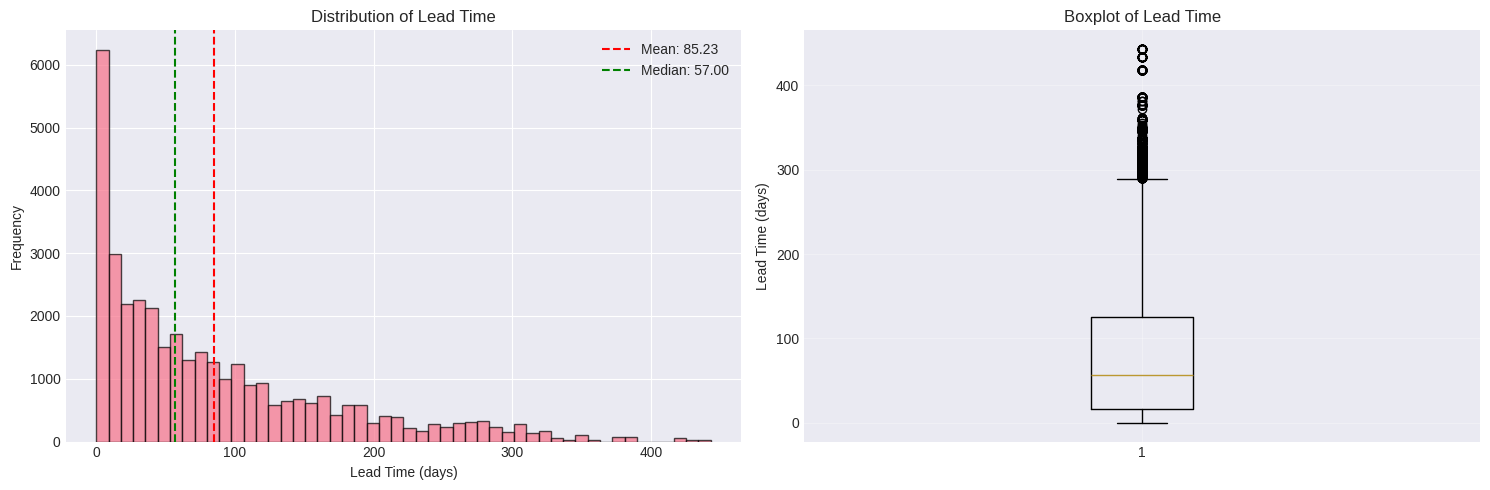

Mean lead time: 85.23 days
Median lead time: 57.00 days
Max lead time: 443 days


In [23]:
# 3.1 Lead Time Analysis
print("\n--- Lead Time Analysis ---")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(data['lead_time'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Lead Time (days)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Lead Time')
axes[0].axvline(data['lead_time'].mean(), color='red', linestyle='--',
                label=f'Mean: {data["lead_time"].mean():.2f}')
axes[0].axvline(data['lead_time'].median(), color='green', linestyle='--',
                label=f'Median: {data["lead_time"].median():.2f}')
axes[0].legend()

# Boxplot
axes[1].boxplot(data['lead_time'], vert=True)
axes[1].set_ylabel('Lead Time (days)')
axes[1].set_title('Boxplot of Lead Time')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean lead time: {data['lead_time'].mean():.2f} days")
print(f"Median lead time: {data['lead_time'].median():.2f} days")
print(f"Max lead time: {data['lead_time'].max()} days")


--- Average Price Per Room Analysis ---


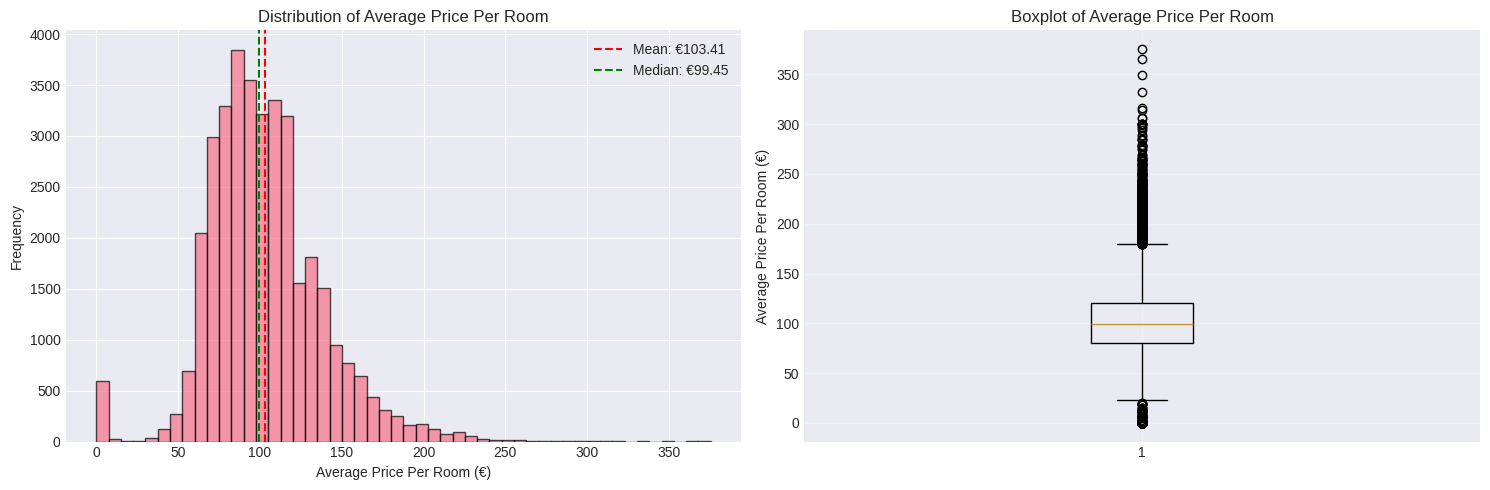

Mean price: €103.41
Median price: €99.45


In [24]:
# 3.2 Average Price Per Room Analysis
print("\n--- Average Price Per Room Analysis ---")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
axes[0].hist(data['avg_price_per_room'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Average Price Per Room (€)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Average Price Per Room')
axes[0].axvline(data['avg_price_per_room'].mean(), color='red', linestyle='--',
                label=f'Mean: €{data["avg_price_per_room"].mean():.2f}')
axes[0].axvline(data['avg_price_per_room'].median(), color='green', linestyle='--',
                label=f'Median: €{data["avg_price_per_room"].median():.2f}')
axes[0].legend()

# Boxplot
axes[1].boxplot(data['avg_price_per_room'], vert=True)
axes[1].set_ylabel('Average Price Per Room (€)')
axes[1].set_title('Boxplot of Average Price Per Room')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean price: €{data['avg_price_per_room'].mean():.2f}")
print(f"Median price: €{data['avg_price_per_room'].median():.2f}")


--- Previous Cancellations Analysis ---


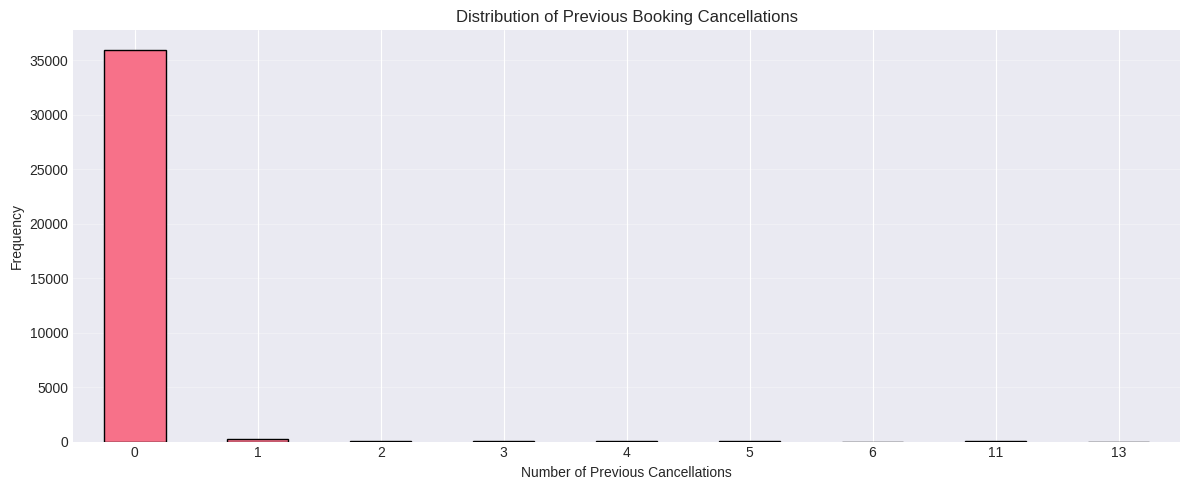

no_of_previous_cancellations
0     35937
1       198
2        46
3        43
4        10
5        11
6         1
11       25
13        4
Name: count, dtype: int64


In [25]:
# 3.3 Previous Cancellations Analysis
print("\n--- Previous Cancellations Analysis ---")

plt.figure(figsize=(12, 5))
data['no_of_previous_cancellations'].value_counts().sort_index().plot(kind='bar',
                                                                       edgecolor='black')
plt.xlabel('Number of Previous Cancellations')
plt.ylabel('Frequency')
plt.title('Distribution of Previous Booking Cancellations')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(data['no_of_previous_cancellations'].value_counts().sort_index())


--- Previous Bookings Not Cancelled Analysis ---


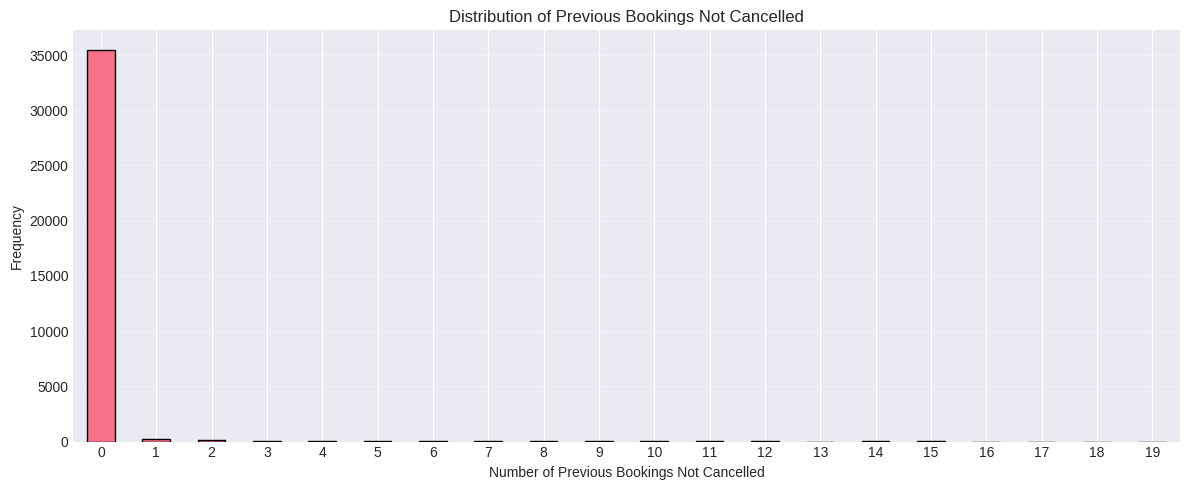

no_of_previous_bookings_not_canceled
0    35463
1      228
2      112
3       80
4       65
5       60
6       36
7       24
8       23
9       19
Name: count, dtype: int64


In [26]:
# 3.4 Previous Bookings Not Cancelled Analysis
print("\n--- Previous Bookings Not Cancelled Analysis ---")

plt.figure(figsize=(12, 5))
prev_not_cancelled = data['no_of_previous_bookings_not_canceled'].value_counts().sort_index()
prev_not_cancelled.head(20).plot(kind='bar', edgecolor='black')
plt.xlabel('Number of Previous Bookings Not Cancelled')
plt.ylabel('Frequency')
plt.title('Distribution of Previous Bookings Not Cancelled')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(data['no_of_previous_bookings_not_canceled'].value_counts().sort_index().head(10))

In [27]:
print(data['no_of_previous_bookings_not_canceled'].value_counts().sort_index().head(10))

no_of_previous_bookings_not_canceled
0    35463
1      228
2      112
3       80
4       65
5       60
6       36
7       24
8       23
9       19
Name: count, dtype: int64



--- Number of Adults Analysis ---


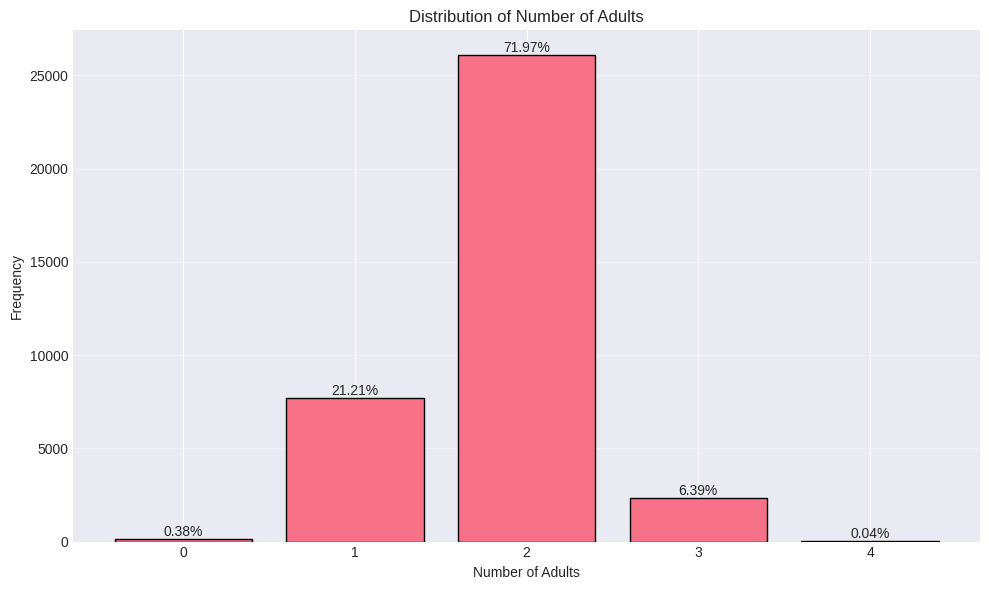


72.0% of bookings were for 2 adults
21.2% of bookings were for 1 adult


In [28]:
# 3.5 Number of Adults
print("\n--- Number of Adults Analysis ---")

plt.figure(figsize=(10, 6))
adults_counts = data['no_of_adults'].value_counts().sort_index()
adults_pct = (adults_counts / len(data) * 100).round(2)

bars = plt.bar(adults_counts.index, adults_counts.values, edgecolor='black')
plt.xlabel('Number of Adults')
plt.ylabel('Frequency')
plt.title('Distribution of Number of Adults')
plt.xticks(adults_counts.index)

# Add percentage labels on bars
for i, (bar, pct) in enumerate(zip(bars, adults_pct)):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{pct}%',
             ha='center', va='bottom', fontsize=10)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"\n{adults_pct[2]:.1f}% of bookings were for 2 adults")
print(f"{adults_pct[1]:.1f}% of bookings were for 1 adult")


--- Number of Children Analysis ---


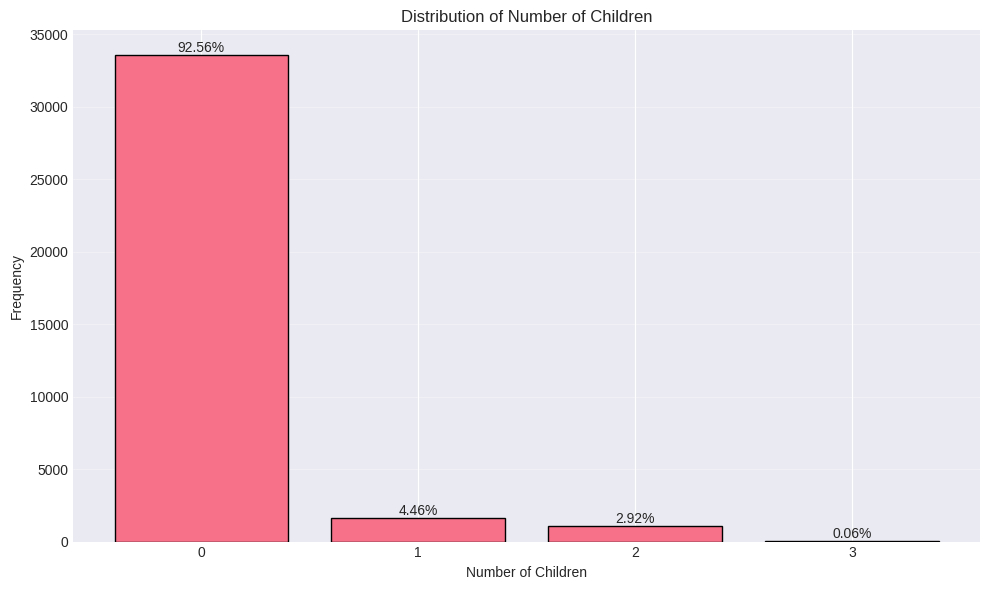


92.6% of bookings had no children


In [29]:
# 3.6 Number of Children
print("\n--- Number of Children Analysis ---")

plt.figure(figsize=(10, 6))
children_counts = data['no_of_children'].value_counts().sort_index()
children_pct = (children_counts / len(data) * 100).round(2)

bars = plt.bar(children_counts.index, children_counts.values, edgecolor='black')
plt.xlabel('Number of Children')
plt.ylabel('Frequency')
plt.title('Distribution of Number of Children')
plt.xticks(children_counts.index)

# Add percentage labels
for i, (bar, pct) in enumerate(zip(bars, children_pct)):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{pct}%',
             ha='center', va='bottom', fontsize=10)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"\n{children_pct[0]:.1f}% of bookings had no children")


--- Number of Week Nights Analysis ---


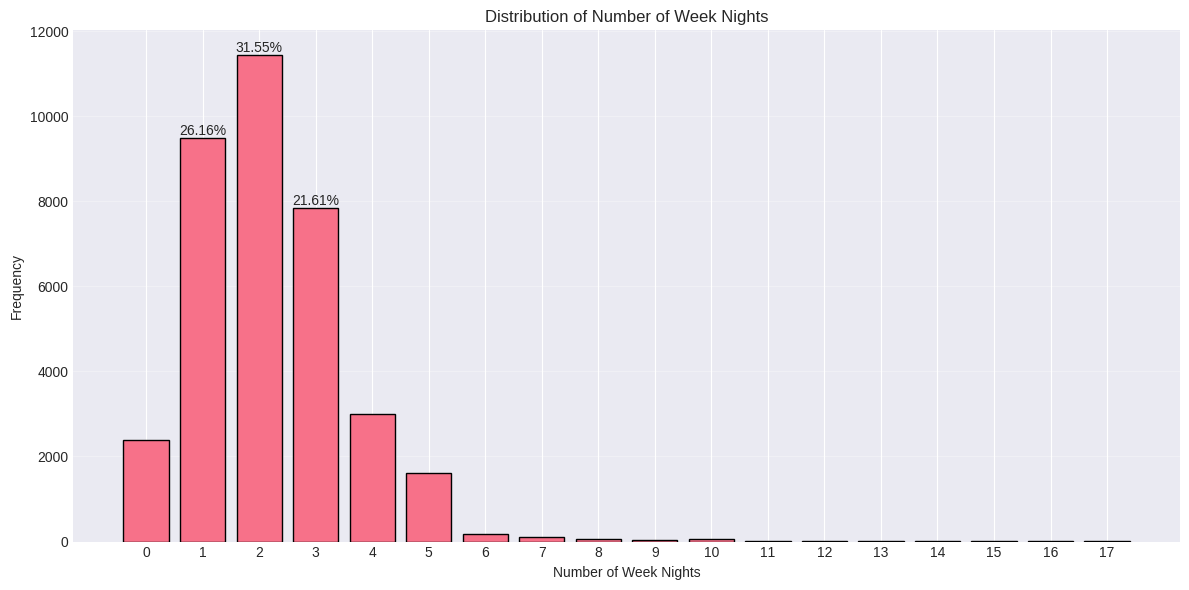

Most bookings: 2 nights (31.6%), 1 night (26.2%), 3 nights (21.6%)


In [30]:
# 3.7 Number of Week Nights
print("\n--- Number of Week Nights Analysis ---")

plt.figure(figsize=(12, 6))
week_nights_counts = data['no_of_week_nights'].value_counts().sort_index()
week_nights_pct = (week_nights_counts / len(data) * 100).round(2)

bars = plt.bar(week_nights_counts.index, week_nights_counts.values, edgecolor='black')
plt.xlabel('Number of Week Nights')
plt.ylabel('Frequency')
plt.title('Distribution of Number of Week Nights')
plt.xticks(week_nights_counts.index)

# Add percentage labels for top categories
for idx in [1, 2, 3]:
    if idx in week_nights_counts.index:
        bar_idx = list(week_nights_counts.index).index(idx)
        height = week_nights_counts[idx]
        plt.text(idx, height,
                 f'{week_nights_pct[idx]}%',
                 ha='center', va='bottom', fontsize=10)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"Most bookings: 2 nights ({week_nights_pct[2]:.1f}%), 1 night ({week_nights_pct[1]:.1f}%), 3 nights ({week_nights_pct[3]:.1f}%)")


--- Number of Weekend Nights Analysis ---


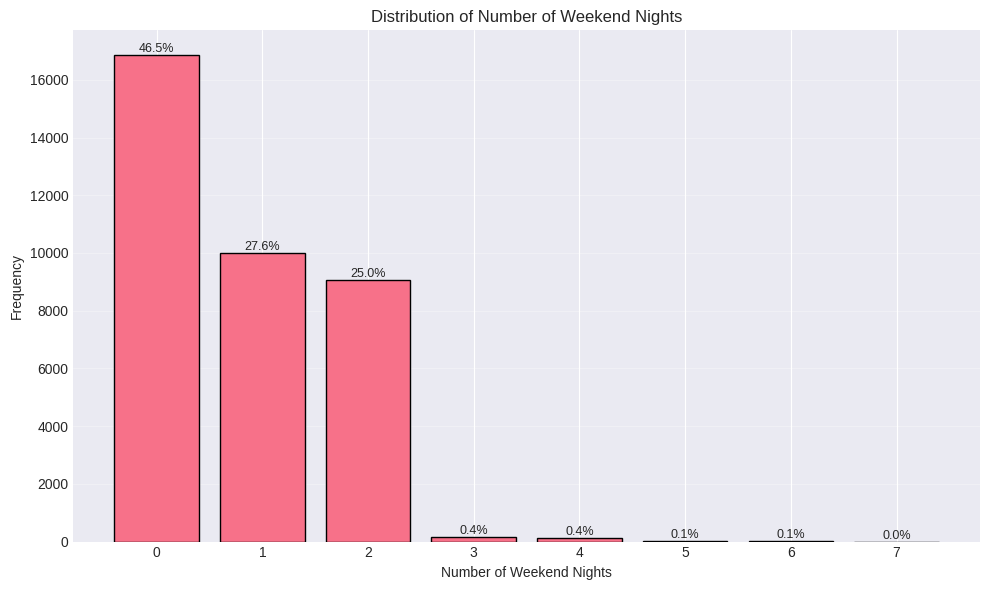

46.5% of customers don't plan to spend weekend in hotel


In [31]:
# 3.8 Number of Weekend Nights
print("\n--- Number of Weekend Nights Analysis ---")

plt.figure(figsize=(10, 6))
weekend_nights_counts = data['no_of_weekend_nights'].value_counts().sort_index()
weekend_nights_pct = (weekend_nights_counts / len(data) * 100).round(2)

bars = plt.bar(weekend_nights_counts.index, weekend_nights_counts.values, edgecolor='black')
plt.xlabel('Number of Weekend Nights')
plt.ylabel('Frequency')
plt.title('Distribution of Number of Weekend Nights')
plt.xticks(weekend_nights_counts.index)

# Add percentage labels
for idx in weekend_nights_counts.index:
    height = weekend_nights_counts[idx]
    plt.text(idx, height,
             f'{weekend_nights_pct[idx]:.1f}%',
             ha='center', va='bottom', fontsize=9)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"{weekend_nights_pct[0]:.1f}% of customers don't plan to spend weekend in hotel")


--- Required Car Parking Space Analysis ---


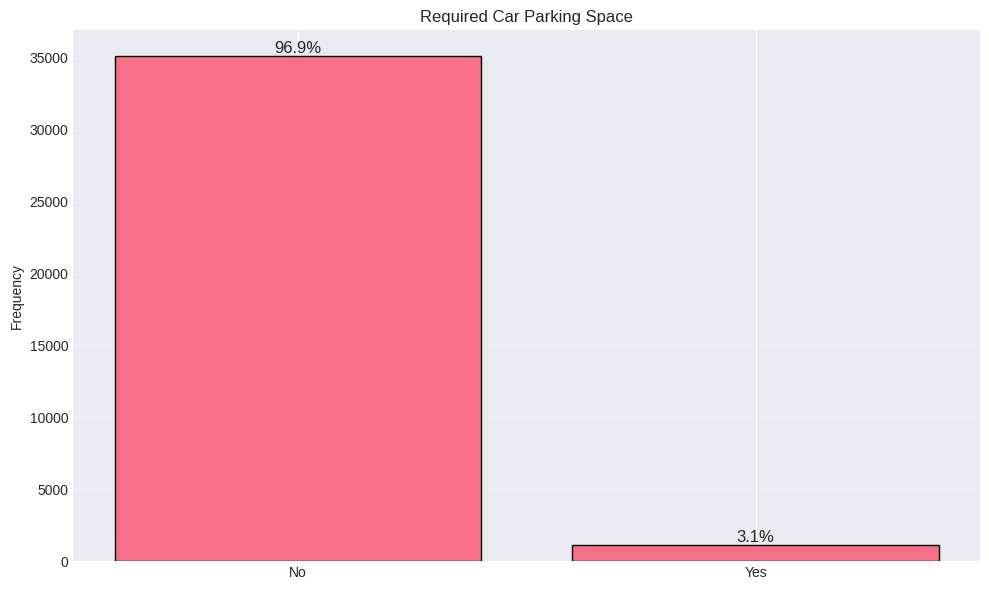


96.9% of customers don't require parking space


In [32]:
# 3.9 Required Car Parking Space
print("\n--- Required Car Parking Space Analysis ---")

plt.figure(figsize=(10, 6))
parking_counts = data['required_car_parking_space'].value_counts().sort_index()
parking_pct = (parking_counts / len(data) * 100).round(2)

bars = plt.bar(['No', 'Yes'], parking_counts.values, edgecolor='black')
plt.ylabel('Frequency')
plt.title('Required Car Parking Space')

# Add percentage labels
for i, (bar, pct) in enumerate(zip(bars, parking_pct)):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{pct}%',
             ha='center', va='bottom', fontsize=12)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"\n{parking_pct[0]:.1f}% of customers don't require parking space")


--- Type of Meal Plan Analysis ---


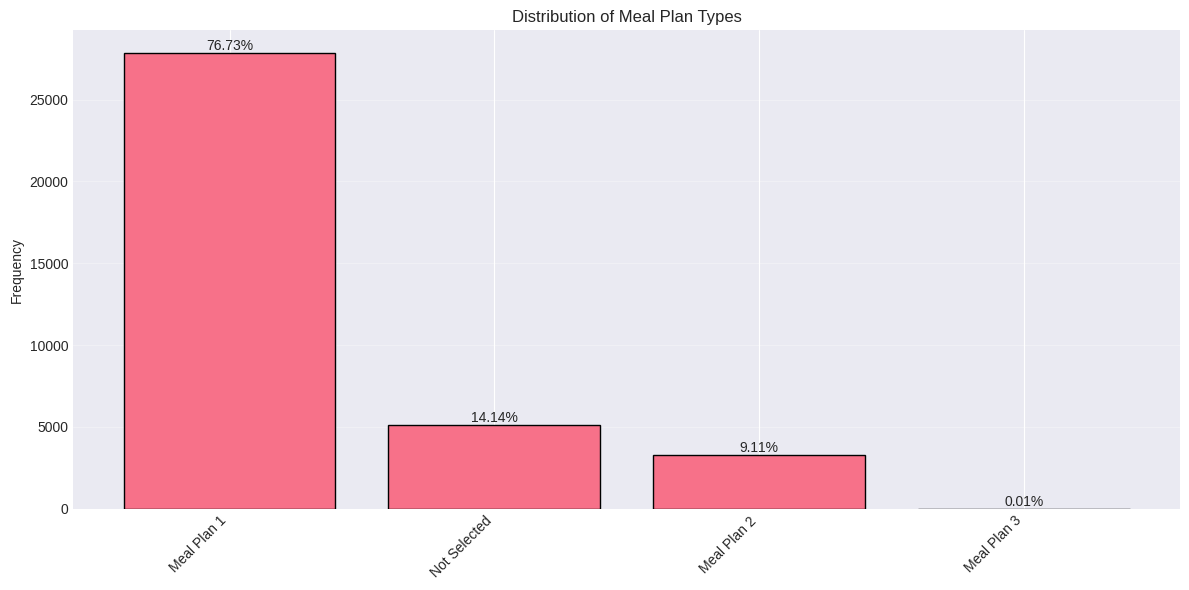


Meal Plan Distribution:
Meal Plan 1: 76.73%
Not Selected: 14.14%
Meal Plan 2: 9.11%
Meal Plan 3: 0.01%


In [33]:
# 3.10 Type of Meal Plan
print("\n--- Type of Meal Plan Analysis ---")

plt.figure(figsize=(12, 6))
meal_counts = data['type_of_meal_plan'].value_counts()
meal_pct = (meal_counts / len(data) * 100).round(2)

bars = plt.bar(range(len(meal_counts)), meal_counts.values, edgecolor='black')
plt.xticks(range(len(meal_counts)), meal_counts.index, rotation=45, ha='right')
plt.ylabel('Frequency')
plt.title('Distribution of Meal Plan Types')

# Add percentage labels
for i, (bar, pct) in enumerate(zip(bars, meal_pct)):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{pct}%',
             ha='center', va='bottom', fontsize=10)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nMeal Plan Distribution:")
for plan, pct in meal_pct.items():
    print(f"{plan}: {pct}%")


--- Room Type Reserved Analysis ---


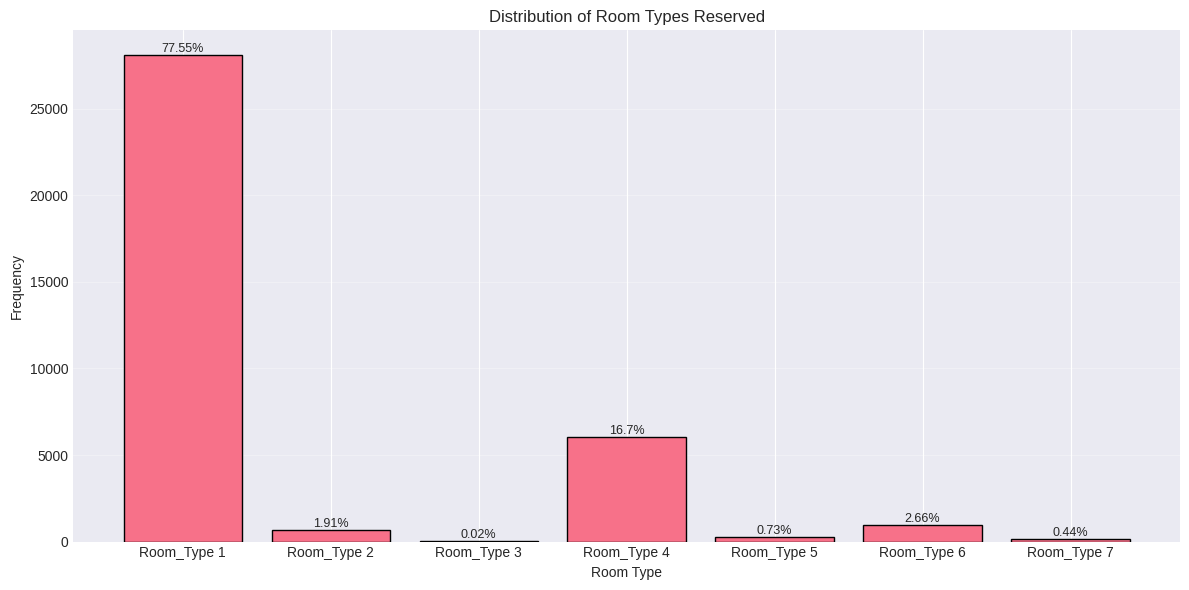


77% of customers booked Room_Type 1, 17% booked Room_Type 4


In [34]:
# 3.11 Room Type Reserved
print("\n--- Room Type Reserved Analysis ---")

plt.figure(figsize=(12, 6))
room_counts = data['room_type_reserved'].value_counts().sort_index()
room_pct = (room_counts / len(data) * 100).round(2)

bars = plt.bar(room_counts.index, room_counts.values, edgecolor='black')
plt.xlabel('Room Type')
plt.ylabel('Frequency')
plt.title('Distribution of Room Types Reserved')
plt.xticks(rotation=0)

# Add percentage labels
for i, (room_type, pct) in enumerate(zip(room_counts.index, room_pct)):
    height = room_counts[room_type]
    plt.text(i, height,
             f'{pct}%',
             ha='center', va='bottom', fontsize=9)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"\n77% of customers booked Room_Type 1, 17% booked Room_Type 4")


--- Arrival Month Analysis ---


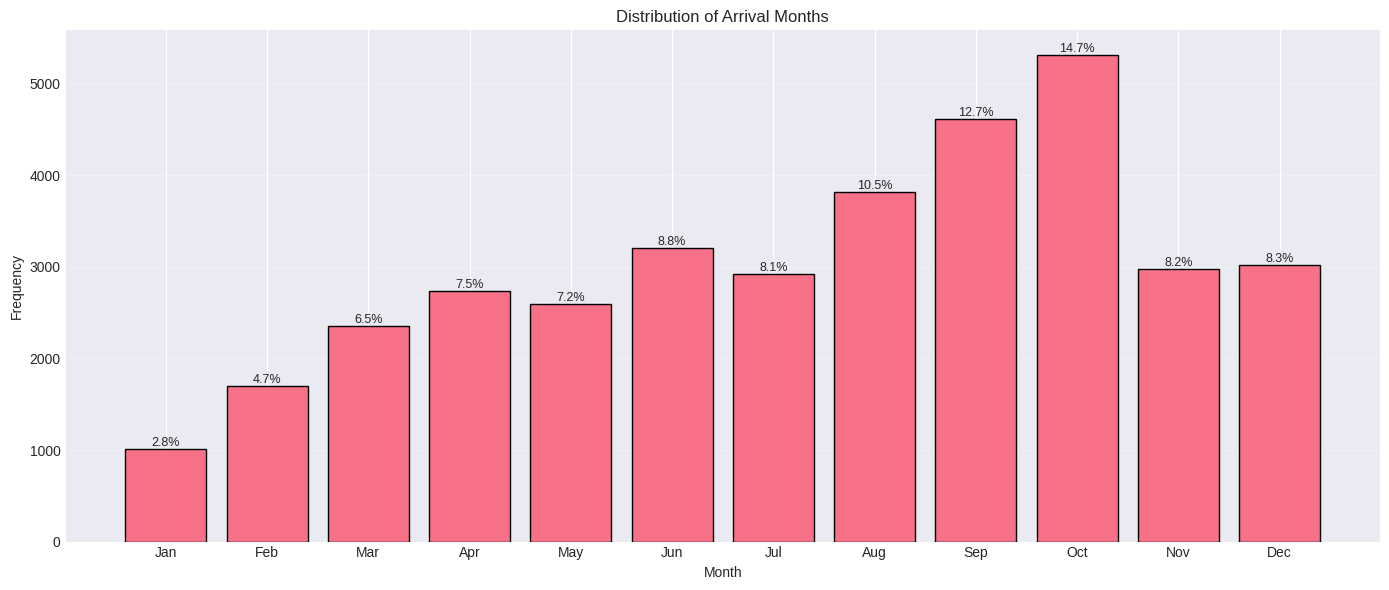


Busiest month: October (14.7%)


In [35]:
# 3.12 Arrival Month
print("\n--- Arrival Month Analysis ---")

plt.figure(figsize=(14, 6))
month_counts = data['arrival_month'].value_counts().sort_index()
month_pct = (month_counts / len(data) * 100).round(2)

bars = plt.bar(range(1, 13), [month_counts.get(i, 0) for i in range(1, 13)], edgecolor='black')
plt.xlabel('Month')
plt.ylabel('Frequency')
plt.title('Distribution of Arrival Months')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                           'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

# Add percentage labels
for i in range(1, 13):
    if i in month_counts.index:
        height = month_counts[i]
        pct = month_pct[i]
        plt.text(i, height, f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"\nBusiest month: October ({month_pct[10]:.1f}%)")


--- Market Segment Type Analysis ---


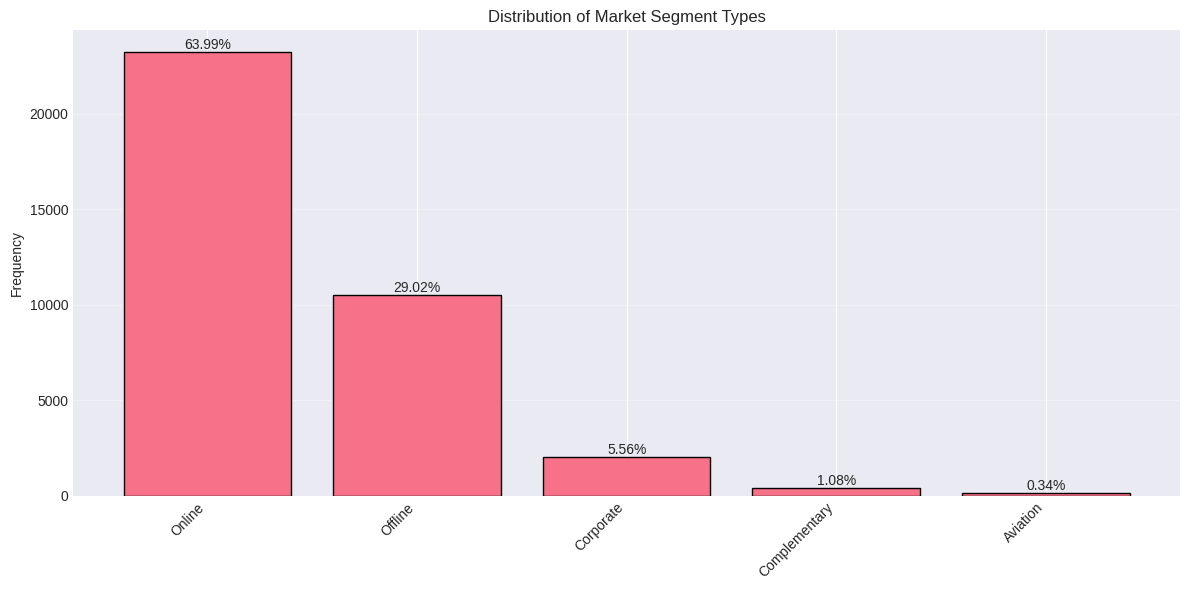


Market Segment Distribution:
Online: 63.99%
Offline: 29.02%
Corporate: 5.56%
Complementary: 1.08%
Aviation: 0.34%


In [36]:
# 3.13 Market Segment Type
print("\n--- Market Segment Type Analysis ---")

plt.figure(figsize=(12, 6))
segment_counts = data['market_segment_type'].value_counts()
segment_pct = (segment_counts / len(data) * 100).round(2)

bars = plt.bar(range(len(segment_counts)), segment_counts.values, edgecolor='black')
plt.xticks(range(len(segment_counts)), segment_counts.index, rotation=45, ha='right')
plt.ylabel('Frequency')
plt.title('Distribution of Market Segment Types')

# Add percentage labels
for i, (bar, pct) in enumerate(zip(bars, segment_pct)):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{pct}%',
             ha='center', va='bottom', fontsize=10)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nMarket Segment Distribution:")
for segment, pct in segment_pct.items():
    print(f"{segment}: {pct}%")


--- Number of Special Requests Analysis ---


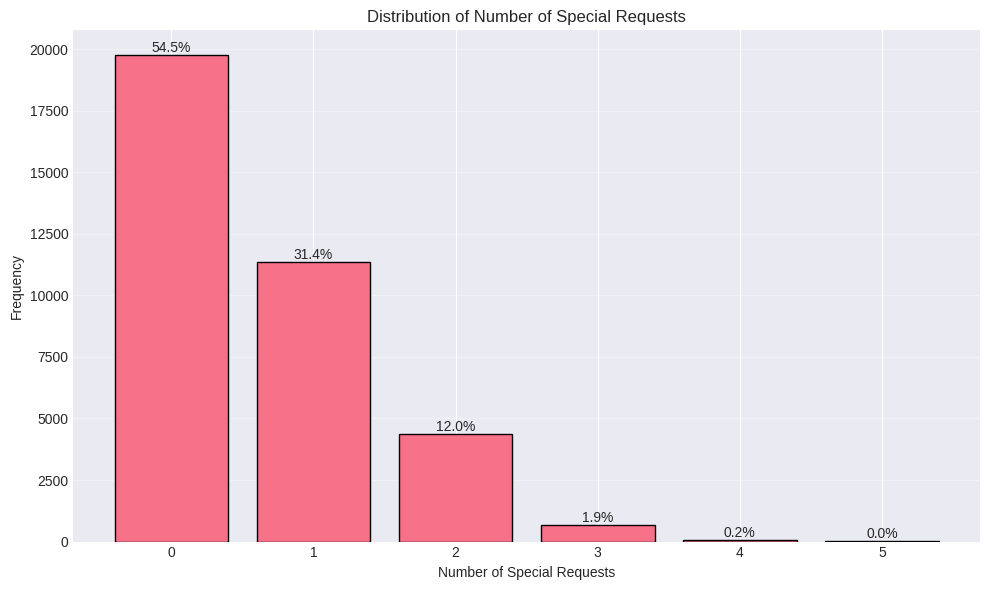


54.5% of customers made no special requests


In [37]:
# 3.14 Number of Special Requests
print("\n--- Number of Special Requests Analysis ---")

plt.figure(figsize=(10, 6))
requests_counts = data['no_of_special_requests'].value_counts().sort_index()
requests_pct = (requests_counts / len(data) * 100).round(2)

bars = plt.bar(requests_counts.index, requests_counts.values, edgecolor='black')
plt.xlabel('Number of Special Requests')
plt.ylabel('Frequency')
plt.title('Distribution of Number of Special Requests')
plt.xticks(requests_counts.index)

# Add percentage labels
for idx in requests_counts.index:
    height = requests_counts[idx]
    plt.text(idx, height,
             f'{requests_pct[idx]:.1f}%',
             ha='center', va='bottom', fontsize=10)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"\n{requests_pct[0]:.1f}% of customers made no special requests")


--- Booking Status Analysis ---


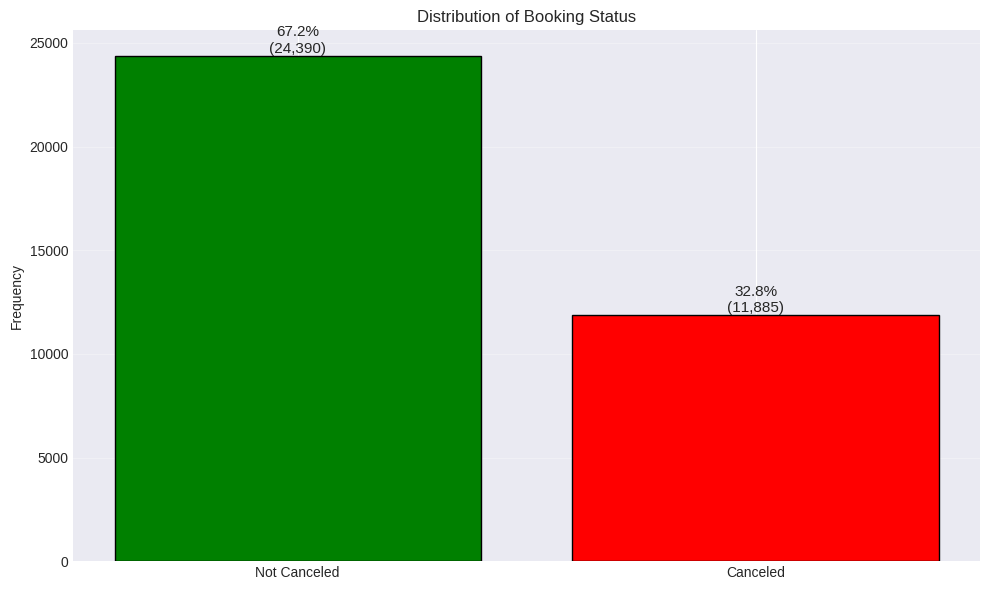


Cancellation Rate: 32.8%
Total Cancellations: 11,885
Total Not Cancelled: 24,390


In [38]:
# 3.15 Booking Status
print("\n--- Booking Status Analysis ---")

plt.figure(figsize=(10, 6))
status_counts = data['booking_status'].value_counts()
status_pct = (status_counts / len(data) * 100).round(2)

bars = plt.bar(['Not Canceled', 'Canceled'],
               [status_counts[0], status_counts[1]],
               edgecolor='black',
               color=['green', 'red'])
plt.ylabel('Frequency')
plt.title('Distribution of Booking Status')

# Add percentage and count labels
for i, (bar, status) in enumerate(zip(bars, [0, 1])):
    height = bar.get_height()
    pct = status_pct[status]
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{pct:.1f}%\n({int(height):,})',
             ha='center', va='bottom', fontsize=11)

plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print(f"\nCancellation Rate: {status_pct[1]:.1f}%")
print(f"Total Cancellations: {status_counts[1]:,}")
print(f"Total Not Cancelled: {status_counts[0]:,}")


--- Correlation Matrix for Numerical Variables ---


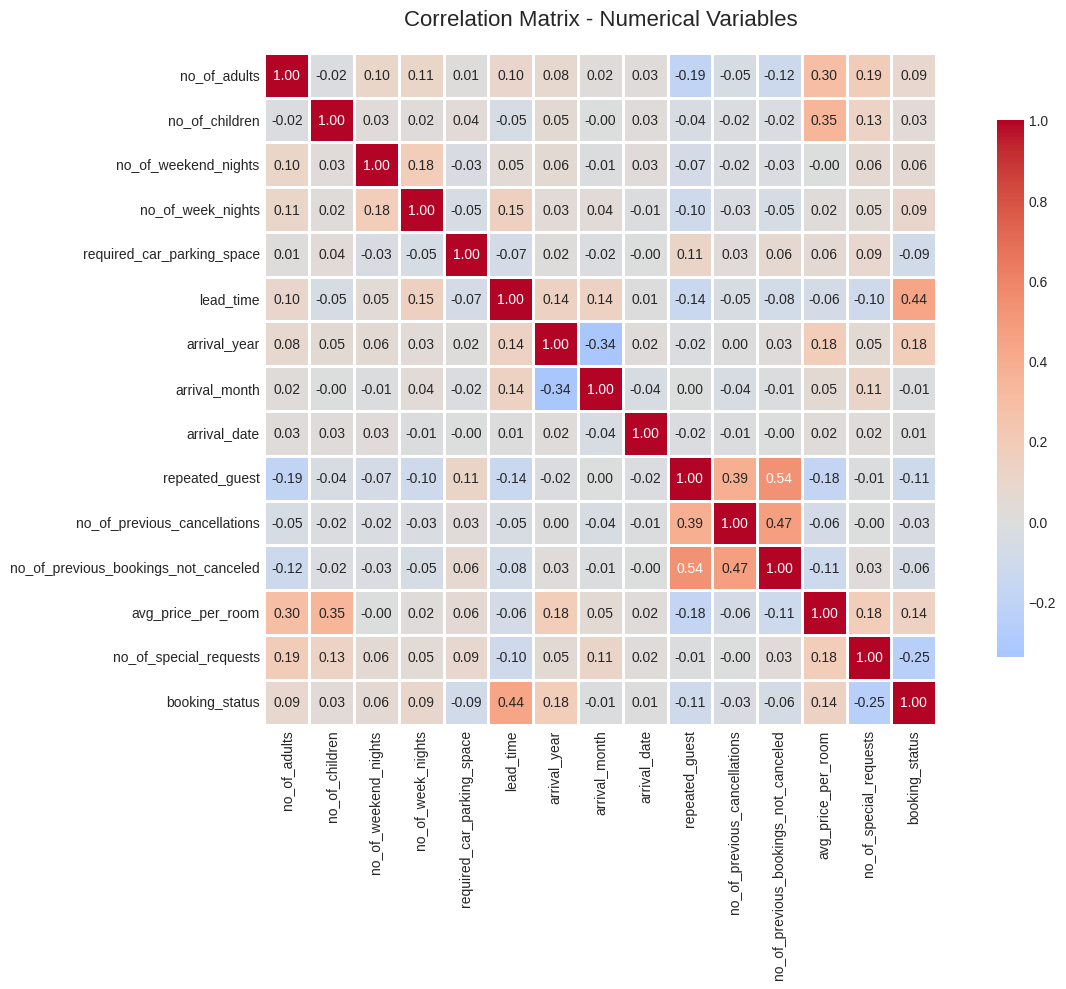


Key Correlations with booking_status:
booking_status                          1.000
lead_time                               0.439
arrival_year                            0.180
avg_price_per_room                      0.142
no_of_week_nights                       0.093
no_of_adults                            0.087
no_of_weekend_nights                    0.062
no_of_children                          0.034
arrival_date                            0.011
arrival_month                          -0.011
no_of_previous_cancellations           -0.034
no_of_previous_bookings_not_canceled   -0.060
required_car_parking_space             -0.086
repeated_guest                         -0.107
no_of_special_requests                 -0.253
Name: booking_status, dtype: float64


In [39]:
# 4.1 Correlation Matrix
print("\n--- Correlation Matrix for Numerical Variables ---")

numerical_cols = data.select_dtypes(include=[np.number]).columns.tolist()
# Remove Booking_ID and other ID columns if present
numerical_cols = [col for col in numerical_cols if 'id' not in col.lower()]

plt.figure(figsize=(14, 10))
correlation_matrix = data[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix - Numerical Variables', fontsize=16, pad=20)
plt.tight_layout()
plt.show()

print("\nKey Correlations with booking_status:")
booking_corr = correlation_matrix['booking_status'].sort_values(ascending=False)
print(booking_corr)


--- Average Price Per Room vs Market Segment Type ---


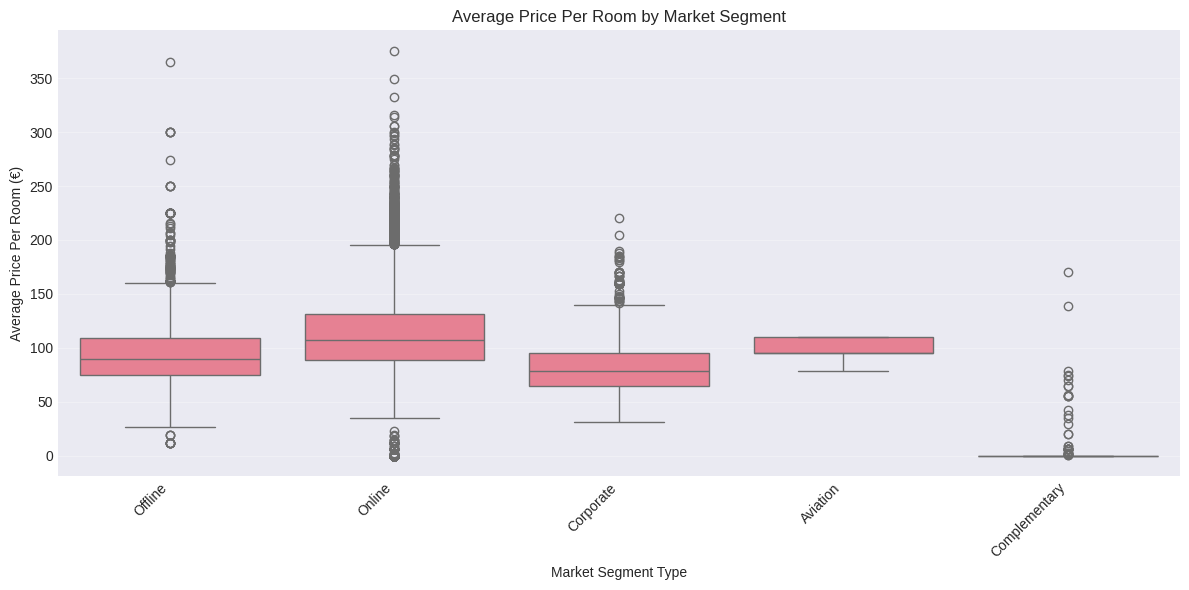


Average Price by Market Segment:
                       mean     50%    std
market_segment_type                       
Aviation            100.704  95.000  8.538
Complementary         3.142   0.000 15.513
Corporate            82.912  79.000 23.690
Offline              91.598  90.000 24.626
Online              112.257 107.100 35.220


In [40]:
# 4.2 Average Price Per Room vs Market Segment Type
print("\n--- Average Price Per Room vs Market Segment Type ---")

plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='market_segment_type', y='avg_price_per_room')
plt.xlabel('Market Segment Type')
plt.ylabel('Average Price Per Room (€)')
plt.title('Average Price Per Room by Market Segment')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# Summary statistics
print("\nAverage Price by Market Segment:")
print(data.groupby('market_segment_type')['avg_price_per_room'].describe()[['mean', '50%', 'std']])


--- Booking Status vs Market Segment Type ---

Cancellation Rate by Market Segment (%):
booking_status            0      1
market_segment_type               
Aviation             70.400 29.600
Complementary       100.000  0.000
Corporate            89.090 10.910
Offline              70.050 29.950
Online               63.490 36.510


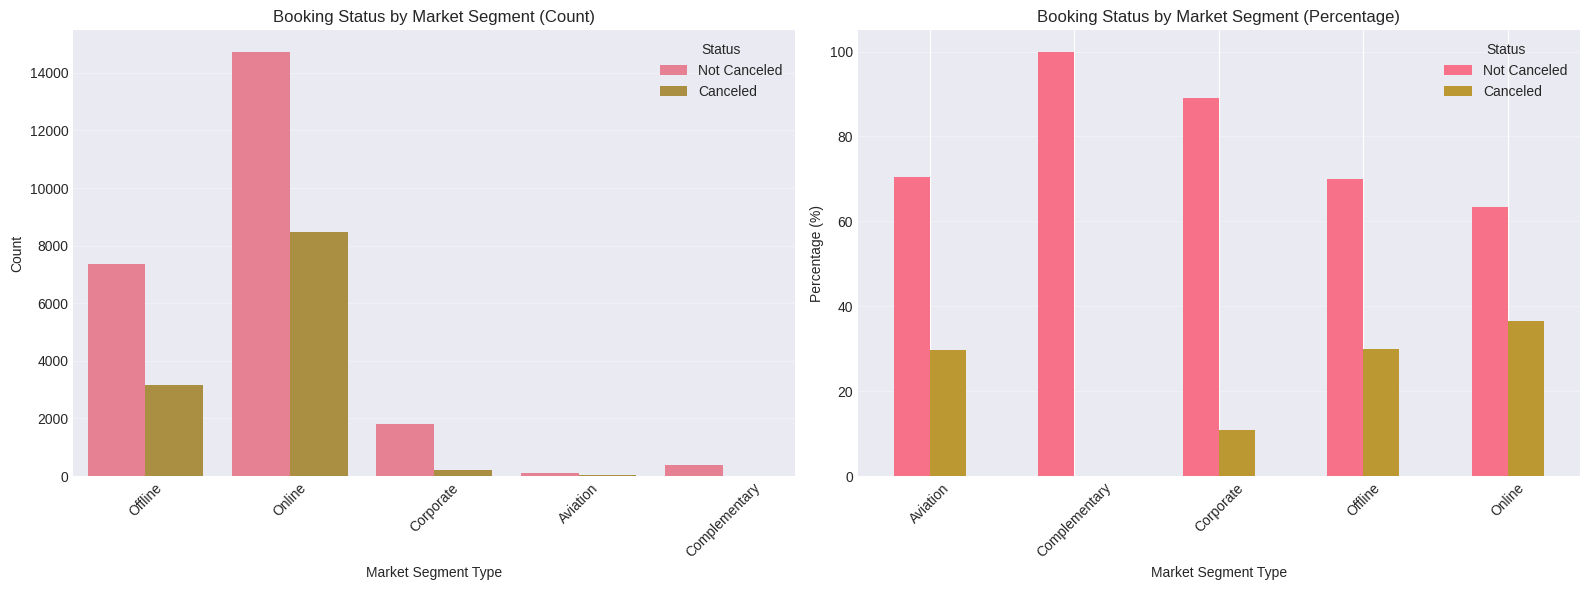

In [41]:
# 4.3 Booking Status vs Market Segment Type
print("\n--- Booking Status vs Market Segment Type ---")

# Create crosstab
segment_status = pd.crosstab(data['market_segment_type'],
                              data['booking_status'],
                              normalize='index') * 100

print("\nCancellation Rate by Market Segment (%):")
print(segment_status.round(2))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Count plot
sns.countplot(data=data, x='market_segment_type', hue='booking_status', ax=axes[0])
axes[0].set_xlabel('Market Segment Type')
axes[0].set_ylabel('Count')
axes[0].set_title('Booking Status by Market Segment (Count)')
axes[0].legend(title='Status', labels=['Not Canceled', 'Canceled'])
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3, axis='y')

# Percentage plot
segment_status.plot(kind='bar', stacked=False, ax=axes[1])
axes[1].set_xlabel('Market Segment Type')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('Booking Status by Market Segment (Percentage)')
axes[1].legend(title='Status', labels=['Not Canceled', 'Canceled'])
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


--- Booking Status vs Number of Special Requests ---

Cancellation Rate by Number of Special Requests (%):
booking_status               0      1
no_of_special_requests               
0                       56.790 43.210
1                       76.230 23.770
2                       85.400 14.600
3                      100.000  0.000
4                      100.000  0.000
5                      100.000  0.000


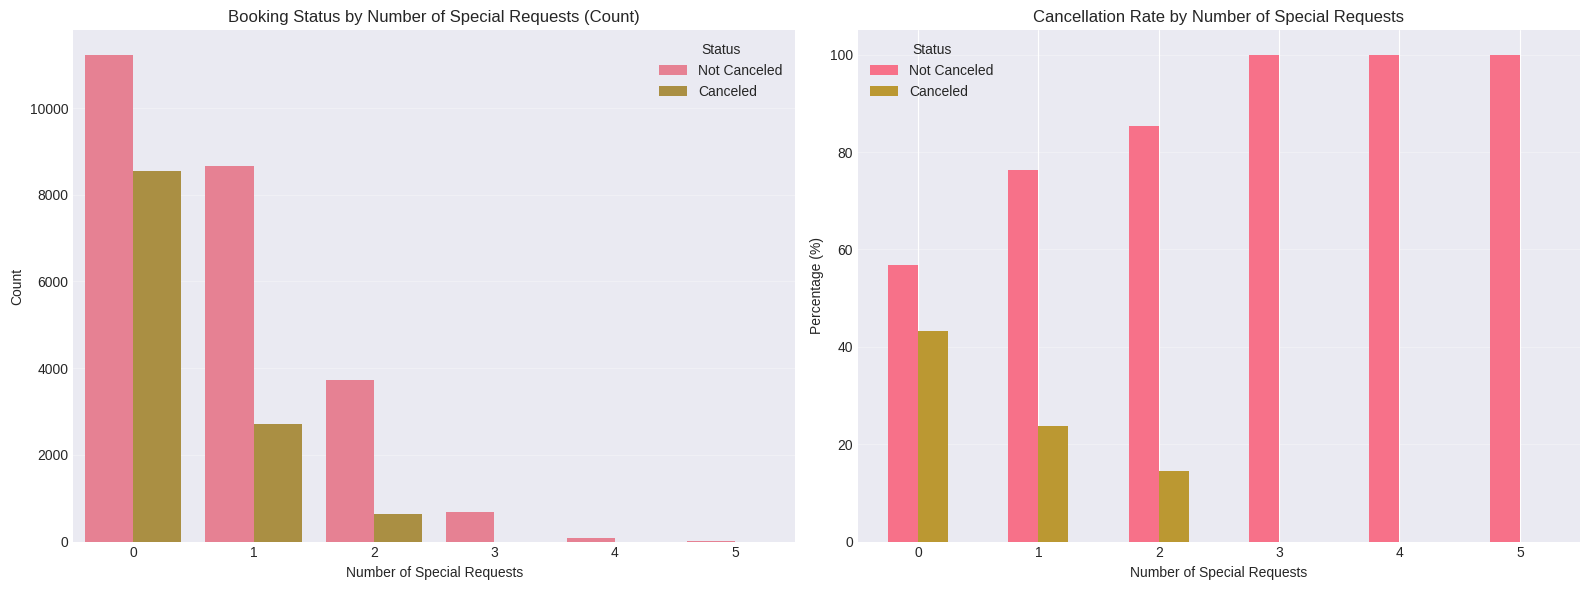

In [42]:
# 4.4 Booking Status vs Number of Special Requests
print("\n--- Booking Status vs Number of Special Requests ---")

# Create crosstab
requests_status = pd.crosstab(data['no_of_special_requests'],
                               data['booking_status'],
                               normalize='index') * 100

print("\nCancellation Rate by Number of Special Requests (%):")
print(requests_status.round(2))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Count plot
sns.countplot(data=data, x='no_of_special_requests', hue='booking_status', ax=axes[0])
axes[0].set_xlabel('Number of Special Requests')
axes[0].set_ylabel('Count')
axes[0].set_title('Booking Status by Number of Special Requests (Count)')
axes[0].legend(title='Status', labels=['Not Canceled', 'Canceled'])
axes[0].grid(True, alpha=0.3, axis='y')

# Percentage plot
requests_status.plot(kind='bar', ax=axes[1])
axes[1].set_xlabel('Number of Special Requests')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('Cancellation Rate by Number of Special Requests')
axes[1].legend(title='Status', labels=['Not Canceled', 'Canceled'])
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()


--- Average Price Per Room vs Number of Special Requests ---


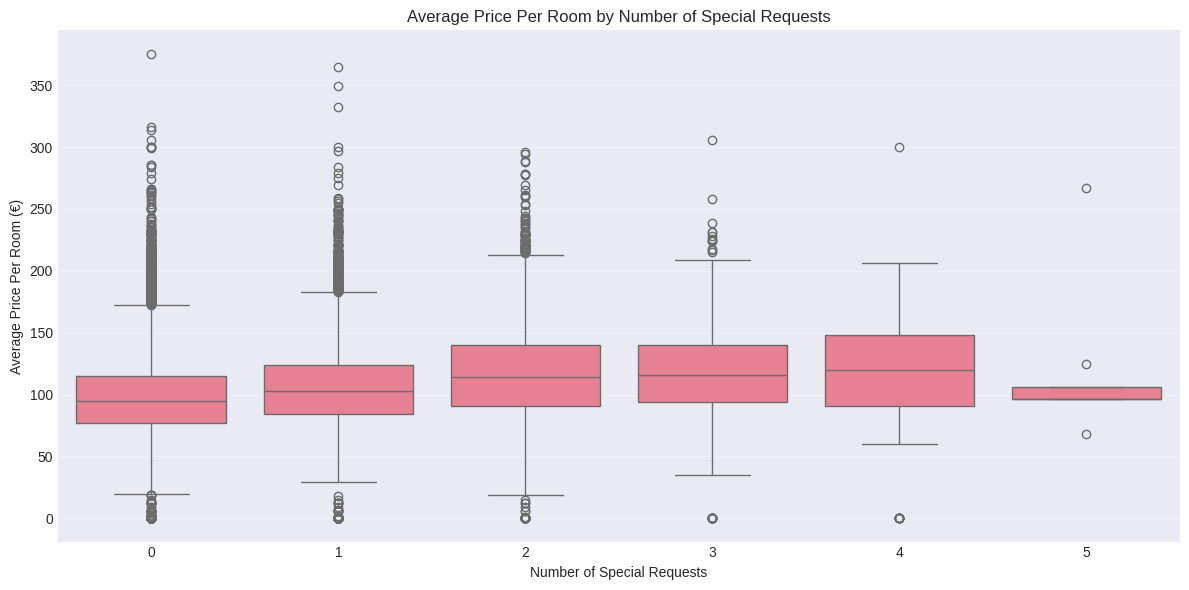


Median Price by Number of Special Requests:
no_of_special_requests
0    95.000
1   103.000
2   114.400
3   116.100
4   120.000
5    96.600
Name: avg_price_per_room, dtype: float64


In [43]:
# 4.5 Average Price Per Room vs Number of Special Requests
print("\n--- Average Price Per Room vs Number of Special Requests ---")

plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x='no_of_special_requests', y='avg_price_per_room')
plt.xlabel('Number of Special Requests')
plt.ylabel('Average Price Per Room (€)')
plt.title('Average Price Per Room by Number of Special Requests')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nMedian Price by Number of Special Requests:")
print(data.groupby('no_of_special_requests')['avg_price_per_room'].median())


--- Average Price Per Room vs Booking Status ---


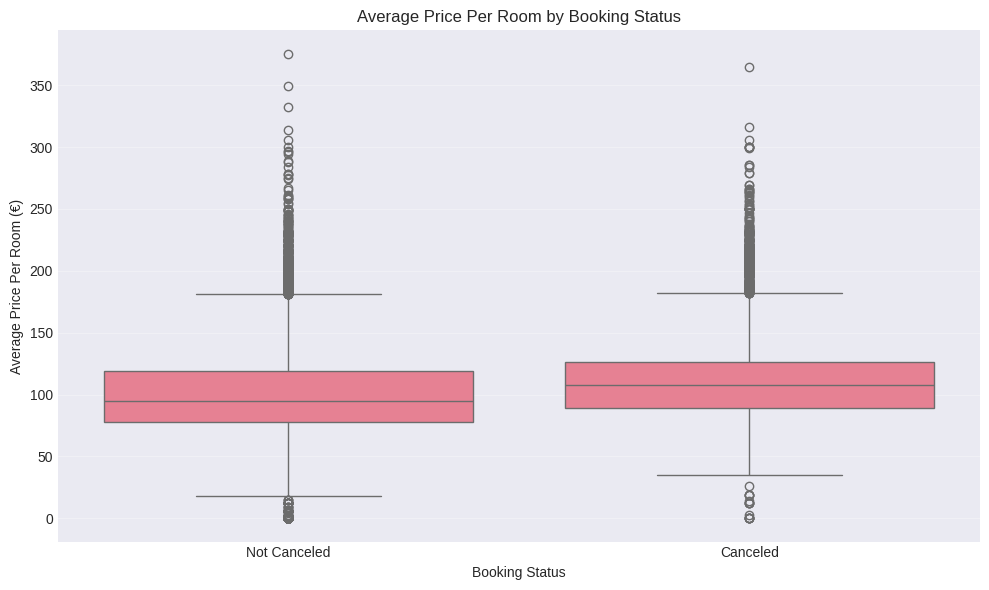


Price Statistics by Booking Status:
                  mean     50%    std
booking_status                       
0               99.931  95.000 35.872
1              110.560 108.000 32.029


In [44]:
# 4.6 Average Price Per Room vs Booking Status
print("\n--- Average Price Per Room vs Booking Status ---")

plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='booking_status', y='avg_price_per_room')
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.xlabel('Booking Status')
plt.ylabel('Average Price Per Room (€)')
plt.title('Average Price Per Room by Booking Status')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nPrice Statistics by Booking Status:")
print(data.groupby('booking_status')['avg_price_per_room'].describe()[['mean', '50%', 'std']])


--- Lead Time vs Booking Status ---


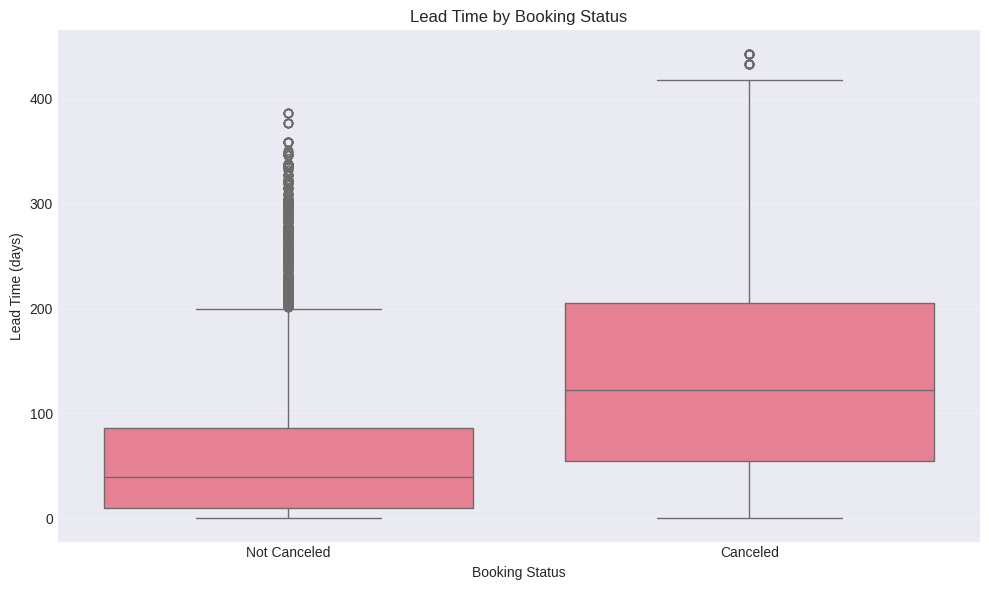


Lead Time Statistics by Booking Status:
                  mean     50%    std
booking_status                       
0               58.927  39.000 64.029
1              139.215 122.000 98.948


In [45]:
# 4.7 Lead Time vs Booking Status
print("\n--- Lead Time vs Booking Status ---")

plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='booking_status', y='lead_time')
plt.xticks([0, 1], ['Not Canceled', 'Canceled'])
plt.xlabel('Booking Status')
plt.ylabel('Lead Time (days)')
plt.title('Lead Time by Booking Status')
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nLead Time Statistics by Booking Status:")
print(data.groupby('booking_status')['lead_time'].describe()[['mean', '50%', 'std']])


--- Number of Family Members vs Booking Status ---

Cancellation Rate by Number of Family Members (%):
booking_status            0      1
no_of_family_members              
1                    76.050 23.950
2                    65.420 34.580
3                    63.850 36.150
4                    56.410 43.590
5                    64.710 35.290


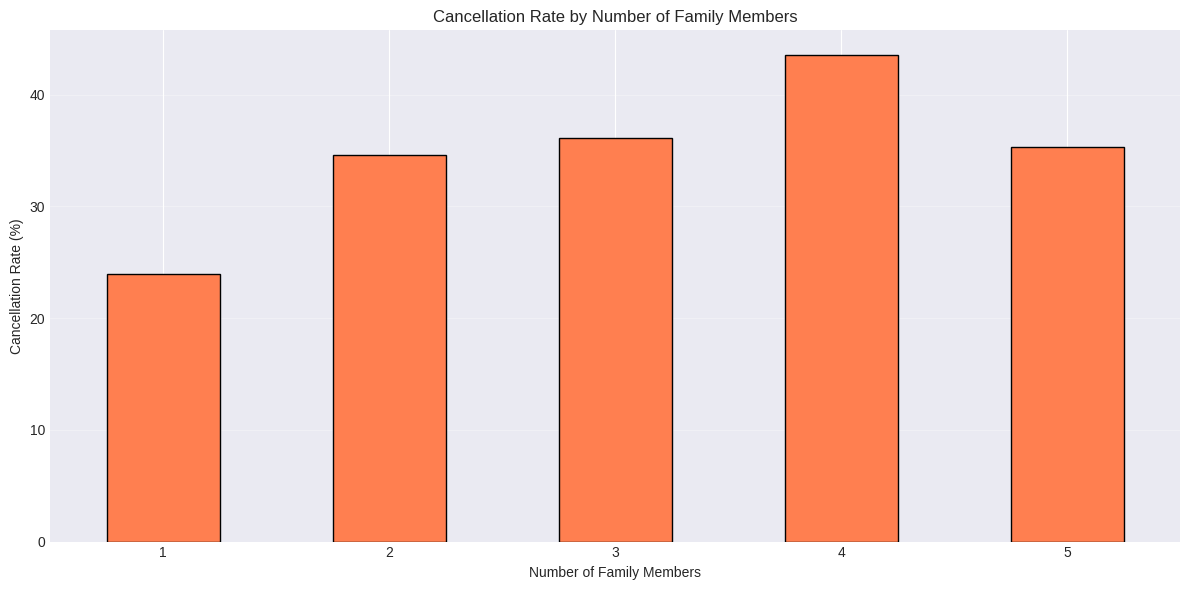

In [46]:
# 4.8 Number of Family Members vs Booking Status
print("\n--- Number of Family Members vs Booking Status ---")

# Create family members column
data['no_of_family_members'] = data['no_of_adults'] + data['no_of_children']

# Filter for families (at least 1 member)
family_data = data[data['no_of_family_members'] > 0].copy()

# Create crosstab
family_status = pd.crosstab(family_data['no_of_family_members'],
                             family_data['booking_status'],
                             normalize='index') * 100

print("\nCancellation Rate by Number of Family Members (%):")
print(family_status.round(2))

# Visualization
plt.figure(figsize=(12, 6))
family_status[1].plot(kind='bar', color='coral', edgecolor='black')
plt.xlabel('Number of Family Members')
plt.ylabel('Cancellation Rate (%)')
plt.title('Cancellation Rate by Number of Family Members')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()


--- Total Stay Days vs Booking Status ---

Cancellation Rate by Total Stay Days (%):
booking_status       0      1
total_stay_days              
1               77.800 22.200
2               65.780 34.220
3               64.330 35.670
4               67.060 32.940
5               68.210 31.790
6               54.900 45.100
7               60.640 39.360
8               55.870 44.130
9               52.250 47.750
10              46.790 53.210
11              61.540 38.460
12              37.500 62.500
13              16.670 83.330
14              15.620 84.380
15              16.130 83.870


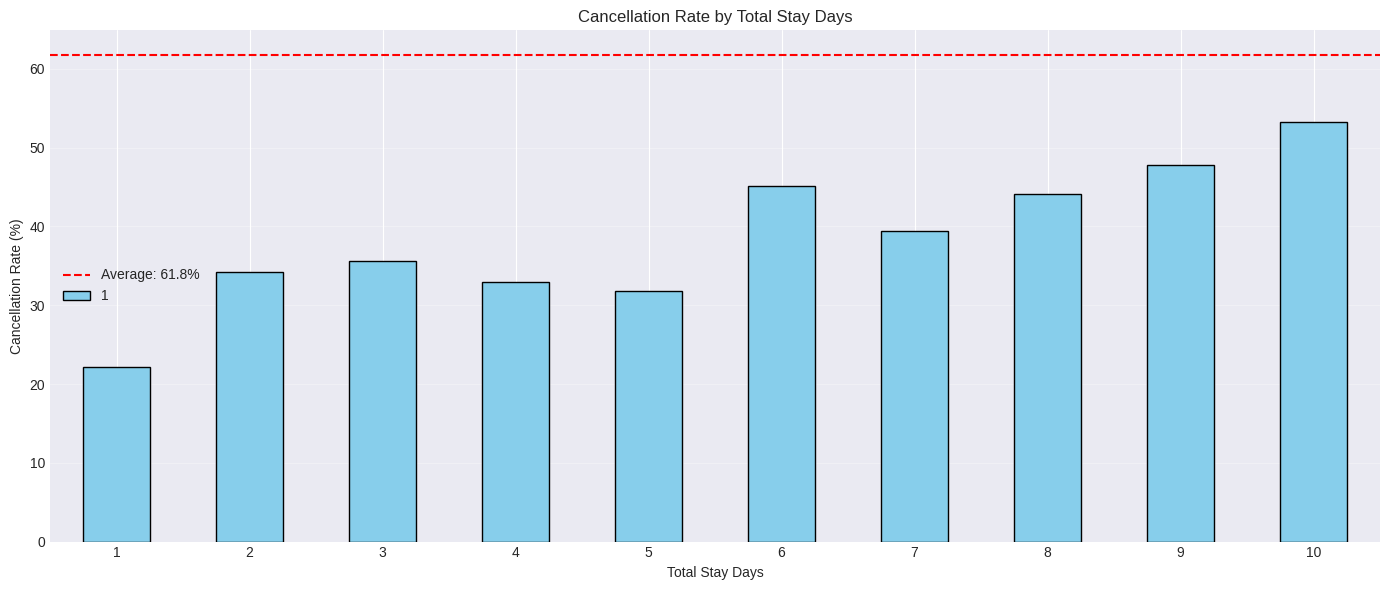

In [47]:
# 4.9 Total Stay Days vs Booking Status
print("\n--- Total Stay Days vs Booking Status ---")

# Create total stay column
data['total_stay_days'] = data['no_of_week_nights'] + data['no_of_weekend_nights']

# Filter for stays of at least 1 day
stay_data = data[data['total_stay_days'] > 0].copy()

# Create crosstab for reasonable stay lengths
stay_status = pd.crosstab(stay_data['total_stay_days'],
                           stay_data['booking_status'],
                           normalize='index') * 100

print("\nCancellation Rate by Total Stay Days (%):")
print(stay_status.head(15).round(2))

# Visualization
plt.figure(figsize=(14, 6))
stay_status[1].head(10).plot(kind='bar', color='skyblue', edgecolor='black')
plt.xlabel('Total Stay Days')
plt.ylabel('Cancellation Rate (%)')
plt.title('Cancellation Rate by Total Stay Days')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.axhline(y=stay_status[1].mean(), color='red', linestyle='--',
            label=f'Average: {stay_status[1].mean():.1f}%')
plt.legend()
plt.tight_layout()
plt.show()


--- Repeated Guests vs Booking Status ---

Cancellation Rate by Repeated Guest Status (%):
booking_status      0      1
repeated_guest              
0              66.420 33.580
1              98.280  1.720


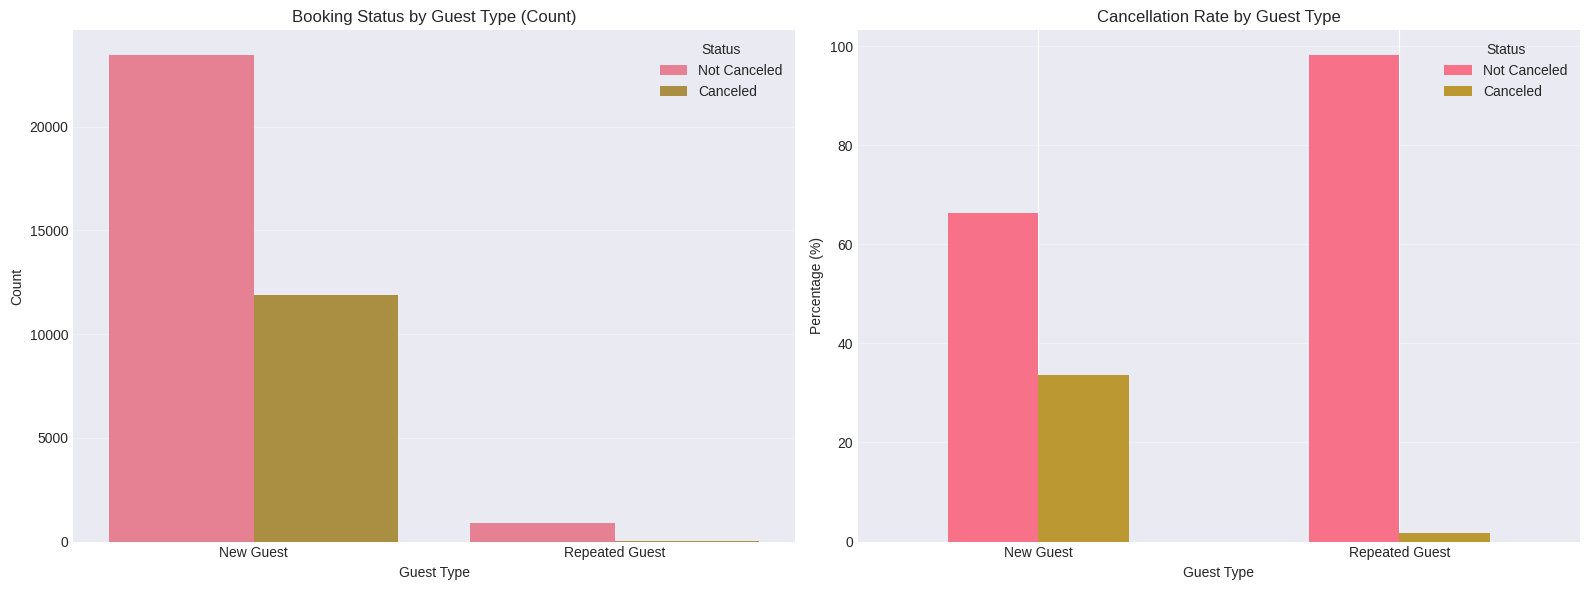


Repeated guest percentage: 2.56%


In [48]:
# 4.10 Repeated Guests vs Booking Status
print("\n--- Repeated Guests vs Booking Status ---")

# Create crosstab
repeat_status = pd.crosstab(data['repeated_guest'],
                             data['booking_status'],
                             normalize='index') * 100

print("\nCancellation Rate by Repeated Guest Status (%):")
print(repeat_status.round(2))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Count plot
sns.countplot(data=data, x='repeated_guest', hue='booking_status', ax=axes[0])
axes[0].set_xticklabels(['New Guest', 'Repeated Guest'])
axes[0].set_xlabel('Guest Type')
axes[0].set_ylabel('Count')
axes[0].set_title('Booking Status by Guest Type (Count)')
axes[0].legend(title='Status', labels=['Not Canceled', 'Canceled'])
axes[0].grid(True, alpha=0.3, axis='y')

# Percentage plot
repeat_status.plot(kind='bar', ax=axes[1])
axes[1].set_xticklabels(['New Guest', 'Repeated Guest'], rotation=0)
axes[1].set_xlabel('Guest Type')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('Cancellation Rate by Guest Type')
axes[1].legend(title='Status', labels=['Not Canceled', 'Canceled'])
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print(f"\nRepeated guest percentage: {(data['repeated_guest'].sum() / len(data) * 100):.2f}%")


--- Busiest Months in the Hotel ---


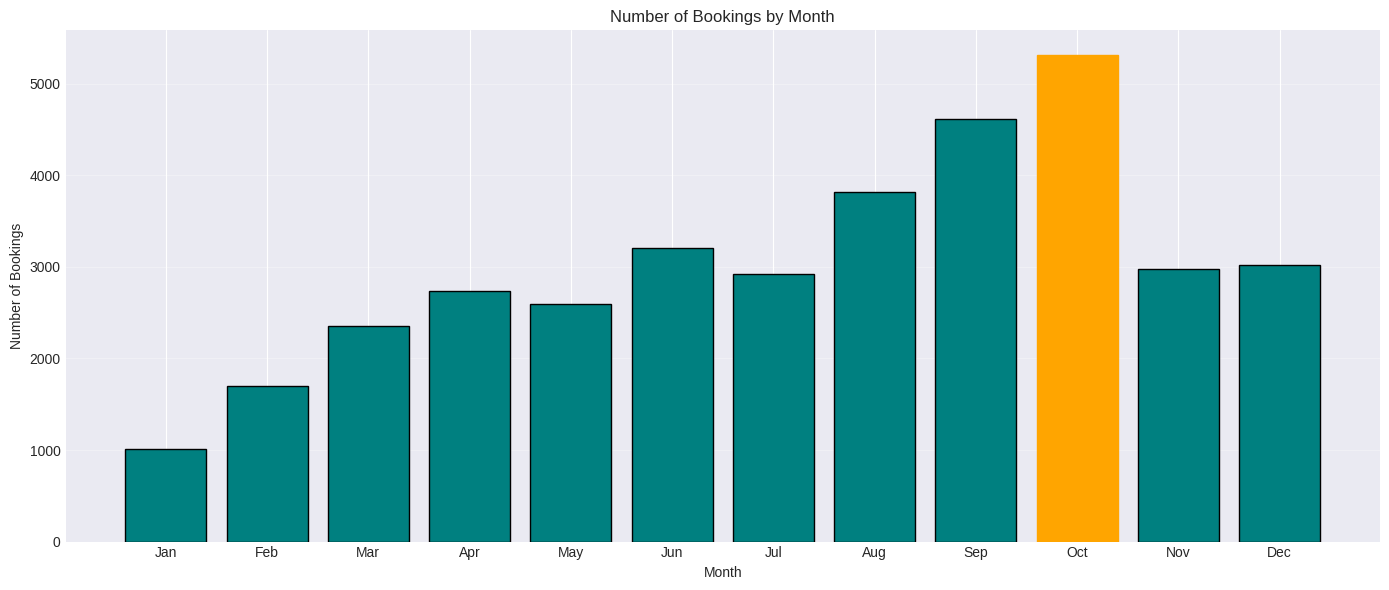


Busiest month: 10 with 5,317 bookings


In [49]:
# 4.11 Busiest Months Analysis
print("\n--- Busiest Months in the Hotel ---")

plt.figure(figsize=(14, 6))
monthly_bookings = data['arrival_month'].value_counts().sort_index()

bars = plt.bar(range(1, 13), [monthly_bookings.get(i, 0) for i in range(1, 13)],
               edgecolor='black', color='teal')
plt.xlabel('Month')
plt.ylabel('Number of Bookings')
plt.title('Number of Bookings by Month')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                           'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, alpha=0.3, axis='y')

# Highlight busiest month
max_month = monthly_bookings.idxmax()
max_idx = list(range(1, 13)).index(max_month)
bars[max_idx].set_color('orange')

plt.tight_layout()
plt.show()

print(f"\nBusiest month: {max_month} with {monthly_bookings[max_month]:,} bookings")


--- Cancellation Rate by Month ---


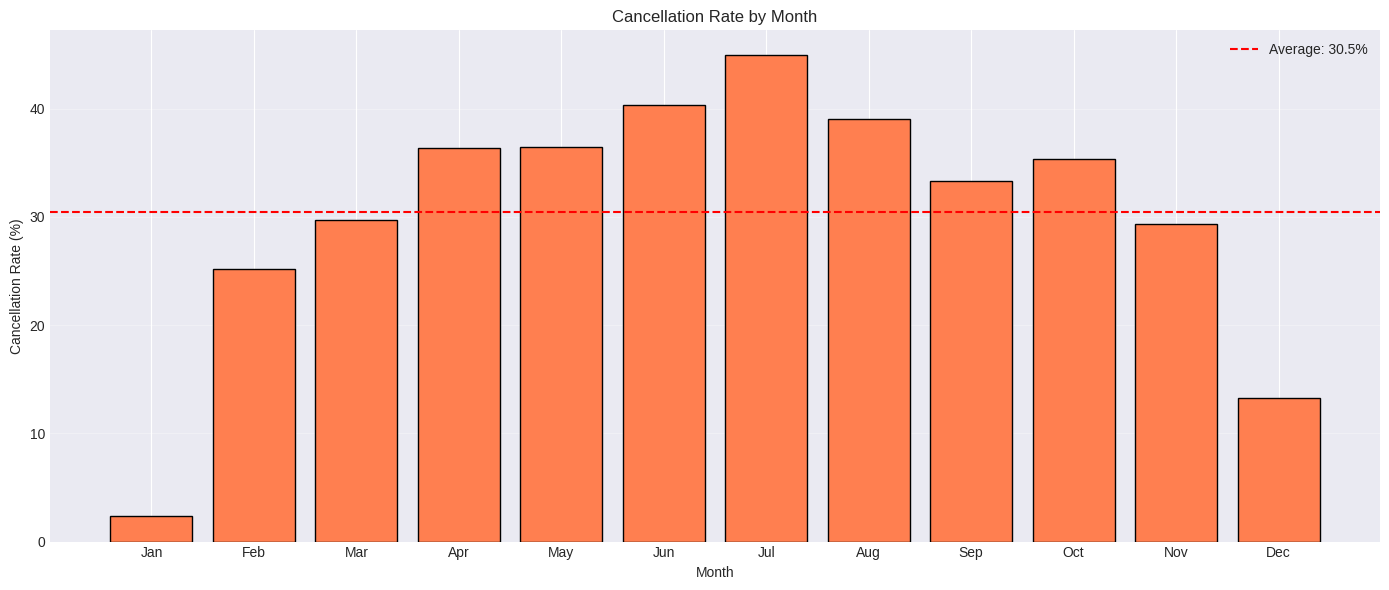


Cancellation Rate by Month:
arrival_month
7    45.000
6    40.306
8    39.024
5    36.490
4    36.367
10   35.358
9    33.355
3    29.686
11   29.362
2    25.235
12   13.307
1     2.367
Name: cancel_rate, dtype: float64


In [50]:
# 4.12 Cancellation Rate by Month
print("\n--- Cancellation Rate by Month ---")

monthly_cancel = data.groupby('arrival_month')['booking_status'].agg(['sum', 'count'])
monthly_cancel['cancel_rate'] = (monthly_cancel['sum'] / monthly_cancel['count'] * 100)

plt.figure(figsize=(14, 6))
bars = plt.bar(range(1, 13), [monthly_cancel.loc[i, 'cancel_rate'] if i in monthly_cancel.index else 0
                               for i in range(1, 13)],
               edgecolor='black', color='coral')
plt.xlabel('Month')
plt.ylabel('Cancellation Rate (%)')
plt.title('Cancellation Rate by Month')
plt.xticks(range(1, 13), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                           'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.axhline(y=monthly_cancel['cancel_rate'].mean(), color='red', linestyle='--',
            label=f'Average: {monthly_cancel["cancel_rate"].mean():.1f}%')
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nCancellation Rate by Month:")
print(monthly_cancel['cancel_rate'].sort_values(ascending=False))


--- Room Prices Across Different Months ---


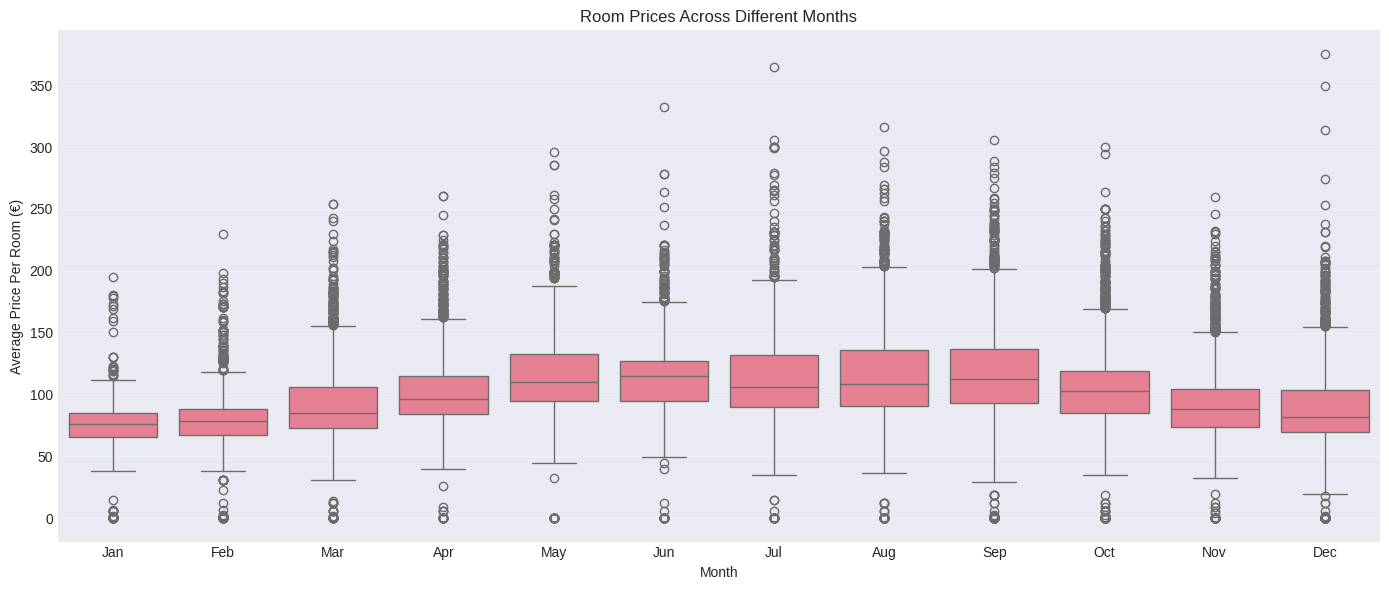


Median Price by Month:
arrival_month
6    115.000
9    112.200
5    110.000
8    108.300
7    106.000
10   102.600
4     96.300
11    88.400
3     85.500
12    82.000
2     79.000
1     76.595
Name: avg_price_per_room, dtype: float64


In [51]:
# 4.13 Room Prices Across Months
print("\n--- Room Prices Across Different Months ---")

plt.figure(figsize=(14, 6))
sns.boxplot(data=data, x='arrival_month', y='avg_price_per_room',
            order=range(1, 13))
plt.xlabel('Month')
plt.ylabel('Average Price Per Room (€)')
plt.title('Room Prices Across Different Months')
plt.xticks(range(12), ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
                        'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("\nMedian Price by Month:")
print(data.groupby('arrival_month')['avg_price_per_room'].median().sort_values(ascending=False))

In [52]:
# ============================================================================
# 5. OUTLIER ANALYSIS
# ============================================================================

print("\n" + "=" * 80)
print("OUTLIER ANALYSIS")
print("=" * 80)


OUTLIER ANALYSIS



--- Outlier Detection for Key Numerical Variables ---


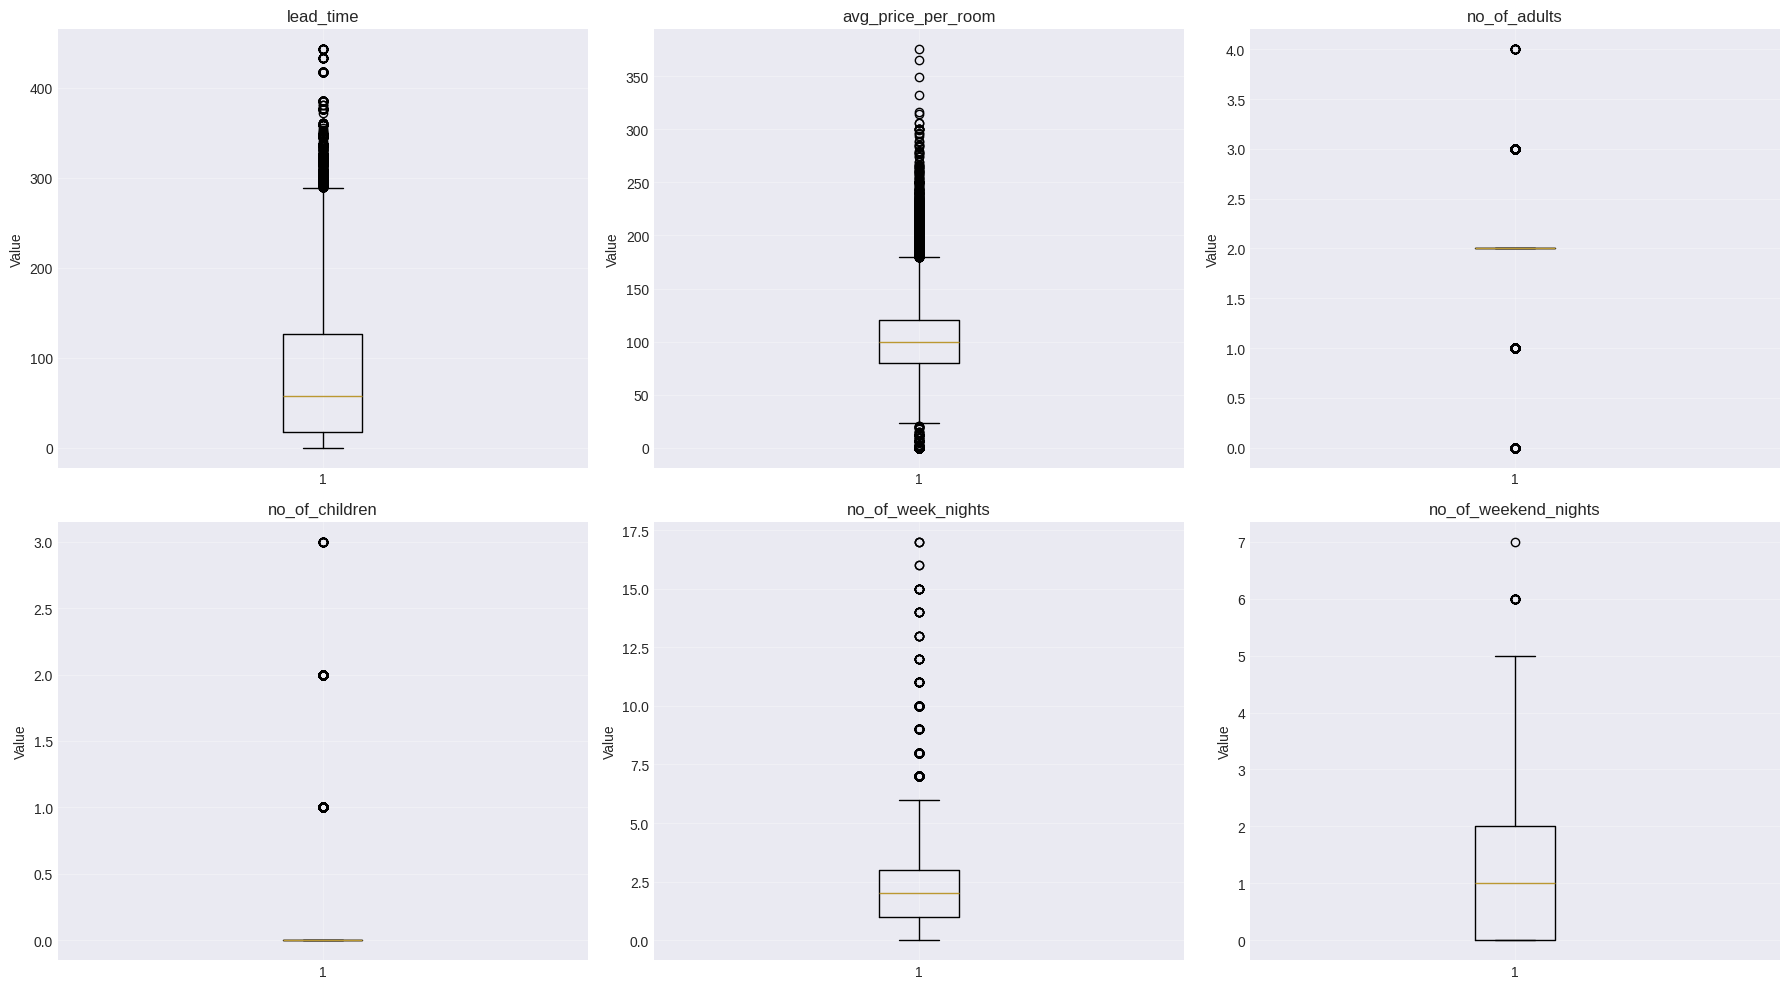


Outlier Statistics:

lead_time:
  Lower bound: -146.50
  Upper bound: 289.50
  Number of outliers: 1331 (3.67%)

avg_price_per_room:
  Lower bound: 20.75
  Upper bound: 179.55
  Number of outliers: 1695 (4.67%)

no_of_adults:
  Lower bound: 2.00
  Upper bound: 2.00
  Number of outliers: 10167 (28.03%)

no_of_children:
  Lower bound: 0.00
  Upper bound: 0.00
  Number of outliers: 2698 (7.44%)

no_of_week_nights:
  Lower bound: -2.00
  Upper bound: 6.00
  Number of outliers: 324 (0.89%)

no_of_weekend_nights:
  Lower bound: -3.00
  Upper bound: 5.00
  Number of outliers: 21 (0.06%)


In [53]:
# Check outliers for numerical variables
print("\n--- Outlier Detection for Key Numerical Variables ---")

numerical_features = ['lead_time', 'avg_price_per_room', 'no_of_adults',
                      'no_of_children', 'no_of_week_nights', 'no_of_weekend_nights']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, col in enumerate(numerical_features):
    axes[idx].boxplot(data[col], vert=True)
    axes[idx].set_title(f'{col}')
    axes[idx].set_ylabel('Value')
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nOutlier Statistics:")
for col in numerical_features:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)][col]
    print(f"\n{col}:")
    print(f"  Lower bound: {lower_bound:.2f}")
    print(f"  Upper bound: {upper_bound:.2f}")
    print(f"  Number of outliers: {len(outliers)} ({len(outliers)/len(data)*100:.2f}%)")

In [54]:
# ============================================================================
# 6. DATA PREPARATION FOR MODELING
# ============================================================================

print("\n" + "=" * 80)
print("DATA PREPARATION FOR MODELING")
print("=" * 80)


DATA PREPARATION FOR MODELING


In [55]:
# Create a copy for modeling
model_data = data.copy()

# Drop columns not needed for modeling
columns_to_drop = ['Booking_ID']
model_data = model_data.drop(columns=columns_to_drop, errors='ignore')

print(f"\nShape after dropping ID columns: {model_data.shape}")


Shape after dropping ID columns: (36275, 20)


In [56]:
# Separate features and target
X = model_data.drop('booking_status', axis=1)
y = model_data['booking_status']

print(f"\nFeatures shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"\nTarget distribution:")
print(y.value_counts())
print(f"\nTarget distribution (%):")
print(y.value_counts(normalize=True) * 100)


Features shape: (36275, 19)
Target shape: (36275,)

Target distribution:
booking_status
0    24390
1    11885
Name: count, dtype: int64

Target distribution (%):
booking_status
0   67.236
1   32.764
Name: proportion, dtype: float64


In [57]:
# Encode categorical variables
print("\n--- Encoding Categorical Variables ---")

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
print(f"\nCategorical features: {categorical_features}")

# Create dummy variables
X_encoded = pd.get_dummies(X, columns=categorical_features, drop_first=True)

print(f"\nShape after encoding: {X_encoded.shape}")
print(f"New features created: {X_encoded.shape[1] - X.shape[1] + len(categorical_features)}")


--- Encoding Categorical Variables ---

Categorical features: ['type_of_meal_plan', 'room_type_reserved', 'market_segment_type']

Shape after encoding: (36275, 29)
New features created: 13


In [58]:
# Split the data into training and testing sets
print("\n--- Splitting Data into Train and Test Sets ---")

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y,
                                                      test_size=0.3,
                                                      random_state=1,
                                                      stratify=y)

print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape: {X_test.shape}")
print(f"\nTraining set target distribution:")
print(y_train.value_counts())
print(f"\nTest set target distribution:")
print(y_test.value_counts())


--- Splitting Data into Train and Test Sets ---

Training set shape: (25392, 29)
Test set shape: (10883, 29)

Training set target distribution:
booking_status
0    17073
1     8319
Name: count, dtype: int64

Test set target distribution:
booking_status
0    7317
1    3566
Name: count, dtype: int64


In [59]:
# ============================================================================
# 7. LOGISTIC REGRESSION MODEL
# ============================================================================

print("\n" + "=" * 80)
print("LOGISTIC REGRESSION MODEL")
print("=" * 80)


LOGISTIC REGRESSION MODEL


In [60]:
# Ensure all columns are numeric and handle any potential issues
print("\n--- Preparing Data for Statsmodels ---")

# Convert boolean columns to int if any exist
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

# Convert all boolean columns to int
for col in X_train_clean.columns:
    if X_train_clean[col].dtype == 'bool':
        X_train_clean[col] = X_train_clean[col].astype(int)
        X_test_clean[col] = X_test_clean[col].astype(int)

# Check for any remaining non-numeric columns
print(f"Training set dtypes:")
print(X_train_clean.dtypes.value_counts())

# Verify no object or other problematic types
problematic_cols = X_train_clean.select_dtypes(include=['object', 'category']).columns.tolist()
if len(problematic_cols) > 0:
    print(f"\nWARNING: Problematic columns found: {problematic_cols}")
    # Convert to numeric
    for col in problematic_cols:
        X_train_clean[col] = pd.to_numeric(X_train_clean[col], errors='coerce')
        X_test_clean[col] = pd.to_numeric(X_test_clean[col], errors='coerce')
    print("Converted to numeric")
else:
    print("\n✓ All columns are numeric")


--- Preparing Data for Statsmodels ---
Training set dtypes:
int64      28
float64     1
Name: count, dtype: int64

✓ All columns are numeric


In [61]:
# Build initial logistic regression model using statsmodels
print("\n--- Building Initial Logistic Regression Model ---")

# Add constant to the features
X_train_sm = sm.add_constant(X_train_clean)

# Verify data types before fitting
print(f"\nX_train_sm shape: {X_train_sm.shape}")
print(f"X_train_sm dtypes: {X_train_sm.dtypes.value_counts()}")
print(f"y_train dtype: {y_train.dtype}")

# Fit the model
logit_model = sm.Logit(y_train, X_train_sm)
lr_initial = logit_model.fit()

# Display model summary
print("\n")
print(lr_initial.summary())


--- Building Initial Logistic Regression Model ---

X_train_sm shape: (25392, 30)
X_train_sm dtypes: int64      28
float64     2
Name: count, dtype: int64
y_train dtype: int64
         Current function value: 0.422404
         Iterations: 35


                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25364
Method:                           MLE   Df Model:                           27
Date:                Sun, 01 Feb 2026   Pseudo R-squ.:                  0.3321
Time:                        16:35:24   Log-Likelihood:                -10726.
converged:                      False   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                           coef    std err          z      P>|z|      [0.025      0.975]
------------------

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [62]:
# Check for multicollinearity using VIF
print("\n--- Checking for Multicollinearity (VIF) ---")

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["Feature"] = X_train_sm.columns
vif_data["VIF"] = [variance_inflation_factor(X_train_sm.values, i)
                   for i in range(X_train_sm.shape[1])]

print("\nVIF Values:")
print(vif_data.sort_values('VIF', ascending=False).to_string())

# Filter for high VIF (excluding constant and dummy variables)
numerical_vif = vif_data[~vif_data['Feature'].str.contains('const|_', na=False)]
high_vif = numerical_vif[numerical_vif['VIF'] > 10]

if len(high_vif) > 0:
    print(f"\nFeatures with high VIF (>10):")
    print(high_vif.to_string())
else:
    print("\nNo features with high multicollinearity (VIF > 10)")


--- Checking for Multicollinearity (VIF) ---

VIF Values:
                                 Feature          VIF
1                           no_of_adults          inf
2                         no_of_children          inf
4                      no_of_week_nights          inf
3                   no_of_weekend_nights          inf
16                       total_stay_days          inf
15                  no_of_family_members          inf
0                                  const 39624634.314
29            market_segment_type_Online       69.474
28           market_segment_type_Offline       62.514
27         market_segment_type_Corporate       16.634
26     market_segment_type_Complementary        4.353
13                    avg_price_per_room        2.050
24        room_type_reserved_Room_Type 6        2.048
10                        repeated_guest        1.750
12  no_of_previous_bookings_not_canceled        1.571
7                           arrival_year        1.434
6                      

In [63]:
# Function to drop high p-value variables iteratively
def drop_high_pvalue_features(X, y, threshold=0.05):
    """
    Iteratively drops features with p-value > threshold
    """
    X_temp = sm.add_constant(X.copy())

    dropped_features = []

    while True:
        model = sm.Logit(y, X_temp).fit(disp=0)
        p_values = model.pvalues

        # Exclude constant from consideration
        p_values_features = p_values.drop('const', errors='ignore')

        # Find feature with highest p-value
        max_p_value = p_values_features.max()

        if max_p_value > threshold:
            feature_to_drop = p_values_features.idxmax()
            print(f"Dropping {feature_to_drop} (p-value: {max_p_value:.4f})")
            X_temp = X_temp.drop(feature_to_drop, axis=1)
            dropped_features.append(feature_to_drop)
        else:
            break

    # Get final feature list (excluding constant)
    final_features = X_temp.columns.tolist()
    final_features.remove('const')

    print(f"\nTotal features dropped: {len(dropped_features)}")
    print(f"Features retained: {len(final_features)}")

    return final_features, model

# Drop high p-value features
print("\n--- Dropping High P-value Features ---")
final_features, lr_final = drop_high_pvalue_features(X_train_clean, y_train)

print(f"\n{len(final_features)} features retained")


--- Dropping High P-value Features ---


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Dropping market_segment_type_Complementary (p-value: 0.9886)


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Dropping room_type_reserved_Room_Type 3 (p-value: 0.6056)
Dropping no_of_week_nights (p-value: 1.0000)
Dropping type_of_meal_plan_Meal Plan 3 (p-value: 0.2338)
Dropping no_of_adults (p-value: 1.0000)
Dropping no_of_children (p-value: 0.5996)
Dropping no_of_family_members (p-value: 0.3027)
Dropping no_of_previous_bookings_not_canceled (p-value: 0.1276)
Dropping arrival_date (p-value: 0.1235)
Dropping market_segment_type_Online (p-value: 0.0886)

Total features dropped: 10
Features retained: 19

19 features retained


In [64]:
# Display final model summary
print("\n--- Final Logistic Regression Model Summary ---")
print(lr_final.summary())


--- Final Logistic Regression Model Summary ---
                           Logit Regression Results                           
Dep. Variable:         booking_status   No. Observations:                25392
Model:                          Logit   Df Residuals:                    25372
Method:                           MLE   Df Model:                           19
Date:                Sun, 01 Feb 2026   Pseudo R-squ.:                  0.3312
Time:                        16:35:34   Log-Likelihood:                -10742.
converged:                       True   LL-Null:                       -16060.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                           -869.4077    120.911     -7.191      0.000   -1106.388    -632.427
no_of_weekend_nights  

In [65]:
# Extract significant features and create final training set
X_train_final = X_train_clean[final_features]
X_test_final = X_test_clean[final_features]

print(f"\nFinal training set shape: {X_train_final.shape}")
print(f"Final test set shape: {X_test_final.shape}")

print("\nFinal features:")
for i, feat in enumerate(final_features, 1):
    print(f"{i}. {feat}")


Final training set shape: (25392, 19)
Final test set shape: (10883, 19)

Final features:
1. no_of_weekend_nights
2. required_car_parking_space
3. lead_time
4. arrival_year
5. arrival_month
6. repeated_guest
7. no_of_previous_cancellations
8. avg_price_per_room
9. no_of_special_requests
10. total_stay_days
11. type_of_meal_plan_Meal Plan 2
12. type_of_meal_plan_Not Selected
13. room_type_reserved_Room_Type 2
14. room_type_reserved_Room_Type 4
15. room_type_reserved_Room_Type 5
16. room_type_reserved_Room_Type 6
17. room_type_reserved_Room_Type 7
18. market_segment_type_Corporate
19. market_segment_type_Offline


In [66]:
# Build sklearn Logistic Regression for predictions
print("\n--- Building sklearn Logistic Regression for Predictions ---")

lr_sklearn = LogisticRegression(random_state=1, max_iter=1000)
lr_sklearn.fit(X_train_final, y_train)

print("Model trained successfully!")


--- Building sklearn Logistic Regression for Predictions ---
Model trained successfully!


In [67]:
# Make predictions on training set (default threshold = 0.5)
y_train_pred = lr_sklearn.predict(X_train_final)
y_train_pred_proba = lr_sklearn.predict_proba(X_train_final)[:, 1]

# Evaluate on training set
print("\n--- Training Set Performance (Default Threshold = 0.5) ---")

train_cm = confusion_matrix(y_train, y_train_pred)
print("\nConfusion Matrix:")
print(train_cm)

print("\nClassification Report:")
print(classification_report(y_train, y_train_pred,
                           target_names=['Not Canceled', 'Canceled']))

train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred)
train_recall = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)

print(f"\nAccuracy: {train_accuracy:.4f}")
print(f"Precision: {train_precision:.4f}")
print(f"Recall: {train_recall:.4f}")
print(f"F1 Score: {train_f1:.4f}")
print(f"ROC-AUC: {train_roc_auc:.4f}")


--- Training Set Performance (Default Threshold = 0.5) ---

Confusion Matrix:
[[15185  1888]
 [ 3131  5188]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.83      0.89      0.86     17073
    Canceled       0.73      0.62      0.67      8319

    accuracy                           0.80     25392
   macro avg       0.78      0.76      0.77     25392
weighted avg       0.80      0.80      0.80     25392


Accuracy: 0.8023
Precision: 0.7332
Recall: 0.6236
F1 Score: 0.6740
ROC-AUC: 0.8628


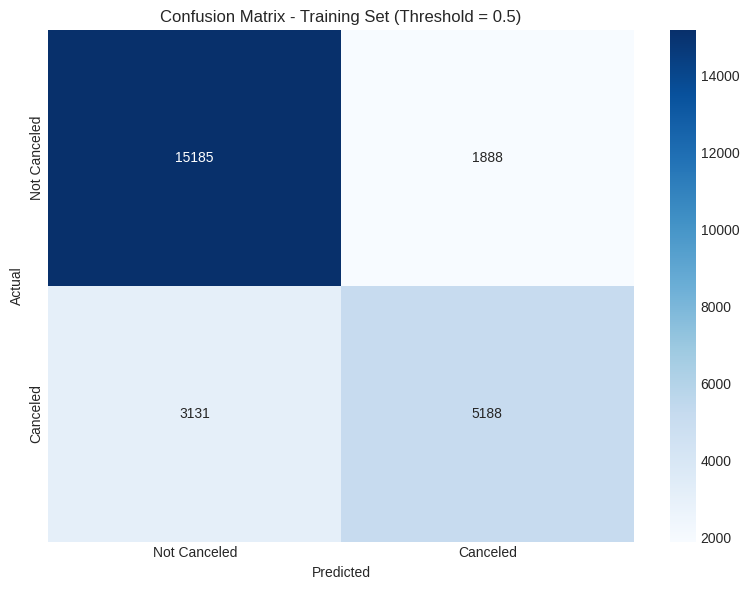

In [68]:
# Visualize confusion matrix for training set
plt.figure(figsize=(8, 6))
sns.heatmap(train_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Training Set (Threshold = 0.5)')
plt.tight_layout()
plt.show()

In [69]:
# Make predictions on test set
y_test_pred = lr_sklearn.predict(X_test_final)
y_test_pred_proba = lr_sklearn.predict_proba(X_test_final)[:, 1]

# Evaluate on test set
print("\n--- Test Set Performance (Default Threshold = 0.5) ---")

test_cm = confusion_matrix(y_test, y_test_pred)
print("\nConfusion Matrix:")
print(test_cm)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred,
                           target_names=['Not Canceled', 'Canceled']))

test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_roc_auc = roc_auc_score(y_test, y_test_pred_proba)

print(f"\nAccuracy: {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall: {test_recall:.4f}")
print(f"F1 Score: {test_f1:.4f}")
print(f"ROC-AUC: {test_roc_auc:.4f}")


--- Test Set Performance (Default Threshold = 0.5) ---

Confusion Matrix:
[[6488  829]
 [1387 2179]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.82      0.89      0.85      7317
    Canceled       0.72      0.61      0.66      3566

    accuracy                           0.80     10883
   macro avg       0.77      0.75      0.76     10883
weighted avg       0.79      0.80      0.79     10883


Accuracy: 0.7964
Precision: 0.7244
Recall: 0.6110
F1 Score: 0.6629
ROC-AUC: 0.8595


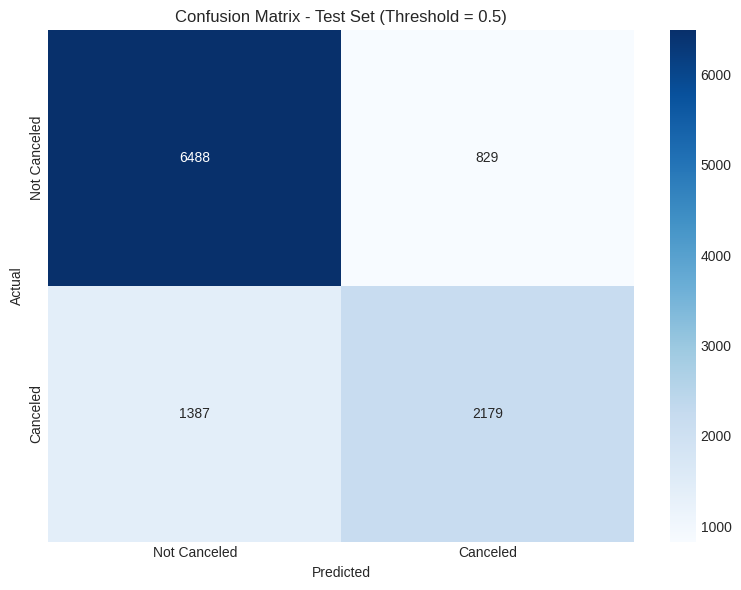

In [70]:
# Visualize confusion matrix for test set
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix - Test Set (Threshold = 0.5)')
plt.tight_layout()
plt.show()

In [71]:
# Coefficient Interpretation
print("\n--- Coefficient Interpretation ---")

# Get coefficients from statsmodels for interpretation
coefficients = pd.DataFrame({
    'Feature': lr_final.params.index,
    'Coefficient': lr_final.params.values,
    'Odds_Ratio': np.exp(lr_final.params.values),
    'Percentage_Change': (np.exp(lr_final.params.values) - 1) * 100,
    'P_value': lr_final.pvalues.values
})

# Remove constant
coefficients = coefficients[coefficients['Feature'] != 'const']

# Sort by absolute coefficient value
coefficients['Abs_Coefficient'] = coefficients['Coefficient'].abs()
coefficients = coefficients.sort_values('Abs_Coefficient', ascending=False)
coefficients = coefficients.drop('Abs_Coefficient', axis=1)

print("\nTop 20 Features by Coefficient Magnitude:")
print(coefficients.head(20).to_string(index=False))


--- Coefficient Interpretation ---

Top 20 Features by Coefficient Magnitude:
                       Feature  Coefficient  Odds_Ratio  Percentage_Change  P_value
                repeated_guest       -3.074       0.046            -95.377    0.000
   market_segment_type_Offline       -1.771       0.170            -82.988    0.000
    required_car_parking_space       -1.615       0.199            -80.114    0.000
        no_of_special_requests       -1.486       0.226            -77.362    0.000
room_type_reserved_Room_Type 7       -1.318       0.268            -73.224    0.000
 market_segment_type_Corporate       -0.871       0.419            -58.146    0.000
room_type_reserved_Room_Type 6       -0.744       0.475            -52.479    0.000
room_type_reserved_Room_Type 5       -0.689       0.502            -49.787    0.001
                  arrival_year        0.430       1.537             53.653    0.000
room_type_reserved_Room_Type 2       -0.373       0.688            -31.155    0.0

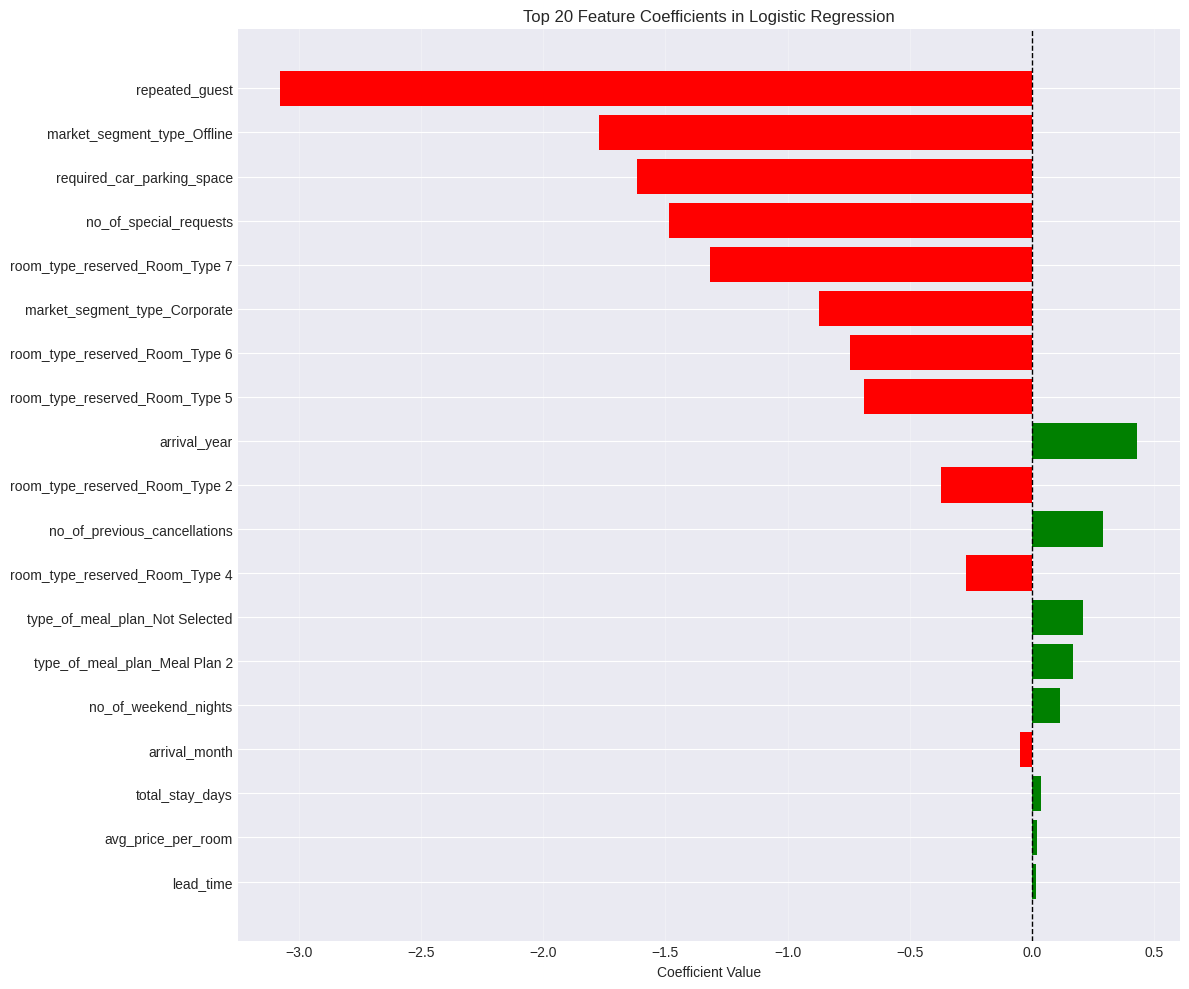

In [72]:
# Visualize feature coefficients
plt.figure(figsize=(12, 10))
top_features = coefficients.head(20)
colors = ['red' if x < 0 else 'green' for x in top_features['Coefficient']]
plt.barh(range(len(top_features)), top_features['Coefficient'], color=colors)
plt.yticks(range(len(top_features)), top_features['Feature'])
plt.xlabel('Coefficient Value')
plt.title('Top 20 Feature Coefficients in Logistic Regression')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.grid(True, alpha=0.3, axis='x')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


--- ROC Curve Analysis (Training Set) ---


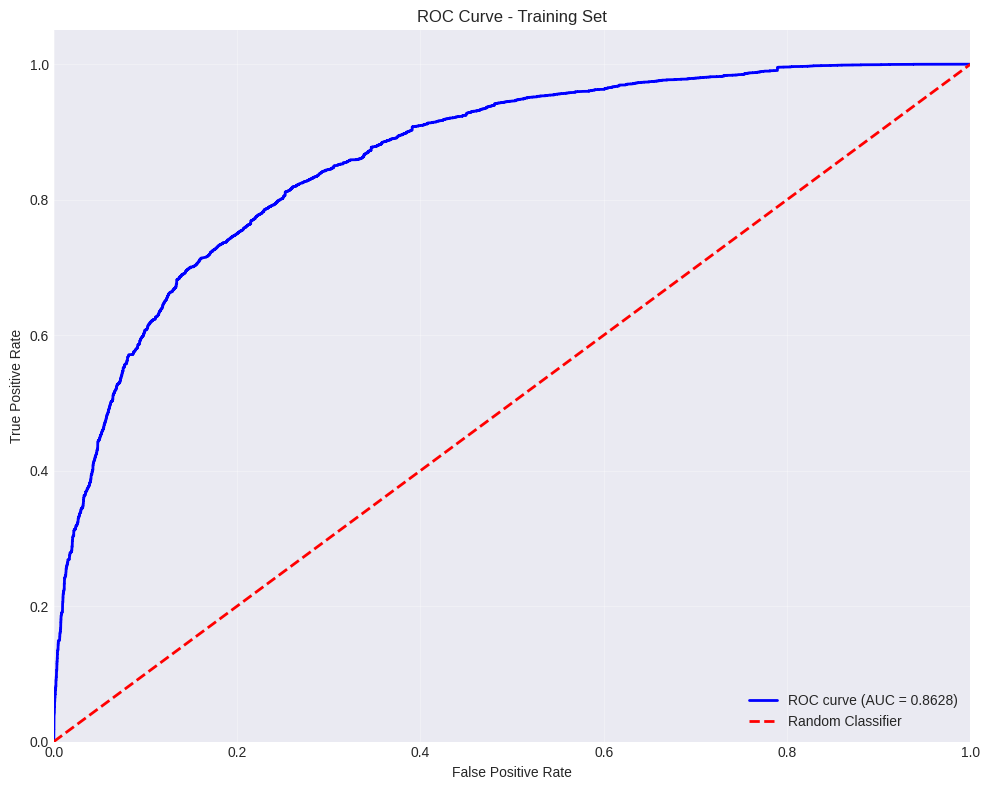

In [73]:
# ROC Curve for Training Set
print("\n--- ROC Curve Analysis (Training Set) ---")

fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_pred_proba)

plt.figure(figsize=(10, 8))
plt.plot(fpr_train, tpr_train, color='blue', lw=2,
         label=f'ROC curve (AUC = {train_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Training Set')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [74]:
# Find optimal threshold using ROC curve
print("\n--- Finding Optimal Threshold using ROC Curve ---")

# Calculate Youden's J statistic
J = tpr_train - fpr_train
optimal_idx = np.argmax(J)
optimal_threshold_roc = thresholds_train[optimal_idx]

print(f"\nOptimal threshold (ROC): {optimal_threshold_roc:.4f}")
print(f"TPR at optimal threshold: {tpr_train[optimal_idx]:.4f}")
print(f"FPR at optimal threshold: {fpr_train[optimal_idx]:.4f}")

# Make predictions with optimal threshold
y_train_pred_optimal = (y_train_pred_proba >= optimal_threshold_roc).astype(int)

# Evaluate with optimal threshold
print(f"\n--- Training Performance with Optimal Threshold ({optimal_threshold_roc:.4f}) ---")

train_cm_optimal = confusion_matrix(y_train, y_train_pred_optimal)
print("\nConfusion Matrix:")
print(train_cm_optimal)

print("\nClassification Report:")
print(classification_report(y_train, y_train_pred_optimal,
                           target_names=['Not Canceled', 'Canceled']))

train_precision_opt = precision_score(y_train, y_train_pred_optimal)
train_recall_opt = recall_score(y_train, y_train_pred_optimal)
train_f1_opt = f1_score(y_train, y_train_pred_optimal)

print(f"\nPrecision: {train_precision_opt:.4f}")
print(f"Recall: {train_recall_opt:.4f}")
print(f"F1 Score: {train_f1_opt:.4f}")


--- Finding Optimal Threshold using ROC Curve ---

Optimal threshold (ROC): 0.2896
TPR at optimal threshold: 0.8113
FPR at optimal threshold: 0.2524

--- Training Performance with Optimal Threshold (0.2896) ---

Confusion Matrix:
[[12763  4310]
 [ 1570  6749]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.89      0.75      0.81     17073
    Canceled       0.61      0.81      0.70      8319

    accuracy                           0.77     25392
   macro avg       0.75      0.78      0.75     25392
weighted avg       0.80      0.77      0.77     25392


Precision: 0.6103
Recall: 0.8113
F1 Score: 0.6966


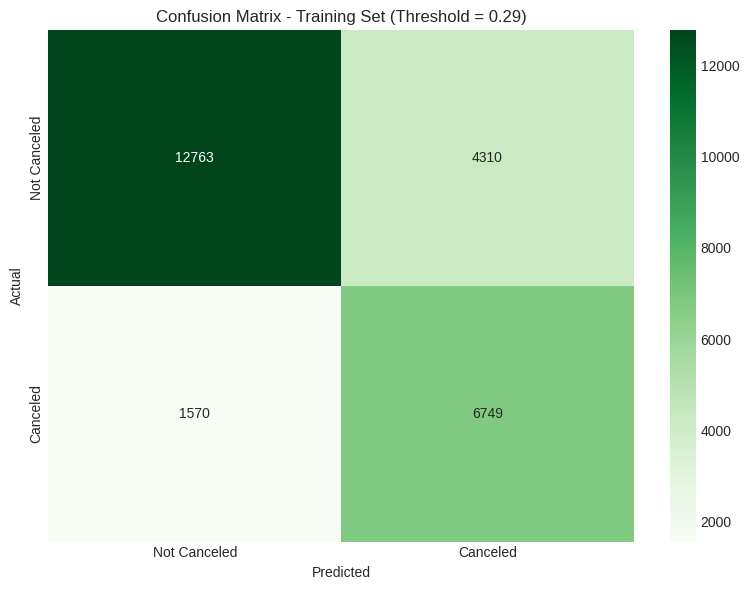

In [75]:
# Visualize confusion matrix with optimal threshold
plt.figure(figsize=(8, 6))
sns.heatmap(train_cm_optimal, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title(f'Confusion Matrix - Training Set (Threshold = {optimal_threshold_roc:.2f})')
plt.tight_layout()
plt.show()

In [76]:
# Test set with optimal ROC threshold
y_test_pred_optimal_roc = (y_test_pred_proba >= optimal_threshold_roc).astype(int)

print(f"\n--- Test Performance with Optimal ROC Threshold ({optimal_threshold_roc:.4f}) ---")

test_cm_optimal_roc = confusion_matrix(y_test, y_test_pred_optimal_roc)
print("\nConfusion Matrix:")
print(test_cm_optimal_roc)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_optimal_roc,
                           target_names=['Not Canceled', 'Canceled']))

test_precision_opt_roc = precision_score(y_test, y_test_pred_optimal_roc)
test_recall_opt_roc = recall_score(y_test, y_test_pred_optimal_roc)
test_f1_opt_roc = f1_score(y_test, y_test_pred_optimal_roc)

print(f"\nPrecision: {test_precision_opt_roc:.4f}")
print(f"Recall: {test_recall_opt_roc:.4f}")
print(f"F1 Score: {test_f1_opt_roc:.4f}")


--- Test Performance with Optimal ROC Threshold (0.2896) ---

Confusion Matrix:
[[5450 1867]
 [ 677 2889]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.89      0.74      0.81      7317
    Canceled       0.61      0.81      0.69      3566

    accuracy                           0.77     10883
   macro avg       0.75      0.78      0.75     10883
weighted avg       0.80      0.77      0.77     10883


Precision: 0.6074
Recall: 0.8102
F1 Score: 0.6943



--- ROC Curve Analysis (Test Set) ---


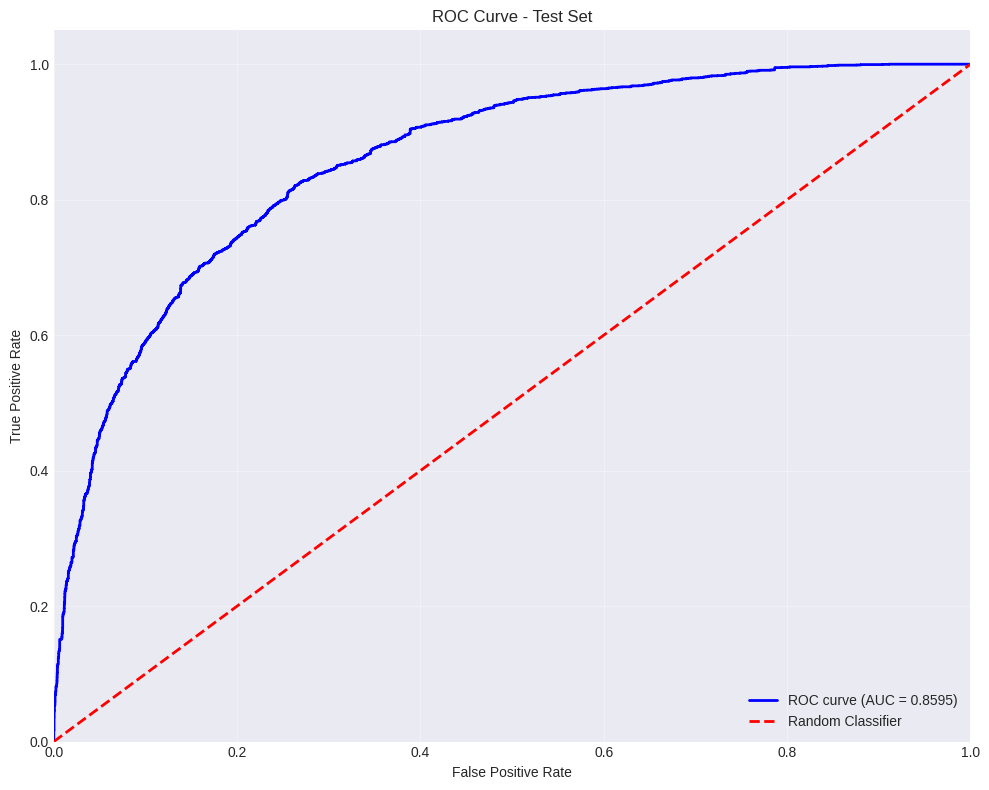

In [77]:
# ROC Curve for Test Set
print("\n--- ROC Curve Analysis (Test Set) ---")

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_pred_proba)

plt.figure(figsize=(10, 8))
plt.plot(fpr_test, tpr_test, color='blue', lw=2,
         label=f'ROC curve (AUC = {test_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


--- Precision-Recall Curve Analysis ---

Optimal threshold (PR curve): 0.3959
Precision at optimal threshold: 0.6842
Recall at optimal threshold: 0.7137
F1 Score at optimal threshold: 0.6986


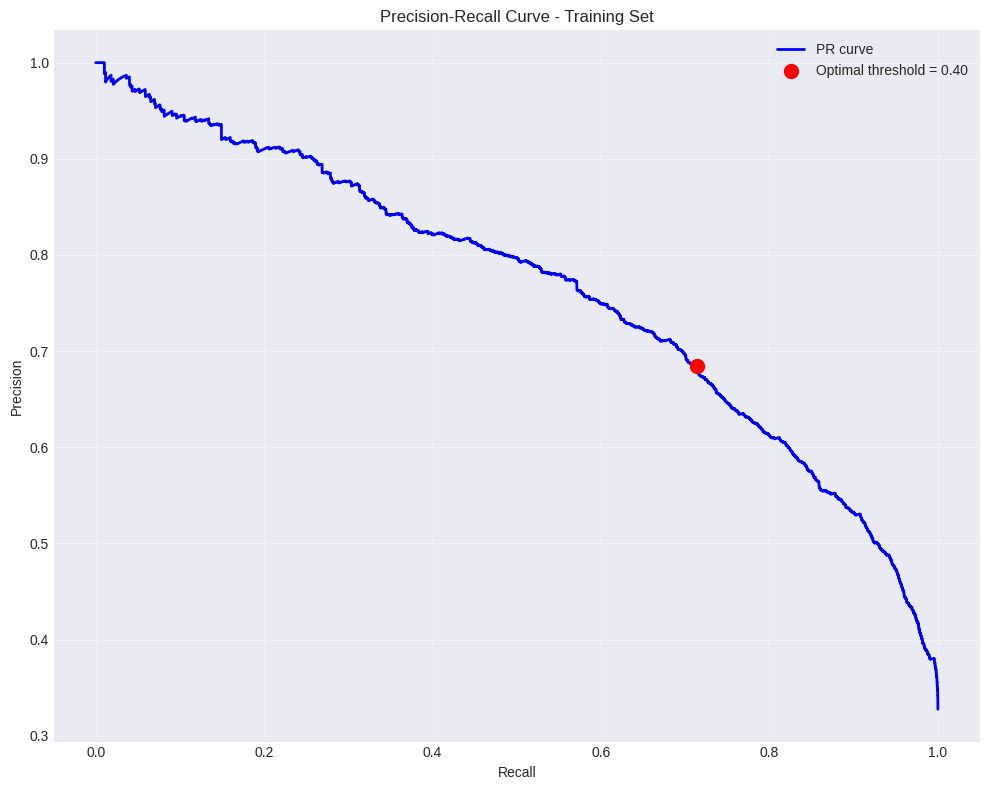

In [78]:
# Precision-Recall Curve
print("\n--- Precision-Recall Curve Analysis ---")

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_train, y_train_pred_proba)

# Find threshold where precision and recall are balanced
f1_scores = 2 * (precision_vals * recall_vals) / (precision_vals + recall_vals + 1e-10)
optimal_pr_idx = np.argmax(f1_scores)
optimal_threshold_pr = pr_thresholds[optimal_pr_idx] if optimal_pr_idx < len(pr_thresholds) else 0.5

print(f"\nOptimal threshold (PR curve): {optimal_threshold_pr:.4f}")
print(f"Precision at optimal threshold: {precision_vals[optimal_pr_idx]:.4f}")
print(f"Recall at optimal threshold: {recall_vals[optimal_pr_idx]:.4f}")
print(f"F1 Score at optimal threshold: {f1_scores[optimal_pr_idx]:.4f}")

# Plot Precision-Recall curve
plt.figure(figsize=(10, 8))
plt.plot(recall_vals, precision_vals, color='blue', lw=2, label='PR curve')
plt.scatter(recall_vals[optimal_pr_idx], precision_vals[optimal_pr_idx],
           color='red', s=100, zorder=5,
           label=f'Optimal threshold = {optimal_threshold_pr:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Training Set')
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [79]:
# Using 0.42
final_threshold = 0.42

print(f"\n--- Using Threshold = {final_threshold} for Final Model ---")

# Training set predictions
y_train_pred_final = (y_train_pred_proba >= final_threshold).astype(int)

print(f"\n--- Training Performance (Threshold = {final_threshold}) ---")

train_cm_final = confusion_matrix(y_train, y_train_pred_final)
print("\nConfusion Matrix:")
print(train_cm_final)

print("\nClassification Report:")
print(classification_report(y_train, y_train_pred_final,
                           target_names=['Not Canceled', 'Canceled']))

train_precision_final = precision_score(y_train, y_train_pred_final)
train_recall_final = recall_score(y_train, y_train_pred_final)
train_f1_final = f1_score(y_train, y_train_pred_final)

print(f"\nPrecision: {train_precision_final:.4f}")
print(f"Recall: {train_recall_final:.4f}")
print(f"F1 Score: {train_f1_final:.4f}")


--- Using Threshold = 0.42 for Final Model ---

--- Training Performance (Threshold = 0.42) ---

Confusion Matrix:
[[14570  2503]
 [ 2516  5803]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.85      0.85      0.85     17073
    Canceled       0.70      0.70      0.70      8319

    accuracy                           0.80     25392
   macro avg       0.78      0.78      0.78     25392
weighted avg       0.80      0.80      0.80     25392


Precision: 0.6987
Recall: 0.6976
F1 Score: 0.6981


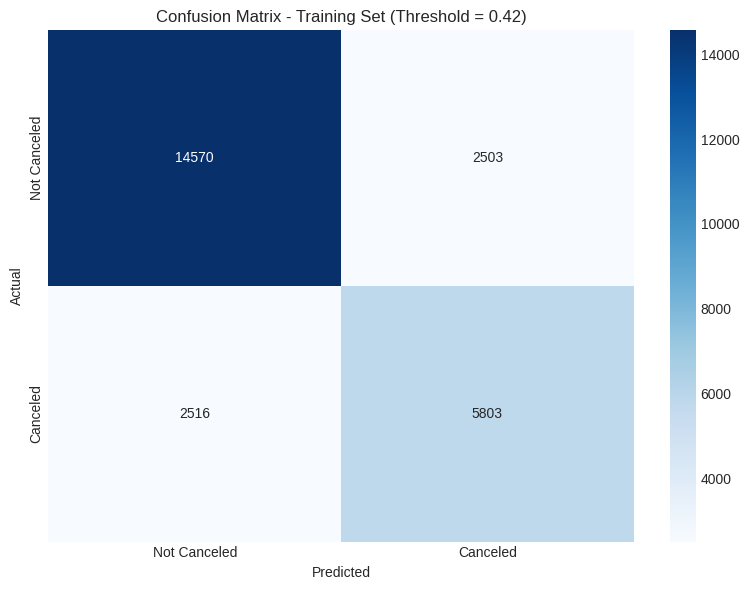

In [80]:
# Visualize final training confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(train_cm_final, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title(f'Confusion Matrix - Training Set (Threshold = {final_threshold})')
plt.tight_layout()
plt.show()

In [81]:
# Test set predictions with final threshold
y_test_pred_final = (y_test_pred_proba >= final_threshold).astype(int)

print(f"\n--- Test Performance (Threshold = {final_threshold}) ---")

test_cm_final = confusion_matrix(y_test, y_test_pred_final)
print("\nConfusion Matrix:")
print(test_cm_final)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_final,
                           target_names=['Not Canceled', 'Canceled']))

test_precision_final = precision_score(y_test, y_test_pred_final)
test_recall_final = recall_score(y_test, y_test_pred_final)
test_f1_final = f1_score(y_test, y_test_pred_final)

print(f"\nPrecision: {test_precision_final:.4f}")
print(f"Recall: {test_recall_final:.4f}")
print(f"F1 Score: {test_f1_final:.4f}")


--- Test Performance (Threshold = 0.42) ---

Confusion Matrix:
[[6222 1095]
 [1114 2452]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.85      0.85      0.85      7317
    Canceled       0.69      0.69      0.69      3566

    accuracy                           0.80     10883
   macro avg       0.77      0.77      0.77     10883
weighted avg       0.80      0.80      0.80     10883


Precision: 0.6913
Recall: 0.6876
F1 Score: 0.6894


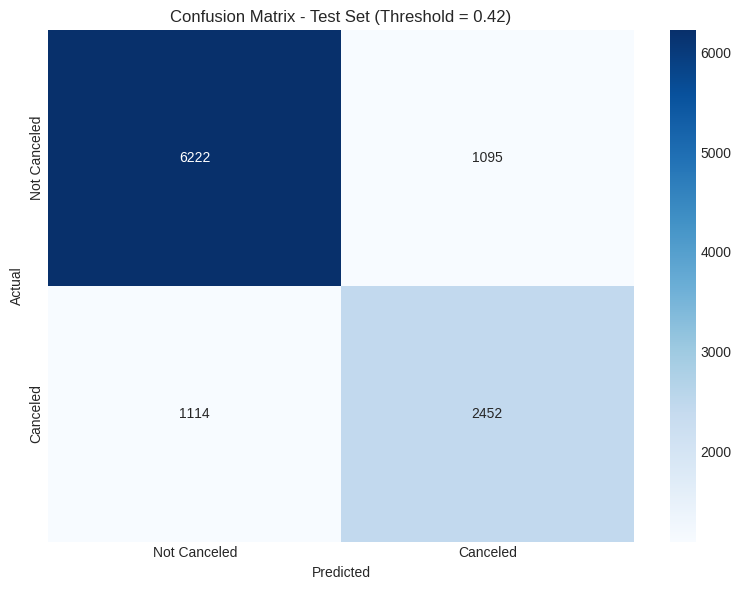

In [82]:
# Visualize final test confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm_final, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title(f'Confusion Matrix - Test Set (Threshold = {final_threshold})')
plt.tight_layout()
plt.show()

In [83]:
# Model Performance Summary - Logistic Regression
print("\n" + "=" * 80)
print("LOGISTIC REGRESSION - MODEL PERFORMANCE SUMMARY")
print("=" * 80)

lr_summary = pd.DataFrame({
    'Threshold': [0.5, optimal_threshold_roc, final_threshold],
    'Train_Precision': [train_precision, train_precision_opt, train_precision_final],
    'Train_Recall': [train_recall, train_recall_opt, train_recall_final],
    'Train_F1': [train_f1, train_f1_opt, train_f1_final],
    'Test_Precision': [test_precision, test_precision_opt_roc, test_precision_final],
    'Test_Recall': [test_recall, test_recall_opt_roc, test_recall_final],
    'Test_F1': [test_f1, test_f1_opt_roc, test_f1_final]
})

print("\nPerformance Comparison Across Different Thresholds:")
print(lr_summary.to_string(index=False))


LOGISTIC REGRESSION - MODEL PERFORMANCE SUMMARY

Performance Comparison Across Different Thresholds:
 Threshold  Train_Precision  Train_Recall  Train_F1  Test_Precision  Test_Recall  Test_F1
     0.500            0.733         0.624     0.674           0.724        0.611    0.663
     0.290            0.610         0.811     0.697           0.607        0.810    0.694
     0.420            0.699         0.698     0.698           0.691        0.688    0.689


In [84]:
# ============================================================================
# 8. DECISION TREE MODEL
# ============================================================================

print("\n" + "=" * 80)
print("DECISION TREE MODEL")
print("=" * 80)


DECISION TREE MODEL


In [85]:
# Build initial Decision Tree with default parameters
print("\n--- Building Decision Tree with Default Parameters ---")

dt_default = DecisionTreeClassifier(random_state=1)
dt_default.fit(X_train_final, y_train)

print("Decision Tree model trained successfully!")
print(f"\nTree depth: {dt_default.get_depth()}")
print(f"Number of leaves: {dt_default.get_n_leaves()}")


--- Building Decision Tree with Default Parameters ---
Decision Tree model trained successfully!

Tree depth: 41
Number of leaves: 3257


In [86]:
# Training set performance - Default Tree
print("\n--- Training Set Performance (Default Tree) ---")

y_train_pred_dt_default = dt_default.predict(X_train_final)

train_cm_dt_default = confusion_matrix(y_train, y_train_pred_dt_default)
print("\nConfusion Matrix:")
print(train_cm_dt_default)

print("\nClassification Report:")
print(classification_report(y_train, y_train_pred_dt_default,
                           target_names=['Not Canceled', 'Canceled']))

train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt_default)
train_precision_dt = precision_score(y_train, y_train_pred_dt_default)
train_recall_dt = recall_score(y_train, y_train_pred_dt_default)
train_f1_dt = f1_score(y_train, y_train_pred_dt_default)

print(f"\nAccuracy: {train_accuracy_dt:.4f}")
print(f"Precision: {train_precision_dt:.4f}")
print(f"Recall: {train_recall_dt:.4f}")
print(f"F1 Score: {train_f1_dt:.4f}")


--- Training Set Performance (Default Tree) ---

Confusion Matrix:
[[17036    37]
 [  137  8182]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.99      1.00      0.99     17073
    Canceled       1.00      0.98      0.99      8319

    accuracy                           0.99     25392
   macro avg       0.99      0.99      0.99     25392
weighted avg       0.99      0.99      0.99     25392


Accuracy: 0.9931
Precision: 0.9955
Recall: 0.9835
F1 Score: 0.9895


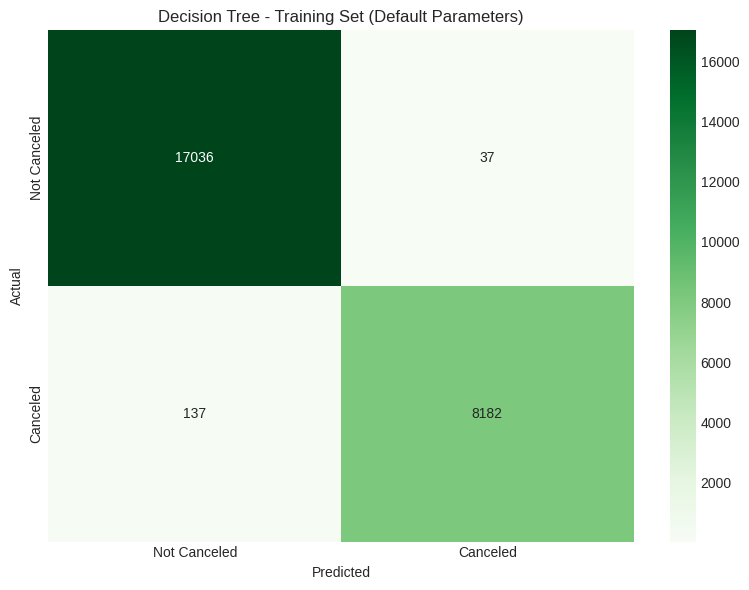

In [87]:
# Visualize training confusion matrix - Default Tree
plt.figure(figsize=(8, 6))
sns.heatmap(train_cm_dt_default, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Decision Tree - Training Set (Default Parameters)')
plt.tight_layout()
plt.show()

In [88]:
# Test set performance - Default Tree
print("\n--- Test Set Performance (Default Tree) ---")

y_test_pred_dt_default = dt_default.predict(X_test_final)

test_cm_dt_default = confusion_matrix(y_test, y_test_pred_dt_default)
print("\nConfusion Matrix:")
print(test_cm_dt_default)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_dt_default,
                           target_names=['Not Canceled', 'Canceled']))

test_accuracy_dt = accuracy_score(y_test, y_test_pred_dt_default)
test_precision_dt = precision_score(y_test, y_test_pred_dt_default)
test_recall_dt = recall_score(y_test, y_test_pred_dt_default)
test_f1_dt = f1_score(y_test, y_test_pred_dt_default)

print(f"\nAccuracy: {test_accuracy_dt:.4f}")
print(f"Precision: {test_precision_dt:.4f}")
print(f"Recall: {test_recall_dt:.4f}")
print(f"F1 Score: {test_f1_dt:.4f}")


--- Test Set Performance (Default Tree) ---

Confusion Matrix:
[[6602  715]
 [ 710 2856]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.90      0.90      0.90      7317
    Canceled       0.80      0.80      0.80      3566

    accuracy                           0.87     10883
   macro avg       0.85      0.85      0.85     10883
weighted avg       0.87      0.87      0.87     10883


Accuracy: 0.8691
Precision: 0.7998
Recall: 0.8009
F1 Score: 0.8003


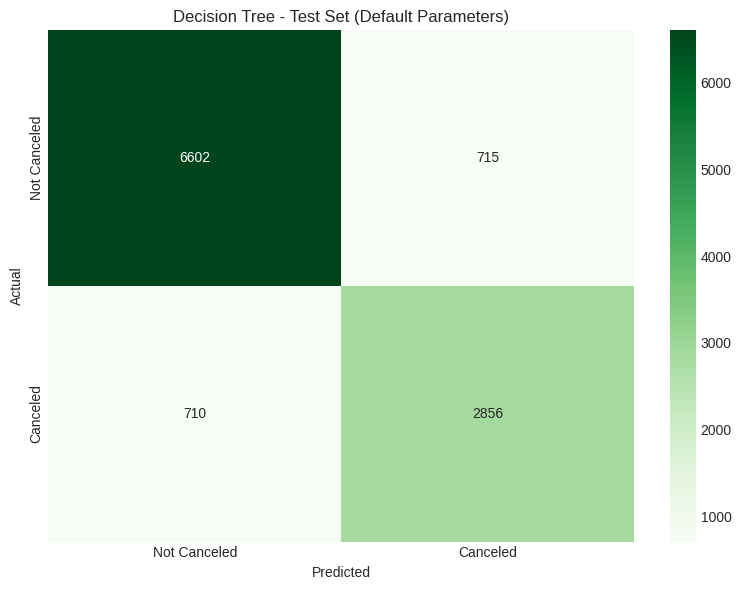

In [89]:
# Visualize test confusion matrix - Default Tree
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm_dt_default, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Decision Tree - Test Set (Default Parameters)')
plt.tight_layout()
plt.show()


--- Feature Importance (Default Tree) ---

Top 15 Important Features:
                       Feature  Importance
                     lead_time       0.407
            avg_price_per_room       0.206
                 arrival_month       0.082
        no_of_special_requests       0.072
   market_segment_type_Offline       0.061
               total_stay_days       0.056
          no_of_weekend_nights       0.039
                  arrival_year       0.019
 type_of_meal_plan_Meal Plan 2       0.013
 market_segment_type_Corporate       0.011
room_type_reserved_Room_Type 4       0.010
type_of_meal_plan_Not Selected       0.009
    required_car_parking_space       0.007
room_type_reserved_Room_Type 2       0.003
room_type_reserved_Room_Type 5       0.002


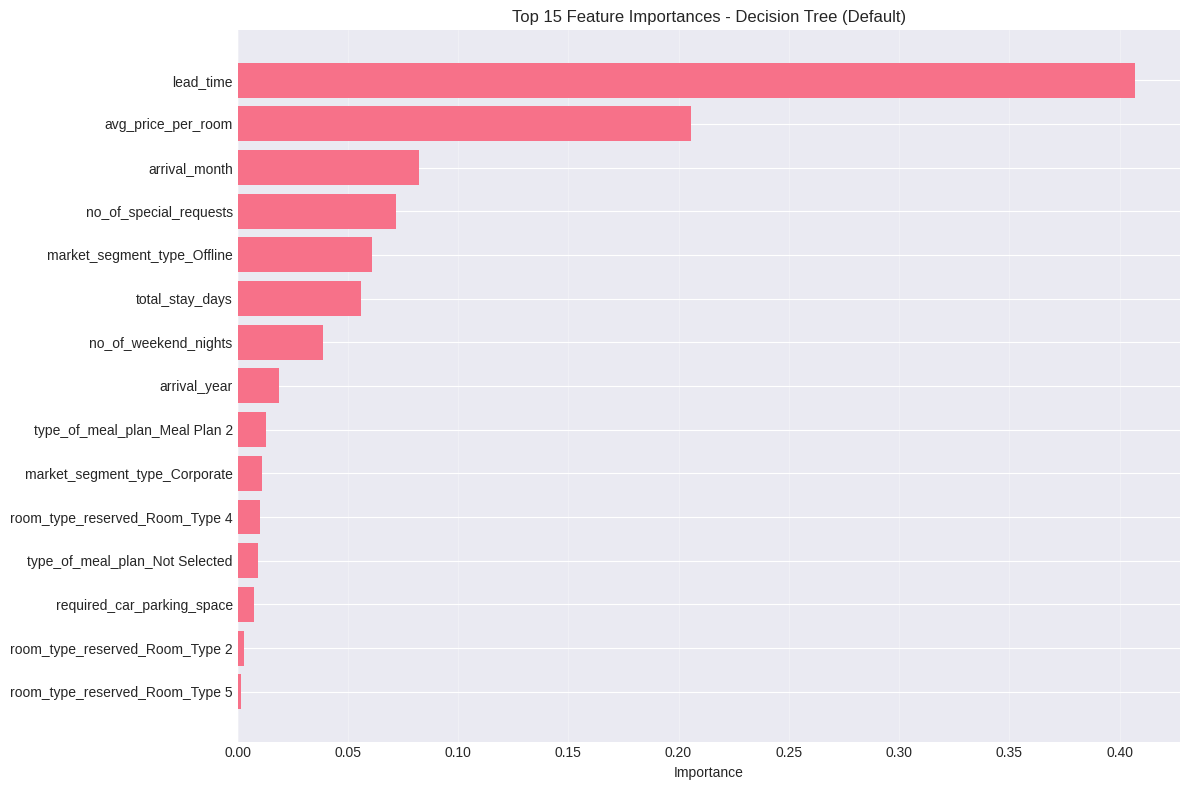

In [90]:
# Feature Importance - Default Tree
print("\n--- Feature Importance (Default Tree) ---")

feature_importance_dt = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Importance': dt_default.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Important Features:")
print(feature_importance_dt.head(15).to_string(index=False))

# Visualize feature importance
plt.figure(figsize=(12, 8))
top_features_dt = feature_importance_dt.head(15)
plt.barh(range(len(top_features_dt)), top_features_dt['Importance'])
plt.yticks(range(len(top_features_dt)), top_features_dt['Feature'])
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances - Decision Tree (Default)')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

In [91]:
# ============================================================================
# 9. DECISION TREE - PRE-PRUNING
# ============================================================================

print("\n" + "=" * 80)
print("DECISION TREE - PRE-PRUNING")
print("=" * 80)


DECISION TREE - PRE-PRUNING


In [92]:
# Build Decision Tree with pre-pruning parameters
print("\n--- Building Decision Tree with Pre-Pruning ---")

dt_prepruned = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=50,
    min_samples_leaf=25,
    random_state=1
)

dt_prepruned.fit(X_train_final, y_train)

print("Pre-pruned Decision Tree trained successfully!")
print(f"\nTree depth: {dt_prepruned.get_depth()}")
print(f"Number of leaves: {dt_prepruned.get_n_leaves()}")


--- Building Decision Tree with Pre-Pruning ---
Pre-pruned Decision Tree trained successfully!

Tree depth: 5
Number of leaves: 28


In [93]:
# Training set performance - Pre-pruned Tree
print("\n--- Training Set Performance (Pre-Pruned Tree) ---")

y_train_pred_dt_prepruned = dt_prepruned.predict(X_train_final)

train_cm_dt_prepruned = confusion_matrix(y_train, y_train_pred_dt_prepruned)
print("\nConfusion Matrix:")
print(train_cm_dt_prepruned)

print("\nClassification Report:")
print(classification_report(y_train, y_train_pred_dt_prepruned,
                           target_names=['Not Canceled', 'Canceled']))

train_accuracy_dt_pre = accuracy_score(y_train, y_train_pred_dt_prepruned)
train_precision_dt_pre = precision_score(y_train, y_train_pred_dt_prepruned)
train_recall_dt_pre = recall_score(y_train, y_train_pred_dt_prepruned)
train_f1_dt_pre = f1_score(y_train, y_train_pred_dt_prepruned)

print(f"\nAccuracy: {train_accuracy_dt_pre:.4f}")
print(f"Precision: {train_precision_dt_pre:.4f}")
print(f"Recall: {train_recall_dt_pre:.4f}")
print(f"F1 Score: {train_f1_dt_pre:.4f}")


--- Training Set Performance (Pre-Pruned Tree) ---

Confusion Matrix:
[[15958  1115]
 [ 3343  4976]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.83      0.93      0.88     17073
    Canceled       0.82      0.60      0.69      8319

    accuracy                           0.82     25392
   macro avg       0.82      0.77      0.78     25392
weighted avg       0.82      0.82      0.82     25392


Accuracy: 0.8244
Precision: 0.8169
Recall: 0.5981
F1 Score: 0.6906


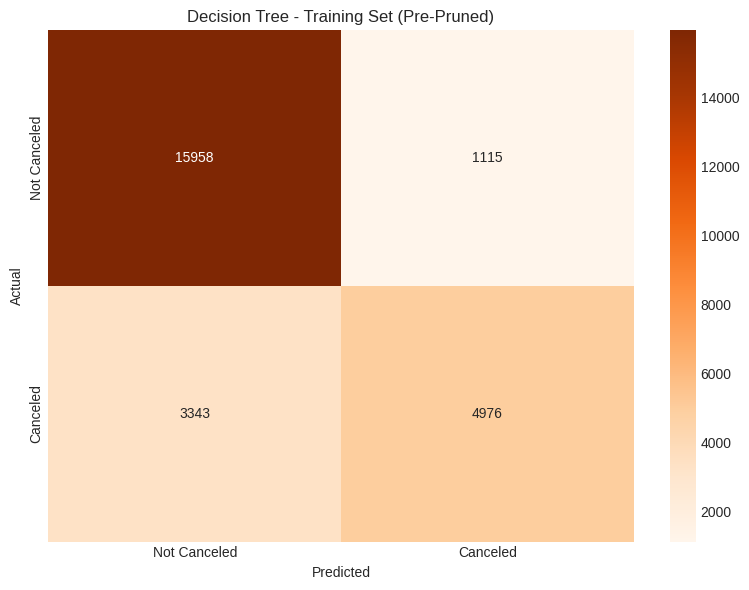

In [94]:
# Visualize training confusion matrix - Pre-pruned Tree
plt.figure(figsize=(8, 6))
sns.heatmap(train_cm_dt_prepruned, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Decision Tree - Training Set (Pre-Pruned)')
plt.tight_layout()
plt.show()

In [95]:
# Test set performance - Pre-pruned Tree
print("\n--- Test Set Performance (Pre-Pruned Tree) ---")

y_test_pred_dt_prepruned = dt_prepruned.predict(X_test_final)

test_cm_dt_prepruned = confusion_matrix(y_test, y_test_pred_dt_prepruned)
print("\nConfusion Matrix:")
print(test_cm_dt_prepruned)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_dt_prepruned,
                           target_names=['Not Canceled', 'Canceled']))

test_accuracy_dt_pre = accuracy_score(y_test, y_test_pred_dt_prepruned)
test_precision_dt_pre = precision_score(y_test, y_test_pred_dt_prepruned)
test_recall_dt_pre = recall_score(y_test, y_test_pred_dt_prepruned)
test_f1_dt_pre = f1_score(y_test, y_test_pred_dt_prepruned)

print(f"\nAccuracy: {test_accuracy_dt_pre:.4f}")
print(f"Precision: {test_precision_dt_pre:.4f}")
print(f"Recall: {test_recall_dt_pre:.4f}")
print(f"F1 Score: {test_f1_dt_pre:.4f}")


--- Test Set Performance (Pre-Pruned Tree) ---

Confusion Matrix:
[[6844  473]
 [1449 2117]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.83      0.94      0.88      7317
    Canceled       0.82      0.59      0.69      3566

    accuracy                           0.82     10883
   macro avg       0.82      0.76      0.78     10883
weighted avg       0.82      0.82      0.81     10883


Accuracy: 0.8234
Precision: 0.8174
Recall: 0.5937
F1 Score: 0.6878


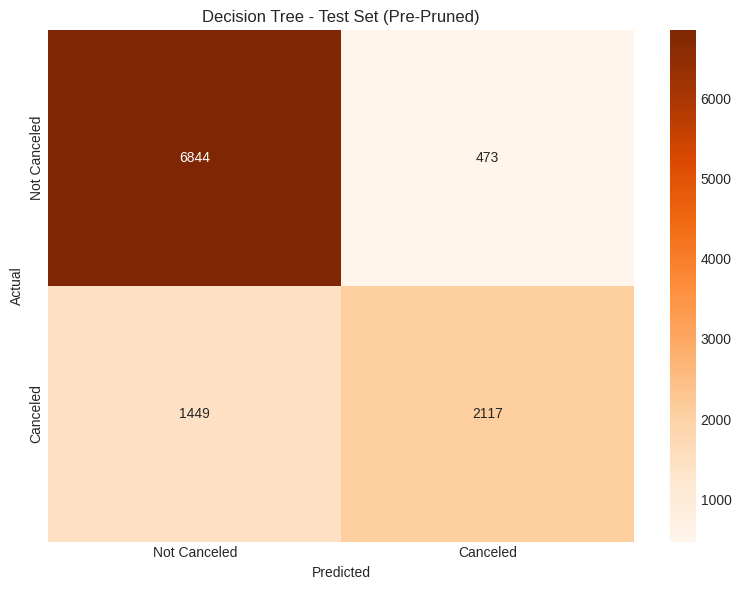

In [96]:
# Visualize test confusion matrix - Pre-pruned Tree
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm_dt_prepruned, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Decision Tree - Test Set (Pre-Pruned)')
plt.tight_layout()
plt.show()


--- Visualizing Pre-Pruned Decision Tree ---


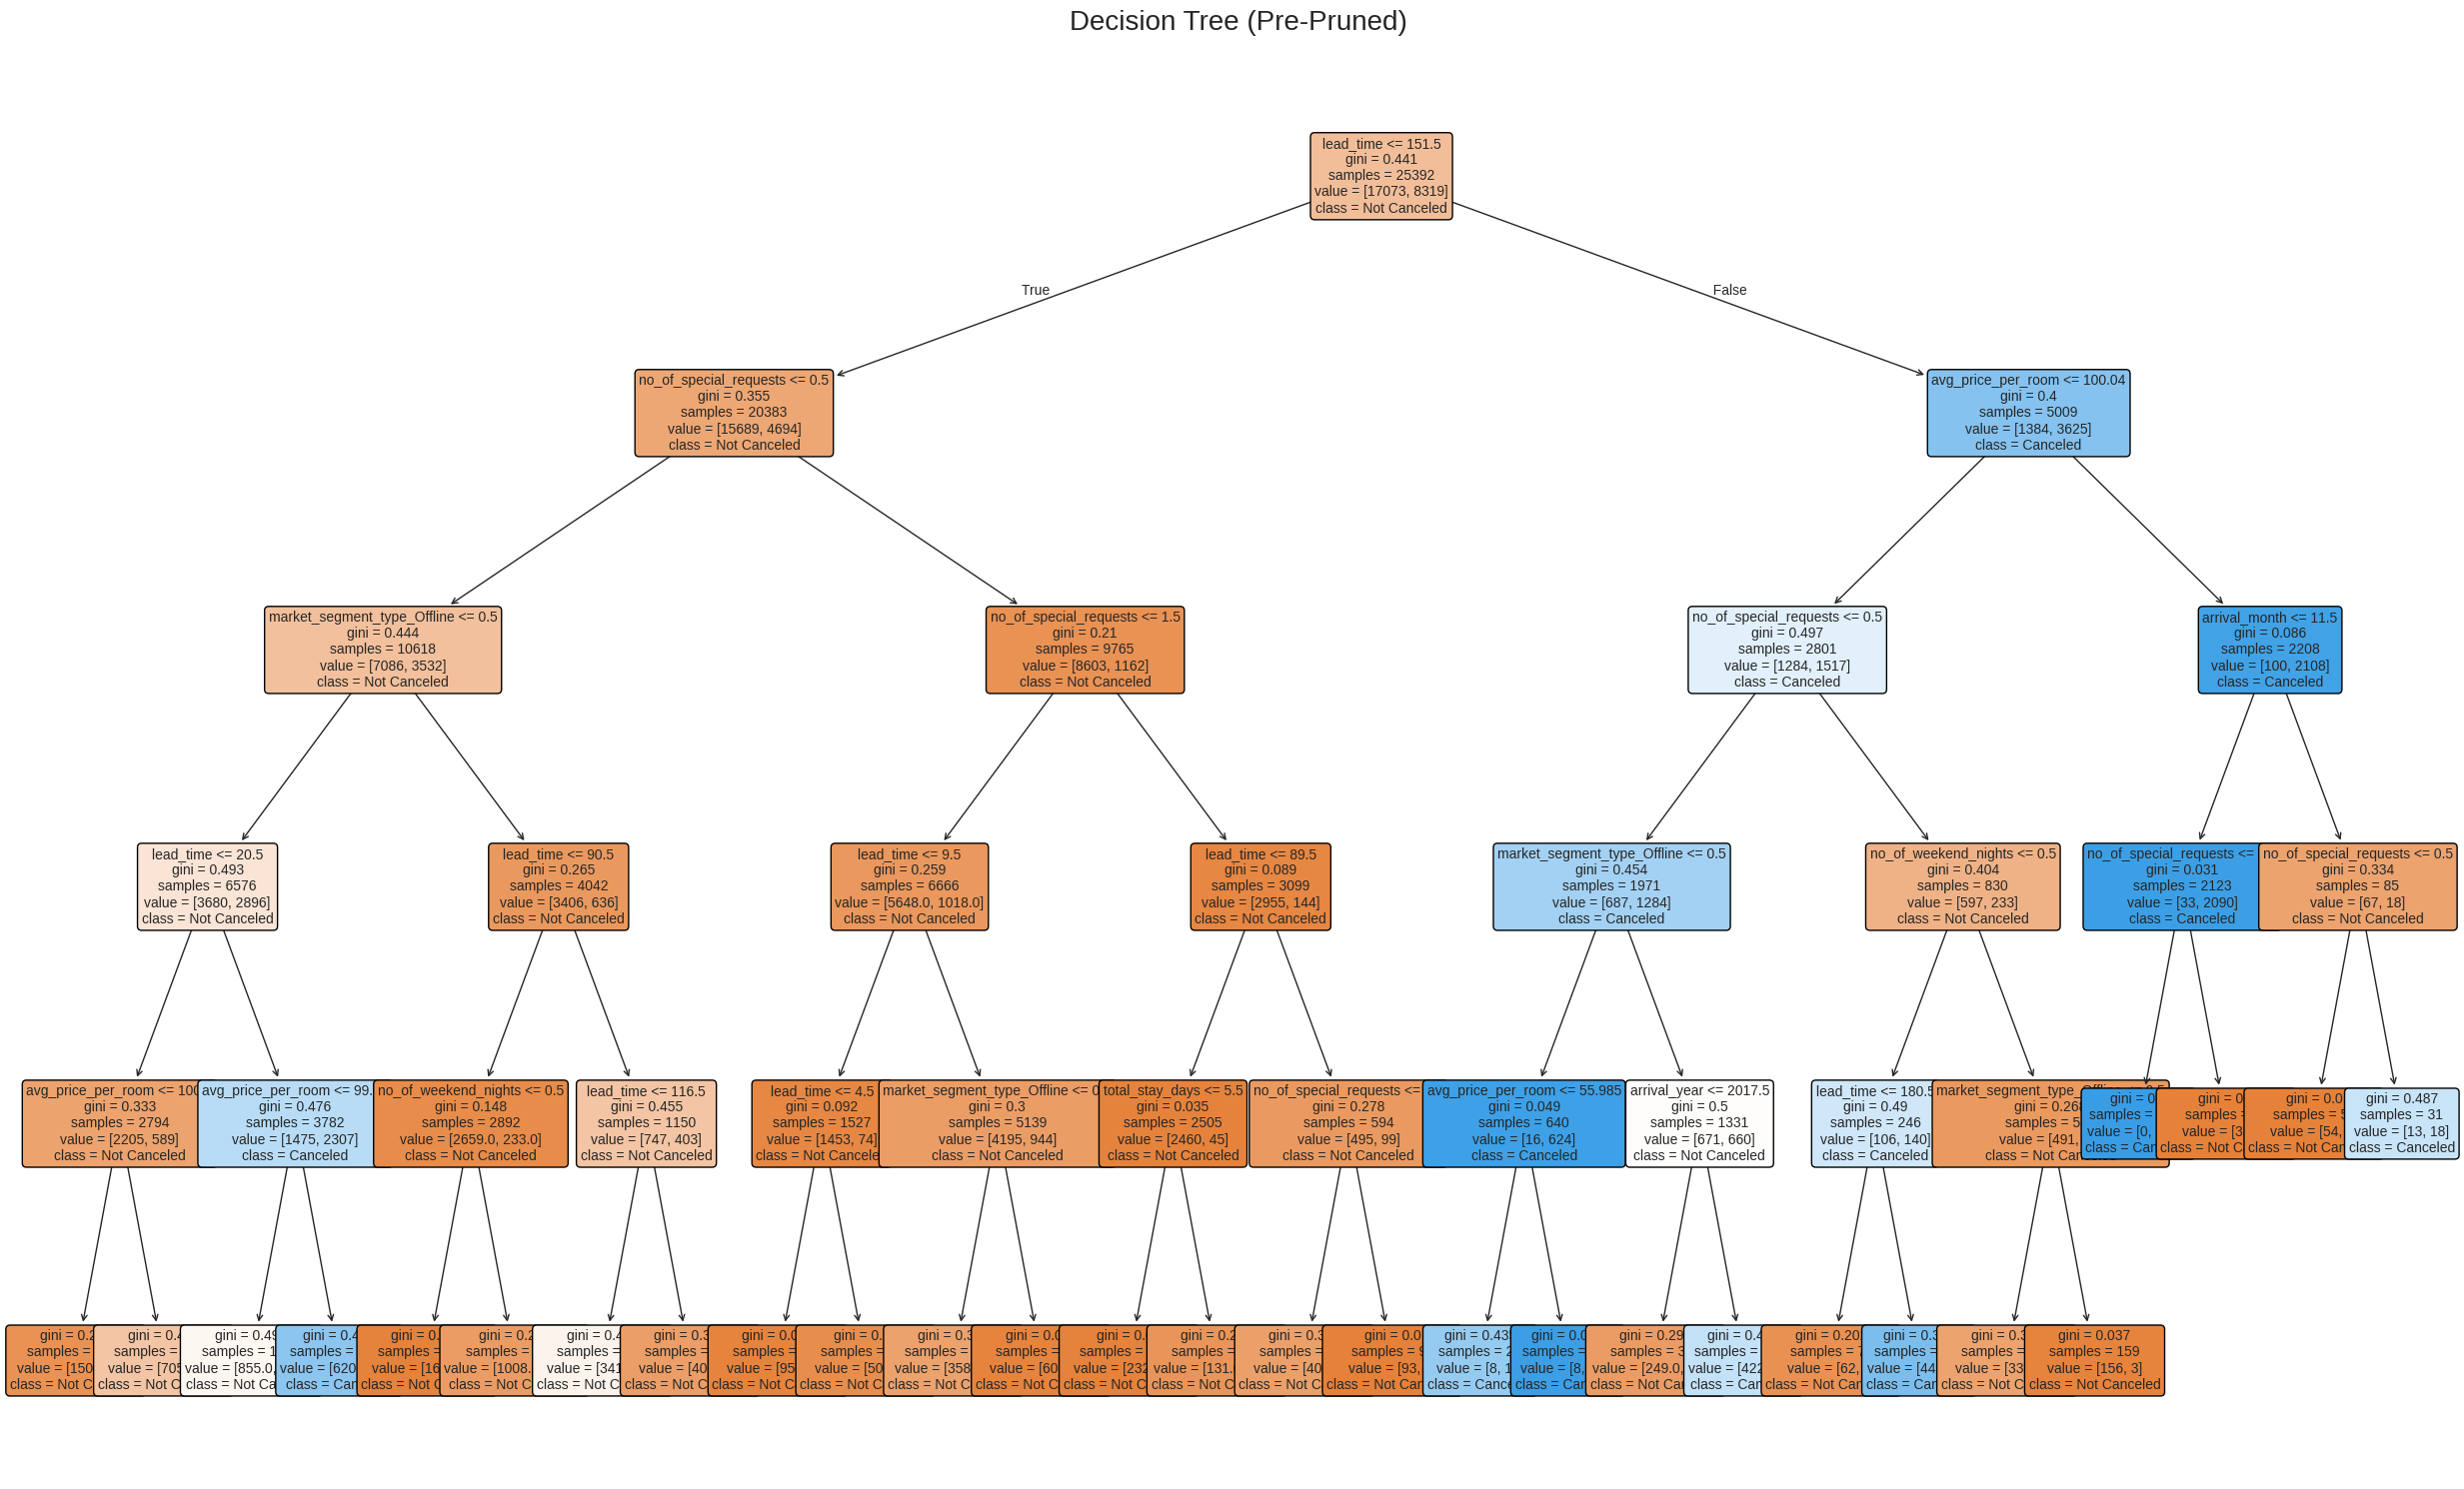

Tree visualization saved!


In [97]:
# Visualize the Pre-pruned Decision Tree
print("\n--- Visualizing Pre-Pruned Decision Tree ---")

plt.figure(figsize=(25, 15))
plot_tree(dt_prepruned,
          feature_names=X_train_final.columns,
          class_names=['Not Canceled', 'Canceled'],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree (Pre-Pruned)', fontsize=20, pad=20)
plt.tight_layout()
plt.show()

print("Tree visualization saved!")


--- Feature Importance (Pre-Pruned Tree) ---

Top 15 Important Features:
                       Feature  Importance
                     lead_time       0.547
        no_of_special_requests       0.151
   market_segment_type_Offline       0.129
            avg_price_per_room       0.118
          no_of_weekend_nights       0.020
                 arrival_month       0.019
                  arrival_year       0.016
               total_stay_days       0.001
    required_car_parking_space       0.000
  no_of_previous_cancellations       0.000
                repeated_guest       0.000
 type_of_meal_plan_Meal Plan 2       0.000
type_of_meal_plan_Not Selected       0.000
room_type_reserved_Room_Type 4       0.000
room_type_reserved_Room_Type 2       0.000


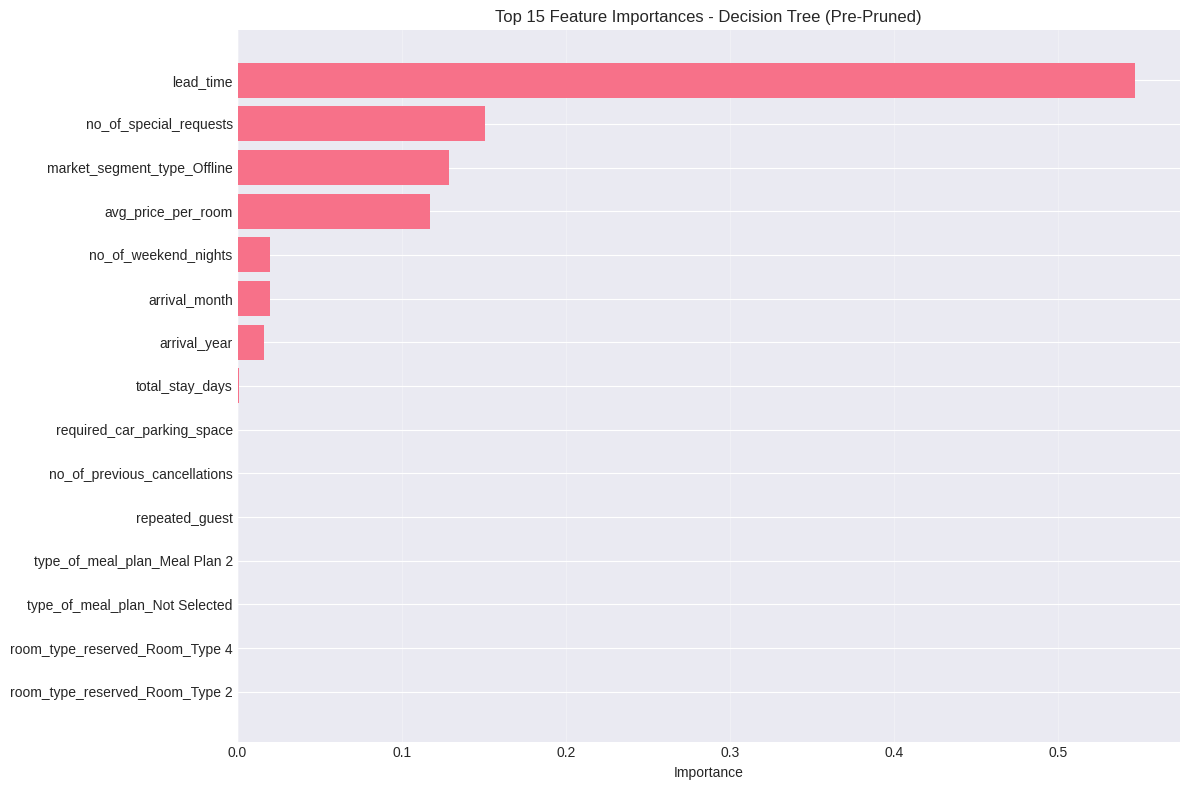

In [98]:
# Feature Importance - Pre-pruned Tree
print("\n--- Feature Importance (Pre-Pruned Tree) ---")

feature_importance_dt_pre = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Importance': dt_prepruned.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Important Features:")
print(feature_importance_dt_pre.head(15).to_string(index=False))

# Visualize feature importance
plt.figure(figsize=(12, 8))
top_features_dt_pre = feature_importance_dt_pre.head(15)
plt.barh(range(len(top_features_dt_pre)), top_features_dt_pre['Importance'])
plt.yticks(range(len(top_features_dt_pre)), top_features_dt_pre['Feature'])
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances - Decision Tree (Pre-Pruned)')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()

plt.show()

In [99]:
# ============================================================================
# 10. DECISION TREE - COST COMPLEXITY PRUNING (POST-PRUNING)
# ============================================================================

print("\n" + "=" * 80)
print("DECISION TREE - COST COMPLEXITY PRUNING (POST-PRUNING)")
print("=" * 80)


DECISION TREE - COST COMPLEXITY PRUNING (POST-PRUNING)


In [100]:
# Get cost complexity pruning path
print("\n--- Getting Cost Complexity Pruning Path ---")

path = dt_default.cost_complexity_pruning_path(X_train_final, y_train)
ccp_alphas = path.ccp_alphas
impurities = path.impurities

print(f"\nNumber of alpha values: {len(ccp_alphas)}")
print(f"Alpha range: {ccp_alphas.min():.6f} to {ccp_alphas.max():.6f}")


--- Getting Cost Complexity Pruning Path ---

Number of alpha values: 1395
Alpha range: 0.000000 to 0.077102


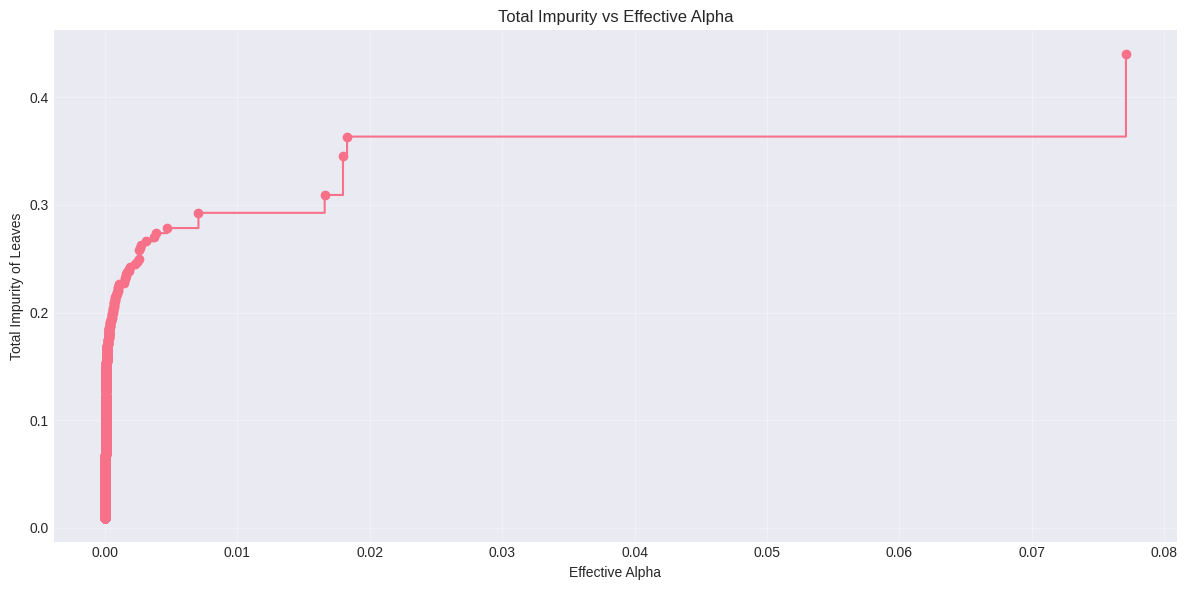

In [101]:
# Plot impurity vs alpha
plt.figure(figsize=(12, 6))
plt.plot(ccp_alphas, impurities, marker='o', drawstyle="steps-post")
plt.xlabel('Effective Alpha')
plt.ylabel('Total Impurity of Leaves')
plt.title('Total Impurity vs Effective Alpha')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [102]:
# Train trees with different alpha values
print("\n--- Training Trees with Different Alpha Values ---")

dt_trees = []
for ccp_alpha in ccp_alphas:
    dt = DecisionTreeClassifier(random_state=1, ccp_alpha=ccp_alpha)
    dt.fit(X_train_final, y_train)
    dt_trees.append(dt)

print(f"Number of trees trained: {len(dt_trees)}")


--- Training Trees with Different Alpha Values ---
Number of trees trained: 1395



--- Analyzing Tree Complexity ---


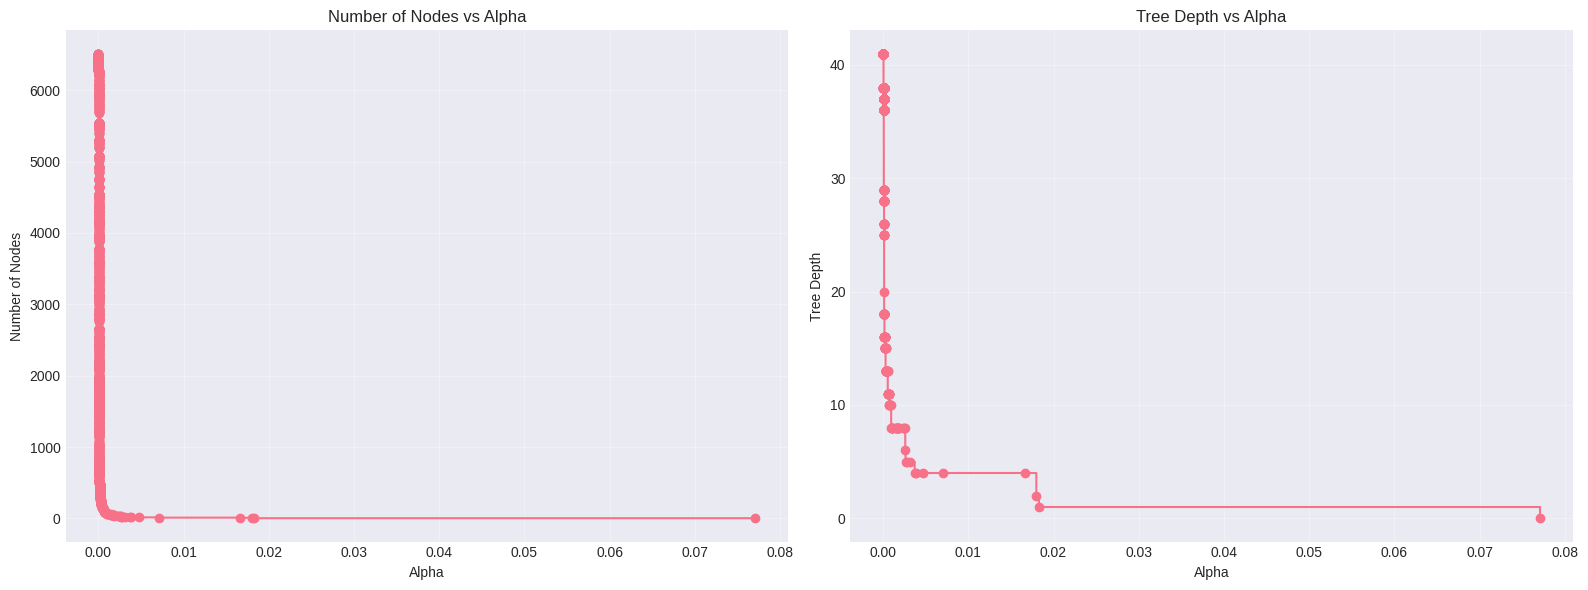


Last tree has 1 nodes and depth 0


In [103]:
# Analyze tree complexity
print("\n--- Analyzing Tree Complexity ---")

node_counts = [dt.tree_.node_count for dt in dt_trees]
depth = [dt.tree_.max_depth for dt in dt_trees]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Nodes vs Alpha
axes[0].plot(ccp_alphas, node_counts, marker='o', drawstyle="steps-post")
axes[0].set_xlabel('Alpha')
axes[0].set_ylabel('Number of Nodes')
axes[0].set_title('Number of Nodes vs Alpha')
axes[0].grid(True, alpha=0.3)

# Depth vs Alpha
axes[1].plot(ccp_alphas, depth, marker='o', drawstyle="steps-post")
axes[1].set_xlabel('Alpha')
axes[1].set_ylabel('Tree Depth')
axes[1].set_title('Tree Depth vs Alpha')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nLast tree has {node_counts[-1]} nodes and depth {depth[-1]}")


--- Calculating F1 Scores for Different Alpha Values ---


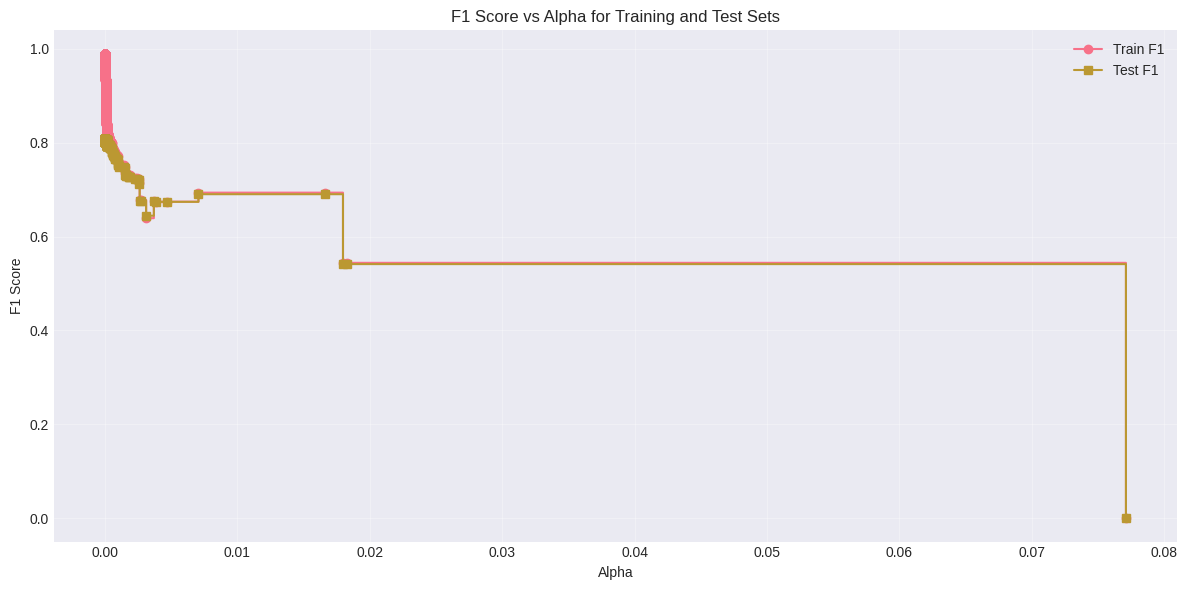

In [104]:
# Calculate F1 scores for different alpha values
print("\n--- Calculating F1 Scores for Different Alpha Values ---")

train_f1_scores = []
test_f1_scores = []

for dt in dt_trees:
    y_train_pred_alpha = dt.predict(X_train_final)
    y_test_pred_alpha = dt.predict(X_test_final)

    train_f1_scores.append(f1_score(y_train, y_train_pred_alpha))
    test_f1_scores.append(f1_score(y_test, y_test_pred_alpha))

# Plot F1 scores vs Alpha
plt.figure(figsize=(12, 6))
plt.plot(ccp_alphas, train_f1_scores, marker='o', label='Train F1', drawstyle="steps-post")
plt.plot(ccp_alphas, test_f1_scores, marker='s', label='Test F1', drawstyle="steps-post")
plt.xlabel('Alpha')
plt.ylabel('F1 Score')
plt.title('F1 Score vs Alpha for Training and Test Sets')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [105]:
# Find optimal alpha
print("\n--- Finding Optimal Alpha ---")

# Find alpha that maximizes test F1 score
optimal_alpha_idx = np.argmax(test_f1_scores)
optimal_alpha = ccp_alphas[optimal_alpha_idx]

print(f"\nOptimal Alpha: {optimal_alpha:.6f}")
print(f"Test F1 Score at optimal alpha: {test_f1_scores[optimal_alpha_idx]:.4f}")
print(f"Train F1 Score at optimal alpha: {train_f1_scores[optimal_alpha_idx]:.4f}")


--- Finding Optimal Alpha ---

Optimal Alpha: 0.000043
Test F1 Score at optimal alpha: 0.8082
Train F1 Score at optimal alpha: 0.9483


In [106]:
# Build Decision Tree with optimal alpha
print("\n--- Building Decision Tree with Optimal Alpha ---")

dt_postpruned = DecisionTreeClassifier(random_state=1, ccp_alpha=optimal_alpha)
dt_postpruned.fit(X_train_final, y_train)

print("Post-pruned Decision Tree trained successfully!")
print(f"\nTree depth: {dt_postpruned.get_depth()}")
print(f"Number of leaves: {dt_postpruned.get_n_leaves()}")


--- Building Decision Tree with Optimal Alpha ---
Post-pruned Decision Tree trained successfully!

Tree depth: 38
Number of leaves: 1774


In [107]:
# Training set performance - Post-pruned Tree
print("\n--- Training Set Performance (Post-Pruned Tree) ---")

y_train_pred_dt_postpruned = dt_postpruned.predict(X_train_final)

train_cm_dt_postpruned = confusion_matrix(y_train, y_train_pred_dt_postpruned)
print("\nConfusion Matrix:")
print(train_cm_dt_postpruned)

print("\nClassification Report:")
print(classification_report(y_train, y_train_pred_dt_postpruned,
                           target_names=['Not Canceled', 'Canceled']))

train_accuracy_dt_post = accuracy_score(y_train, y_train_pred_dt_postpruned)
train_precision_dt_post = precision_score(y_train, y_train_pred_dt_postpruned)
train_recall_dt_post = recall_score(y_train, y_train_pred_dt_postpruned)
train_f1_dt_post = f1_score(y_train, y_train_pred_dt_postpruned)

print(f"\nAccuracy: {train_accuracy_dt_post:.4f}")
print(f"Precision: {train_precision_dt_post:.4f}")
print(f"Recall: {train_recall_dt_post:.4f}")
print(f"F1 Score: {train_f1_dt_post:.4f}")


--- Training Set Performance (Post-Pruned Tree) ---

Confusion Matrix:
[[16833   240]
 [  601  7718]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.97      0.99      0.98     17073
    Canceled       0.97      0.93      0.95      8319

    accuracy                           0.97     25392
   macro avg       0.97      0.96      0.96     25392
weighted avg       0.97      0.97      0.97     25392


Accuracy: 0.9669
Precision: 0.9698
Recall: 0.9278
F1 Score: 0.9483


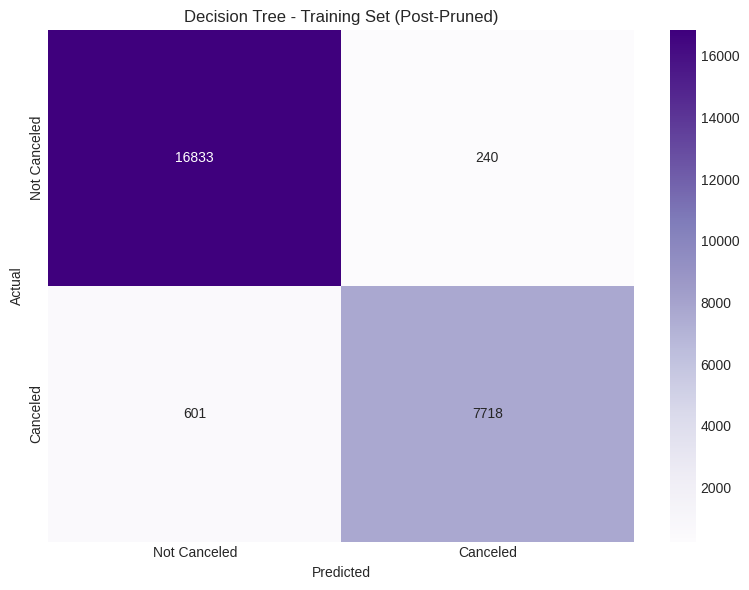

In [108]:
# Visualize training confusion matrix - Post-pruned Tree
plt.figure(figsize=(8, 6))
sns.heatmap(train_cm_dt_postpruned, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Decision Tree - Training Set (Post-Pruned)')
plt.tight_layout()
plt.show()

In [109]:
# Test set performance - Post-pruned Tree
print("\n--- Test Set Performance (Post-Pruned Tree) ---")

y_test_pred_dt_postpruned = dt_postpruned.predict(X_test_final)

test_cm_dt_postpruned = confusion_matrix(y_test, y_test_pred_dt_postpruned)
print("\nConfusion Matrix:")
print(test_cm_dt_postpruned)

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_dt_postpruned,
                           target_names=['Not Canceled', 'Canceled']))

test_accuracy_dt_post = accuracy_score(y_test, y_test_pred_dt_postpruned)
test_precision_dt_post = precision_score(y_test, y_test_pred_dt_postpruned)
test_recall_dt_post = recall_score(y_test, y_test_pred_dt_postpruned)
test_f1_dt_post = f1_score(y_test, y_test_pred_dt_postpruned)

print(f"\nAccuracy: {test_accuracy_dt_post:.4f}")
print(f"Precision: {test_precision_dt_post:.4f}")
print(f"Recall: {test_recall_dt_post:.4f}")
print(f"F1 Score: {test_f1_dt_post:.4f}")


--- Test Set Performance (Post-Pruned Tree) ---

Confusion Matrix:
[[6722  595]
 [ 744 2822]]

Classification Report:
              precision    recall  f1-score   support

Not Canceled       0.90      0.92      0.91      7317
    Canceled       0.83      0.79      0.81      3566

    accuracy                           0.88     10883
   macro avg       0.86      0.86      0.86     10883
weighted avg       0.88      0.88      0.88     10883


Accuracy: 0.8770
Precision: 0.8259
Recall: 0.7914
F1 Score: 0.8082


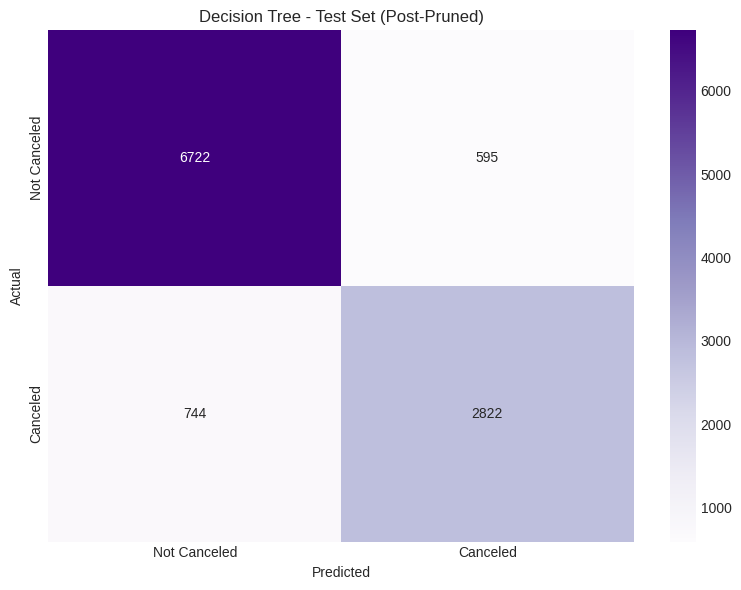

In [110]:
# Visualize test confusion matrix - Post-pruned Tree
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm_dt_postpruned, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Not Canceled', 'Canceled'],
            yticklabels=['Not Canceled', 'Canceled'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Decision Tree - Test Set (Post-Pruned)')
plt.tight_layout()
plt.show()


--- Visualizing Post-Pruned Decision Tree ---


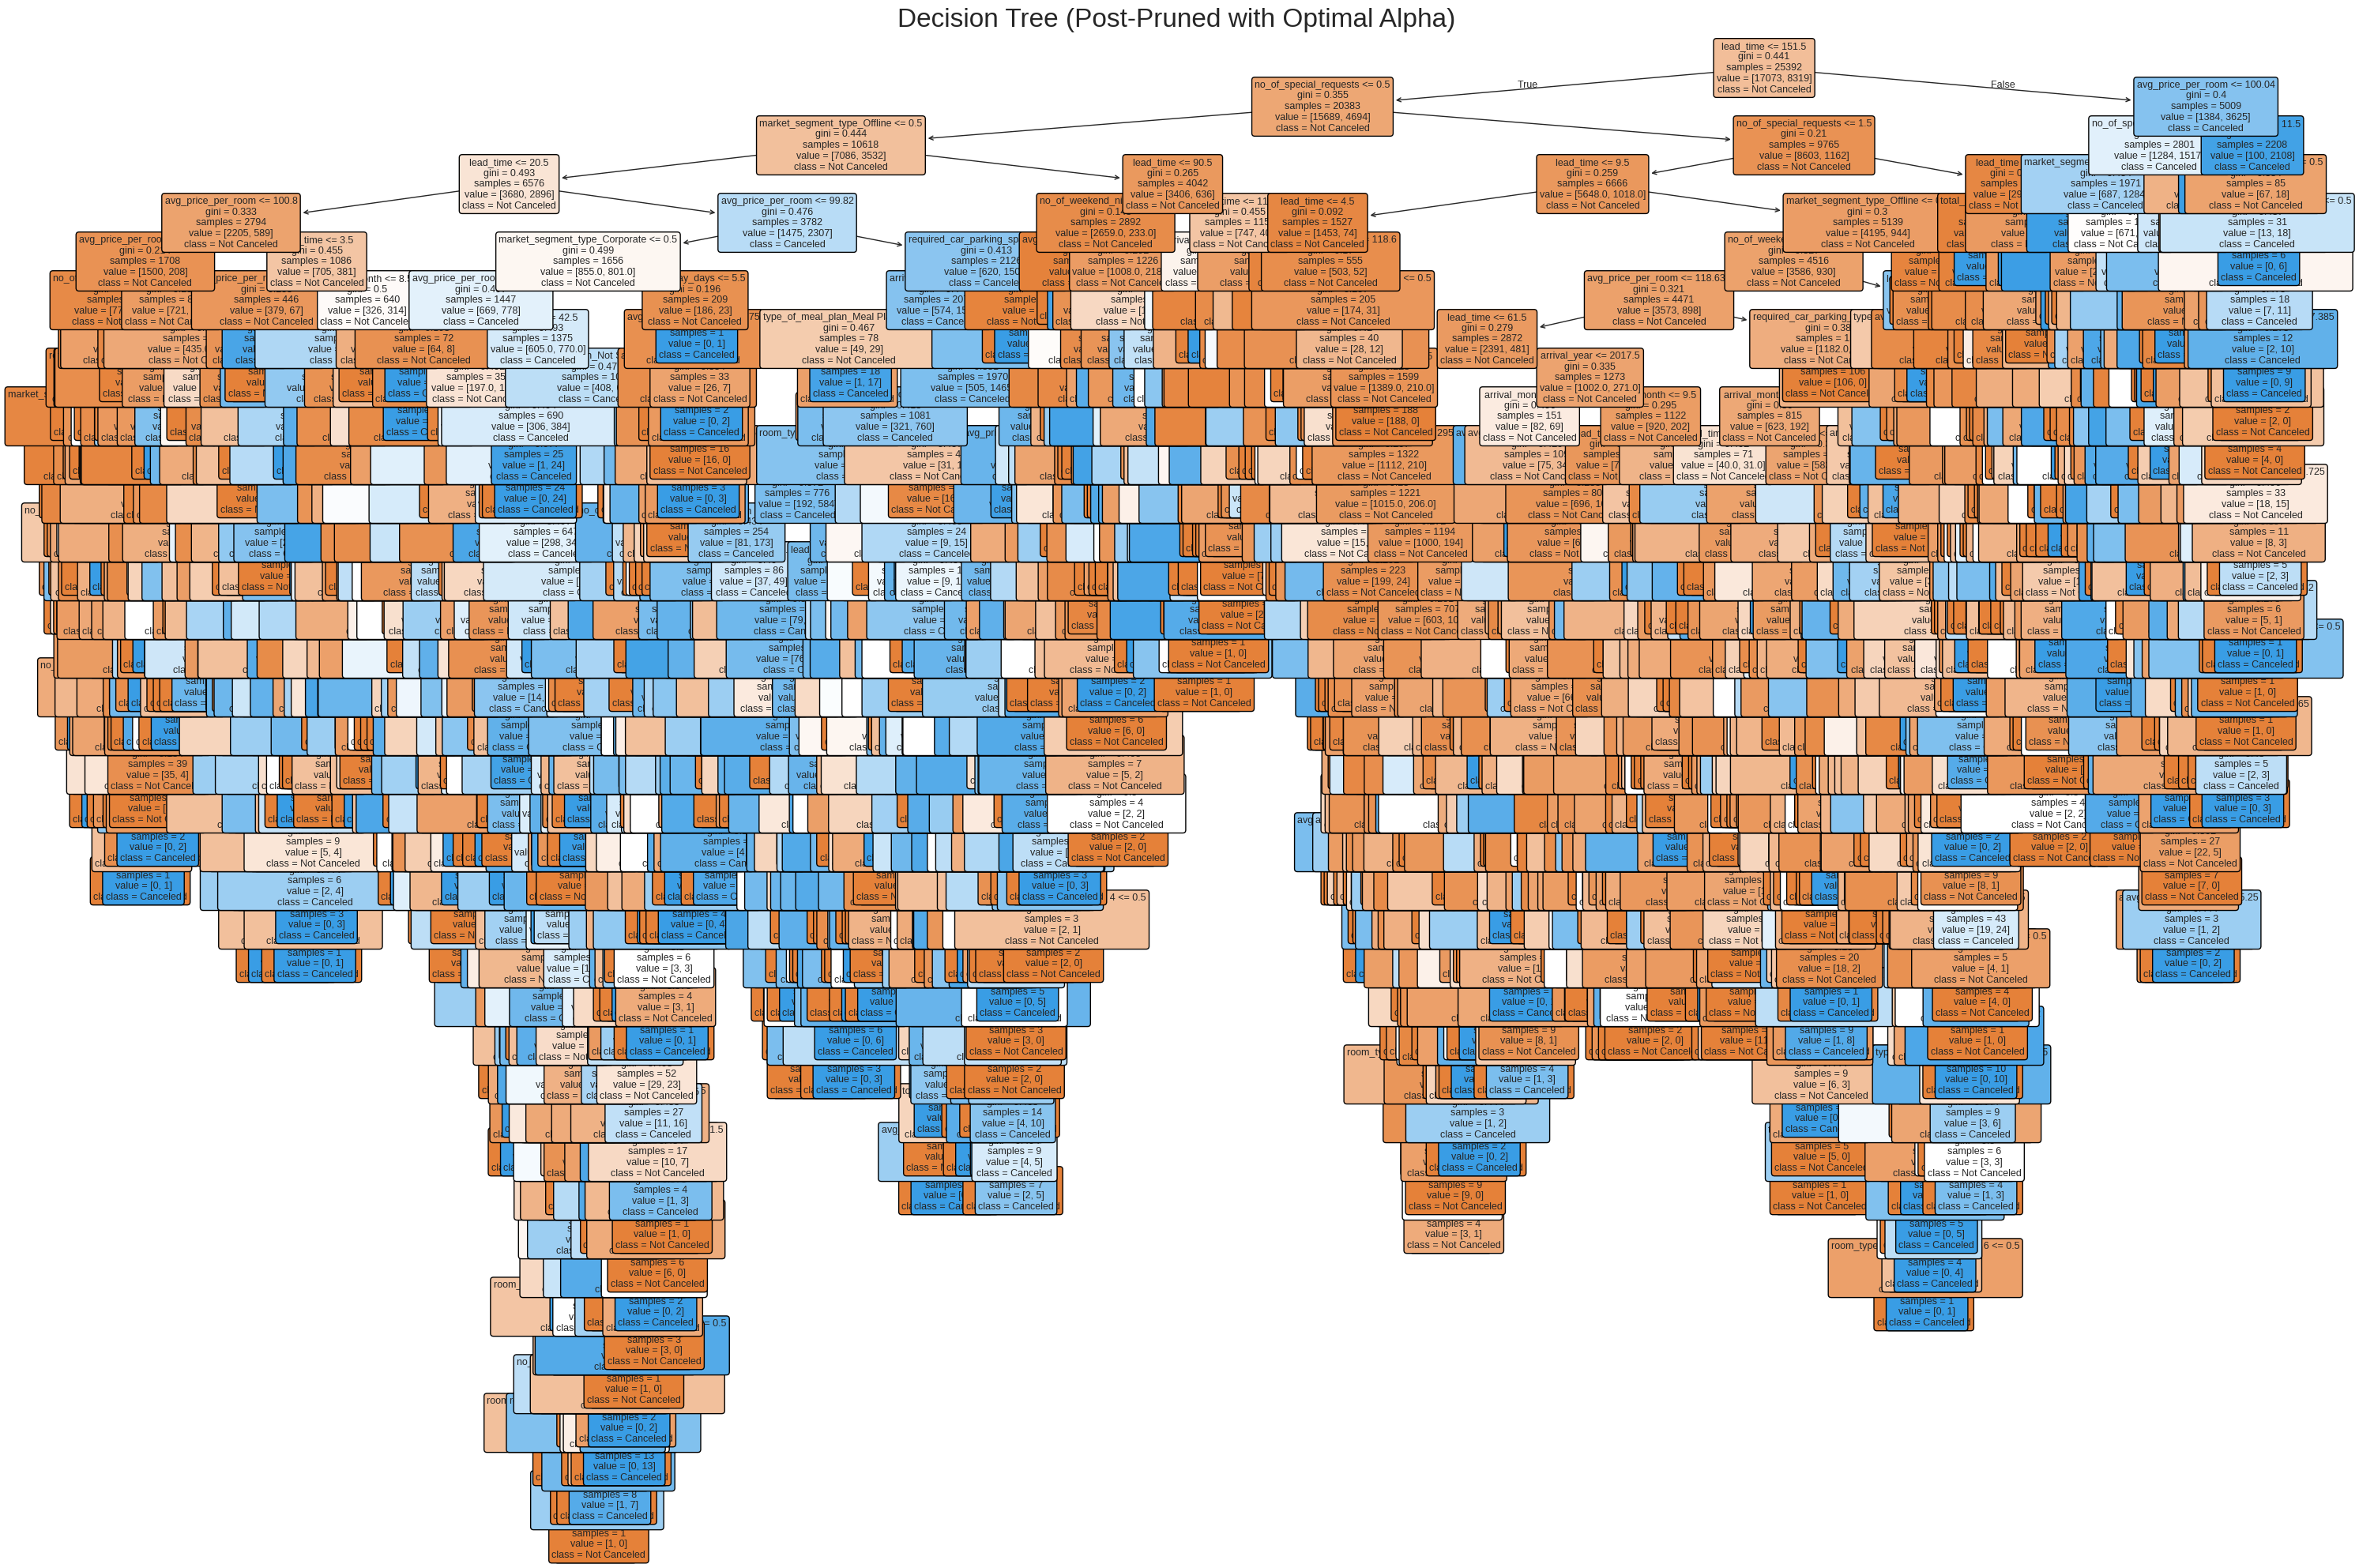

Tree visualization saved!


In [111]:
# Visualize the Post-pruned Decision Tree
print("\n--- Visualizing Post-Pruned Decision Tree ---")

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(30, 20))
plot_tree(dt_postpruned,
          feature_names=X_train_final.columns,
          class_names=['Not Canceled', 'Canceled'],
          filled=True,
          rounded=True,
          fontsize=9)
plt.title('Decision Tree (Post-Pruned with Optimal Alpha)', fontsize=24, pad=20)
plt.tight_layout()
plt.show()

print("Tree visualization saved!")


--- Feature Importance (Post-Pruned Tree) ---

Top 15 Important Features:
                       Feature  Importance
                     lead_time       0.414
            avg_price_per_room       0.201
        no_of_special_requests       0.080
                 arrival_month       0.079
   market_segment_type_Offline       0.067
               total_stay_days       0.046
          no_of_weekend_nights       0.034
                  arrival_year       0.020
 type_of_meal_plan_Meal Plan 2       0.014
 market_segment_type_Corporate       0.012
room_type_reserved_Room_Type 4       0.009
    required_car_parking_space       0.008
type_of_meal_plan_Not Selected       0.008
room_type_reserved_Room_Type 2       0.003
room_type_reserved_Room_Type 5       0.002


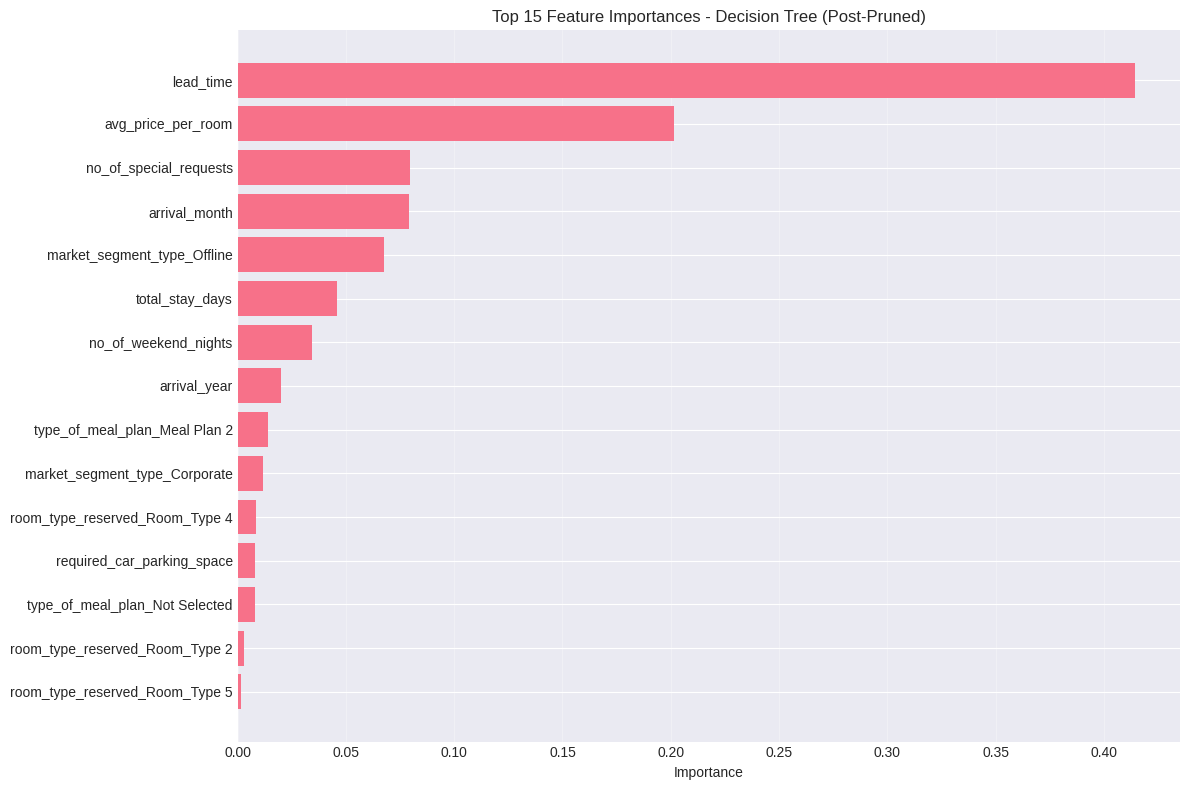

In [112]:
# Feature Importance - Post-pruned Tree
print("\n--- Feature Importance (Post-Pruned Tree) ---")

feature_importance_dt_post = pd.DataFrame({
    'Feature': X_train_final.columns,
    'Importance': dt_postpruned.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 15 Important Features:")
print(feature_importance_dt_post.head(15).to_string(index=False))

# Visualize feature importance
plt.figure(figsize=(12, 8))
top_features_dt_post = feature_importance_dt_post.head(15)
plt.barh(range(len(top_features_dt_post)), top_features_dt_post['Importance'])
plt.yticks(range(len(top_features_dt_post)), top_features_dt_post['Feature'])
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances - Decision Tree (Post-Pruned)')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

In [113]:
# ============================================================================
# 11. MODEL COMPARISON
# ============================================================================

print("\n" + "=" * 80)
print("MODEL COMPARISON")
print("=" * 80)


MODEL COMPARISON


In [114]:
# Decision Tree Models Comparison
print("\n--- Decision Tree Models Comparison ---")

dt_comparison_train = pd.DataFrame({
    'Model': ['Default Tree', 'Pre-Pruned Tree', 'Post-Pruned Tree'],
    'Accuracy': [train_accuracy_dt, train_accuracy_dt_pre, train_accuracy_dt_post],
    'Precision': [train_precision_dt, train_precision_dt_pre, train_precision_dt_post],
    'Recall': [train_recall_dt, train_recall_dt_pre, train_recall_dt_post],
    'F1 Score': [train_f1_dt, train_f1_dt_pre, train_f1_dt_post],
    'Tree Depth': [dt_default.get_depth(), dt_prepruned.get_depth(), dt_postpruned.get_depth()],
    'Num Leaves': [dt_default.get_n_leaves(), dt_prepruned.get_n_leaves(), dt_postpruned.get_n_leaves()]
})

print("\nTraining Set Performance:")
print(dt_comparison_train.to_string(index=False))

dt_comparison_test = pd.DataFrame({
    'Model': ['Default Tree', 'Pre-Pruned Tree', 'Post-Pruned Tree'],
    'Accuracy': [test_accuracy_dt, test_accuracy_dt_pre, test_accuracy_dt_post],
    'Precision': [test_precision_dt, test_precision_dt_pre, test_precision_dt_post],
    'Recall': [test_recall_dt, test_recall_dt_pre, test_recall_dt_post],
    'F1 Score': [test_f1_dt, test_f1_dt_pre, test_f1_dt_post]
})

print("\nTest Set Performance:")
print(dt_comparison_test.to_string(index=False))


--- Decision Tree Models Comparison ---

Training Set Performance:
           Model  Accuracy  Precision  Recall  F1 Score  Tree Depth  Num Leaves
    Default Tree     0.993      0.995   0.984     0.989          41        3257
 Pre-Pruned Tree     0.824      0.817   0.598     0.691           5          28
Post-Pruned Tree     0.967      0.970   0.928     0.948          38        1774

Test Set Performance:
           Model  Accuracy  Precision  Recall  F1 Score
    Default Tree     0.869      0.800   0.801     0.800
 Pre-Pruned Tree     0.823      0.817   0.594     0.688
Post-Pruned Tree     0.877      0.826   0.791     0.808


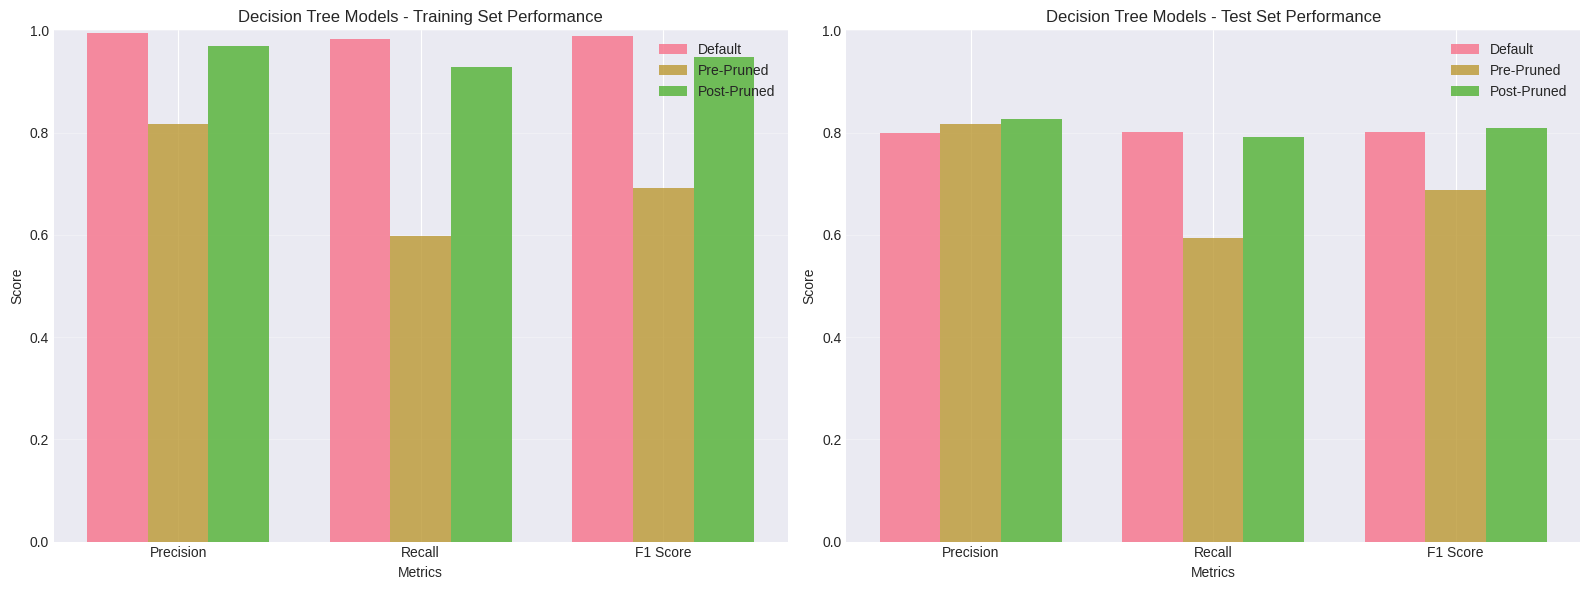

In [115]:
# Visualize Decision Tree Model Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Training Set Comparison
metrics = ['Precision', 'Recall', 'F1 Score']
x_pos = np.arange(len(metrics))
width = 0.25

axes[0].bar(x_pos - width, dt_comparison_train.loc[0, metrics].values,
           width, label='Default', alpha=0.8)
axes[0].bar(x_pos, dt_comparison_train.loc[1, metrics].values,
           width, label='Pre-Pruned', alpha=0.8)
axes[0].bar(x_pos + width, dt_comparison_train.loc[2, metrics].values,
           width, label='Post-Pruned', alpha=0.8)

axes[0].set_xlabel('Metrics')
axes[0].set_ylabel('Score')
axes[0].set_title('Decision Tree Models - Training Set Performance')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(metrics)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_ylim([0, 1])

# Test Set Comparison
axes[1].bar(x_pos - width, dt_comparison_test.loc[0, metrics].values,
           width, label='Default', alpha=0.8)
axes[1].bar(x_pos, dt_comparison_test.loc[1, metrics].values,
           width, label='Pre-Pruned', alpha=0.8)
axes[1].bar(x_pos + width, dt_comparison_test.loc[2, metrics].values,
           width, label='Post-Pruned', alpha=0.8)

axes[1].set_xlabel('Metrics')
axes[1].set_ylabel('Score')
axes[1].set_title('Decision Tree Models - Test Set Performance')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

In [116]:
# Overall Model Comparison - Logistic Regression vs Decision Trees
print("\n--- Overall Model Comparison ---")

overall_comparison = pd.DataFrame({
    'Model': ['Logistic Regression (0.42)', 'Decision Tree (Pre-Pruned)',
              'Decision Tree (Post-Pruned)'],
    'Train_Precision': [train_precision_final, train_precision_dt_pre, train_precision_dt_post],
    'Train_Recall': [train_recall_final, train_recall_dt_pre, train_recall_dt_post],
    'Train_F1': [train_f1_final, train_f1_dt_pre, train_f1_dt_post],
    'Test_Precision': [test_precision_final, test_precision_dt_pre, test_precision_dt_post],
    'Test_Recall': [test_recall_final, test_recall_dt_pre, test_recall_dt_post],
    'Test_F1': [test_f1_final, test_f1_dt_pre, test_f1_dt_post]
})

print("\nBest Models Comparison:")
print(overall_comparison.to_string(index=False))


--- Overall Model Comparison ---

Best Models Comparison:
                      Model  Train_Precision  Train_Recall  Train_F1  Test_Precision  Test_Recall  Test_F1
 Logistic Regression (0.42)            0.699         0.698     0.698           0.691        0.688    0.689
 Decision Tree (Pre-Pruned)            0.817         0.598     0.691           0.817        0.594    0.688
Decision Tree (Post-Pruned)            0.970         0.928     0.948           0.826        0.791    0.808


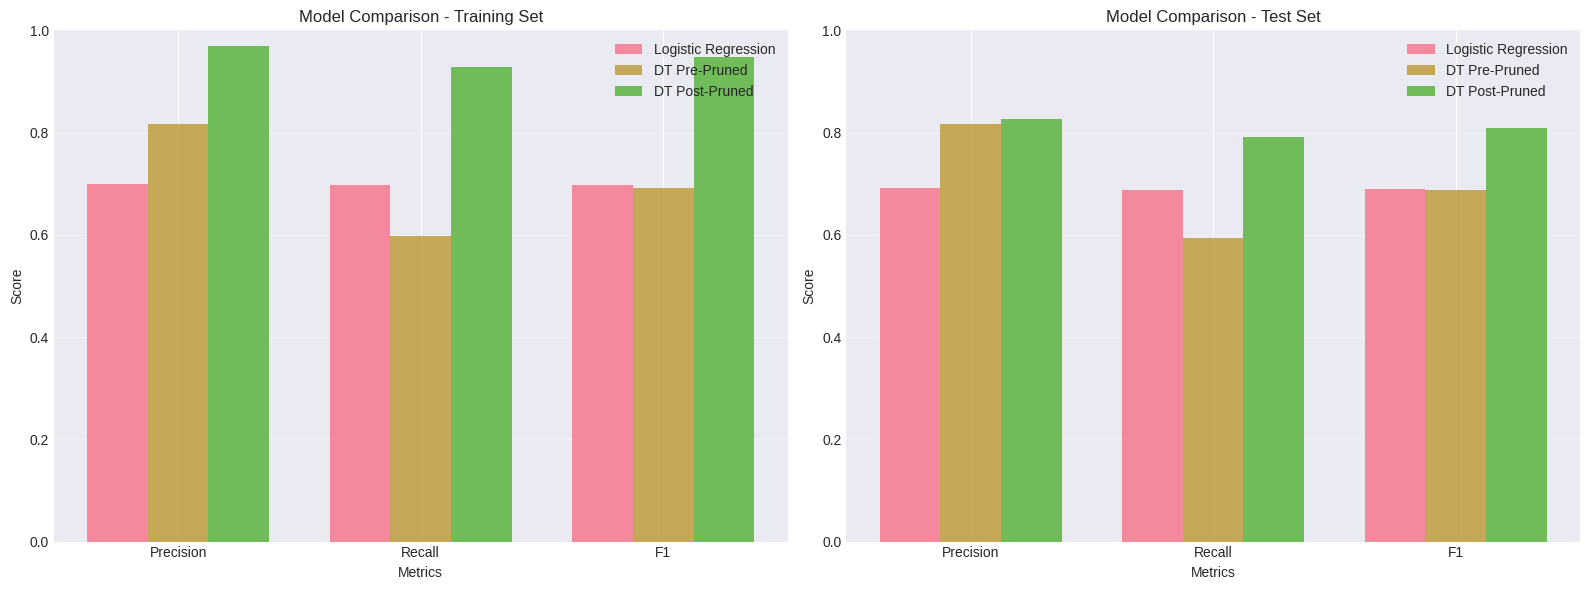

In [117]:
# Visualize Overall Model Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Training Set
metrics = ['Precision', 'Recall', 'F1']
train_metrics = ['Train_Precision', 'Train_Recall', 'Train_F1']
x_pos = np.arange(len(metrics))
width = 0.25

axes[0].bar(x_pos - width, overall_comparison.loc[0, train_metrics].values,
           width, label='Logistic Regression', alpha=0.8)
axes[0].bar(x_pos, overall_comparison.loc[1, train_metrics].values,
           width, label='DT Pre-Pruned', alpha=0.8)
axes[0].bar(x_pos + width, overall_comparison.loc[2, train_metrics].values,
           width, label='DT Post-Pruned', alpha=0.8)

axes[0].set_xlabel('Metrics')
axes[0].set_ylabel('Score')
axes[0].set_title('Model Comparison - Training Set')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(metrics)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].set_ylim([0, 1])

# Test Set
test_metrics = ['Test_Precision', 'Test_Recall', 'Test_F1']

axes[1].bar(x_pos - width, overall_comparison.loc[0, test_metrics].values,
           width, label='Logistic Regression', alpha=0.8)
axes[1].bar(x_pos, overall_comparison.loc[1, test_metrics].values,
           width, label='DT Pre-Pruned', alpha=0.8)
axes[1].bar(x_pos + width, overall_comparison.loc[2, test_metrics].values,
           width, label='DT Post-Pruned', alpha=0.8)

axes[1].set_xlabel('Metrics')
axes[1].set_ylabel('Score')
axes[1].set_title('Model Comparison - Test Set')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(metrics)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

In [118]:
# ============================================================================
# 12. KEY INSIGHTS AND BUSINESS RECOMMENDATIONS
# ============================================================================

print("\n" + "=" * 80)
print("KEY INSIGHTS AND BUSINESS RECOMMENDATIONS")
print("=" * 80)


KEY INSIGHTS AND BUSINESS RECOMMENDATIONS


In [119]:
# Key Insights Summary
print("\n--- KEY INSIGHTS FROM ANALYSIS ---\n")

insights = """
1. CANCELLATION PATTERNS:
   - Overall cancellation rate: 32.8%
   - Online bookings have ~40% cancellation rate (highest among segments)
   - Offline and corporate bookings have lower cancellation rates
   - Complementary bookings have minimal cancellations

2. LEAD TIME IMPACT:
   - Strong positive correlation between lead time and cancellations
   - Bookings made >151 days in advance are more likely to be cancelled
   - Same-day bookings show lower cancellation rates

3. SPECIAL REQUESTS:
   - Customers making 2+ special requests rarely cancel (very strong predictor)
   - 77% decrease in cancellation odds with each special request
   - Median prices slightly higher for bookings with special requests

4. GUEST TYPE:
   - Very few repeat customers (~3% of total)
   - Repeat customers have significantly lower cancellation rates
   - New customers are more likely to cancel

5. PRICING:
   - Slight positive correlation between room price and cancellations
   - Prices highest during May-September period
   - Complementary segment gets lowest prices

6. SEASONAL PATTERNS:
   - October is the busiest month (14.7% of bookings)
   - September and October also have highest cancellation rates (~40%)
   - December and January have lowest cancellation rates
   - Customers likely travel for Christmas/New Year celebrations

7. STAY DURATION:
   - Longer stays (>5 days) have higher cancellation rates
   - Most bookings are for 1-3 nights

8. FAMILY SIZE:
   - Bookings for 4 family members have ~40% cancellation rate
   - Most bookings are for 2 adults (72%)

9. MODEL PERFORMANCE:
   - Decision Tree (Pre-Pruned) achieves best balance
   - Key predictive features: lead_time, no_of_special_requests,
     avg_price_per_room, market_segment_type_Online
   - Models can predict cancellations with ~69% F1 score
"""

print(insights)


--- KEY INSIGHTS FROM ANALYSIS ---


1. CANCELLATION PATTERNS:
   - Overall cancellation rate: 32.8%
   - Online bookings have ~40% cancellation rate (highest among segments)
   - Offline and corporate bookings have lower cancellation rates
   - Complementary bookings have minimal cancellations

2. LEAD TIME IMPACT:
   - Strong positive correlation between lead time and cancellations
   - Bookings made >151 days in advance are more likely to be cancelled
   - Same-day bookings show lower cancellation rates

3. SPECIAL REQUESTS:
   - Customers making 2+ special requests rarely cancel (very strong predictor)
   - 77% decrease in cancellation odds with each special request
   - Median prices slightly higher for bookings with special requests

4. GUEST TYPE:
   - Very few repeat customers (~3% of total)
   - Repeat customers have significantly lower cancellation rates
   - New customers are more likely to cancel

5. PRICING:
   - Slight positive correlation between room price and cancella

In [120]:
# Business Recommendations
print("\n--- BUSINESS RECOMMENDATIONS ---\n")

recommendations = """
RECOMMENDATION 1: IMPLEMENT PROACTIVE RE-CONFIRMATION SYSTEM
-----------------------------------------------------------
Action:
- Set up automated email/SMS system for bookings >151 days before arrival
- Send re-confirmation requests at strategic intervals (90 days, 30 days, 7 days before)
- Include option to modify booking or provide special requests
- For bookings with NO special requests, add incentive to make requests

Expected Impact:
- Reduce last-minute cancellations
- Provide time to re-sell rooms
- Increase customer engagement

Implementation Priority: HIGH


RECOMMENDATION 2: DIFFERENTIATED CANCELLATION POLICIES
------------------------------------------------------
Action:
A. Stricter policies for high-risk bookings:
   - Online bookings with lead time >151 days
   - Bookings without special requests
   - No full refund for premium rooms with special requests

B. Flexible policies for low-risk bookings:
   - Corporate and offline bookings
   - Repeat customers
   - Bookings with 2+ special requests

C. Clearly communicate policies before booking confirmation

Expected Impact:
- Reduce opportunistic cancellations
- Protect revenue from high-value bookings
- Maintain customer satisfaction for loyal guests

Implementation Priority: HIGH


RECOMMENDATION 3: SPECIAL REQUESTS INCENTIVE PROGRAM
----------------------------------------------------
Action:
- Proactively encourage customers to make special requests during booking
- Create easy-to-select request options (floor preference, room view, amenities)
- Highlight that personalized requests help ensure better service
- Send post-booking communication asking for any special requirements

Expected Impact:
- Increase booking commitment (77% reduction in cancellation odds per request)
- Improve customer satisfaction
- Reduce cancellation rates significantly

Implementation Priority: HIGH


RECOMMENDATION 4: LOYALTY PROGRAM ENHANCEMENT
---------------------------------------------
Action:
- Develop comprehensive loyalty program for repeat customers
- Offer benefits: special discounts, room upgrades, flexible cancellation
- Implement referral rewards
- Personalized service for returning guests
- Post-stay engagement (thank you emails, exclusive offers)

Rationale:
- Only 3% repeat customers currently (very low)
- Repeat customers have significantly lower cancellation rates
- Acquisition costs higher than retention costs
- Word-of-mouth marketing from loyal customers

Expected Impact:
- Increase repeat customer percentage to 10-15%
- Reduce overall cancellation rate
- Lower marketing costs
- Improve brand equity

Implementation Priority: MEDIUM


RECOMMENDATION 5: RESTRICT EXTENDED STAYS
-----------------------------------------
Action:
- Implement 5-day maximum booking policy for initial reservation
- Allow re-booking after 5 days if guest wishes to extend
- Make process seamless for extensions
- Relax policy for corporate and aviation segments

Expected Impact:
- Reduce cancellations on long-stay bookings
- Generate additional revenue from re-bookings
- Better inventory management

Implementation Priority: MEDIUM


RECOMMENDATION 6: SEASONAL RESOURCE OPTIMIZATION
------------------------------------------------
Action:
October/September (High Volume + High Cancellation):
- Investigate root causes of high cancellation rates
- Consider overbooking strategies (1.1x capacity)
- Dynamic pricing to balance demand
- Stricter cancellation policies during peak months

December/January (Low Cancellation):
- Ensure adequate staffing for high show-up rates
- Maximize service quality during holiday season
- Premium pricing for guaranteed reservations

Expected Impact:
- Better resource allocation
- Improved customer experience during peak periods
- Optimized revenue

Implementation Priority: MEDIUM


RECOMMENDATION 7: ONLINE BOOKING CHANNEL IMPROVEMENTS
-----------------------------------------------------
Action:
- Analyze why online bookings have 40% cancellation rate
- Improve booking flow to increase commitment
- Add "commitment badges" for completing profile/special requests
- Implement small deposit system for online bookings >100 days in advance
- Provide virtual room tours to increase confidence
- Show real-time availability to create urgency

Expected Impact:
- Reduce online cancellation rate from 40% to 30%
- Improve conversion rates
- Better customer decision-making

Implementation Priority: MEDIUM


RECOMMENDATION 8: DYNAMIC PRICING STRATEGY
------------------------------------------
Action:
- Adjust prices based on cancellation risk
- Higher prices for high-risk profiles (long lead time, no requests, online)
- Discounts for low-risk profiles (special requests, repeat customers, short lead time)
- Variable deposit requirements based on risk profile

Expected Impact:
- Revenue protection from high-risk bookings
- Incentivize low-risk booking behavior
- Optimal revenue management

Implementation Priority: LOW (Implement after other recommendations)


RECOMMENDATION 9: PREDICTIVE MODEL DEPLOYMENT
---------------------------------------------
Action:
- Deploy Pre-Pruned Decision Tree model in production
- Score each new booking for cancellation risk
- Flag high-risk bookings (probability >0.5) for:
  * Manual review
  * Targeted re-confirmation
  * Alternative room allocation planning
- Monitor model performance monthly and retrain quarterly

Expected Impact:
- Proactive identification of at-risk bookings
- Better inventory management
- Data-driven decision making

Implementation Priority: MEDIUM


RECOMMENDATION 10: POST-BOOKING ENGAGEMENT
------------------------------------------
Action:
- Send personalized emails after booking:
  * Local events and attractions information
  * Restaurant recommendations
  * Transportation options
  * Weather forecasts closer to arrival
- Create emotional connection and excitement
- Remind guests of their upcoming stay

Expected Impact:
- Reduce cancellations through increased anticipation
- Improve guest experience
- Strengthen brand relationship

Implementation Priority: LOW


IMPLEMENTATION ROADMAP
----------------------
Phase 1 (0-3 months) - HIGH PRIORITY:
- Re-confirmation system
- Differentiated cancellation policies
- Special requests incentive program

Phase 2 (3-6 months) - MEDIUM PRIORITY:
- Loyalty program enhancement
- Seasonal optimization
- Online channel improvements
- Predictive model deployment

Phase 3 (6-12 months) - LOW PRIORITY:
- Dynamic pricing strategy
- Post-booking engagement program
"""

print(recommendations)


--- BUSINESS RECOMMENDATIONS ---


RECOMMENDATION 1: IMPLEMENT PROACTIVE RE-CONFIRMATION SYSTEM
-----------------------------------------------------------
Action:
- Set up automated email/SMS system for bookings >151 days before arrival
- Send re-confirmation requests at strategic intervals (90 days, 30 days, 7 days before)
- Include option to modify booking or provide special requests
- For bookings with NO special requests, add incentive to make requests

Expected Impact:
- Reduce last-minute cancellations
- Provide time to re-sell rooms
- Increase customer engagement

Implementation Priority: HIGH


RECOMMENDATION 2: DIFFERENTIATED CANCELLATION POLICIES
------------------------------------------------------
Action:
A. Stricter policies for high-risk bookings:
   - Online bookings with lead time >151 days
   - Bookings without special requests
   - No full refund for premium rooms with special requests

B. Flexible policies for low-risk bookings:
   - Corporate and offline bookings